# **Comeback Momentum, Chart Re-Entry, and Fandom Intensity Analysis of South Korea Top 50 Playlist**

## **1. Import Libraries**

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Date and Time Processing
from datetime import datetime

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 1200)

# Visualization Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


## **2. Load Dataset**

In [2]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

from google.colab import files
import io

# Upload the company-provided dataset
uploaded = files.upload()

# Load the uploaded CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    low_memory=False
)

print("Dataset loaded successfully!")
print("File Name:", file_name)
print("Dataset Shape:", df.shape)

Saving Atlantic_South_Korea.csv to Atlantic_South_Korea.csv
Dataset loaded successfully!
File Name: Atlantic_South_Korea.csv
Dataset Shape: (27800, 10)


## **3. Dataset Overview**

In [3]:
# ============================================================
# 3. DATASET OVERVIEW
# ============================================================

# Display the first five records
print("First Five Records:")
display(df.head())

# Display the last five records
print("\nLast Five Records:")
display(df.tail())

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display the number of rows and columns
print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

First Five Records:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,Like Crazy,Jimin,93,212241,single,6,False,https://i.scdn.co/image/ab67616d0000b2732b4607...
1,18-05-2024,2,UNFORGIVEN (feat. Nile Rodgers),LE SSERAFIM,87,182148,album,13,False,https://i.scdn.co/image/ab67616d0000b273d71fd7...
2,18-05-2024,3,Spicy,aespa,81,197040,single,6,False,https://i.scdn.co/image/ab67616d0000b27304878a...
3,18-05-2024,4,I AM,IVE,89,183853,album,11,False,https://i.scdn.co/image/ab67616d0000b27325ef3c...
4,18-05-2024,5,Queencard,(G)I-DLE,71,161240,single,6,False,https://i.scdn.co/image/ab67616d0000b27382dd24...



Last Five Records:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
27795,27-11-2025,46,My Name is Malguem,QWER,61,188320,single,8,False,https://i.scdn.co/image/ab67616d0000b273df4093...
27796,27-11-2025,47,CROOKED,G-DRAGON,65,224792,album,12,False,https://i.scdn.co/image/ab67616d0000b2733dbdbd...
27797,27-11-2025,48,squabble up,Kendrick Lamar,86,157992,album,12,True,https://i.scdn.co/image/ab67616d0000b273d99850...
27798,27-11-2025,49,Armageddon,aespa,72,196466,album,10,False,https://i.scdn.co/image/ab67616d0000b273c60843...
27799,27-11-2025,50,Tick-Tack,ILLIT,74,129468,single,5,False,https://i.scdn.co/image/ab67616d0000b273fc2fff...



Dataset Columns:
['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             27800 non-null  object
 1   position         27800 non-null  int64 
 2   song             27800 non-null  object
 3   artist           27800 non-null  object
 4   popularity       27800 non-null  int64 
 5   duration_ms      27800 non-null  int64 
 6   album_type       27800 non-null  object
 7   total_tracks     27800 non-null  int64 
 8   is_explicit      27800 non-null  bool  
 9   album_cover_url  27800 non-null  object
dtypes: bool(1), int64(4), object(5)
memory usage: 1.9+ MB

Total Rows: 27800
Total Columns: 10


## **4. Data Quality Assessment**

In [4]:
# ============================================================
# 4.1 MISSING VALUES ANALYSIS
# ============================================================

# Calculate missing values
missing_values = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage.round(2)
})

print("Missing Values Analysis")
print("=" * 60)

display(missing_summary)

print("\nTotal Missing Values:", int(df.isnull().sum().sum()))

Missing Values Analysis


,Missing Values,Missing Percentage (%)
date,0,0.0
position,0,0.0
song,0,0.0
artist,0,0.0
popularity,0,0.0
duration_ms,0,0.0
album_type,0,0.0
total_tracks,0,0.0
is_explicit,0,0.0
album_cover_url,0,0.0



Total Missing Values: 0


In [5]:
# ============================================================
# 4.2 DUPLICATE RECORDS ANALYSIS
# ============================================================

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Duplicate Records Analysis")
print("=" * 60)
print("Total Duplicate Rows:", duplicate_count)

if duplicate_count > 0:
    print("\nSample Duplicate Records:")
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate records found!")

Duplicate Records Analysis
Total Duplicate Rows: 16

Sample Duplicate Records:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14350,01-03-2025,1,Like Crazy,Jimin,92,212241,single,6,False,https://i.scdn.co/image/ab67616d0000b2732b4607...
14351,01-03-2025,2,Seven (feat. Latto) (Explicit Ver.),Jung Kook,90,183550,album,11,True,https://i.scdn.co/image/ab67616d0000b273741fd4...
14352,01-03-2025,3,EASY,LE SSERAFIM,87,164545,single,5,False,https://i.scdn.co/image/ab67616d0000b273110f54...
14354,01-03-2025,5,Like Crazy (English Version),Jimin,81,212253,single,6,False,https://i.scdn.co/image/ab67616d0000b2732b4607...
14355,01-03-2025,6,3D (feat. Jack Harlow),Jung Kook,85,201812,album,7,True,https://i.scdn.co/image/ab67616d0000b27399583b...
14356,01-03-2025,7,Closer Than This,Jimin,89,223302,single,1,False,https://i.scdn.co/image/ab67616d0000b273e3dbc0...
14357,01-03-2025,8,Standing Next to You,Jung Kook,95,206019,album,11,False,https://i.scdn.co/image/ab67616d0000b273741fd4...
14358,01-03-2025,9,Set Me Free Pt.2,Jimin,79,200929,single,1,True,https://i.scdn.co/image/ab67616d0000b2734f4ec2...
14359,01-03-2025,10,plot twist,TWS,78,152400,single,5,False,https://i.scdn.co/image/ab67616d0000b2739aaa57...
14362,01-03-2025,13,Grain of Sand,Lim Young Woong,69,220309,single,1,False,https://i.scdn.co/image/ab67616d0000b273111a6e...


In [6]:
# ============================================================
# 4.3 COLUMN NAMES AND DATA TYPES
# ============================================================

data_type_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique(dropna=True).values
})

display(data_type_summary)

,Column Name,Data Type,Unique Values
0,date,object,555
1,position,int64,50
2,song,object,527
3,artist,object,194
4,popularity,int64,79
5,duration_ms,int64,512
6,album_type,object,3
7,total_tracks,int64,27
8,is_explicit,bool,2
9,album_cover_url,object,394


In [7]:
# ============================================================
# 4.4 DATE VALIDATION
# ============================================================

date_column = next(
    (col for col in df.columns if col.strip().lower() == "date"),
    None
)

if date_column:

    parsed_dates = pd.to_datetime(
        df[date_column],
        errors="coerce"
    )

    print("Date Validation Results")
    print("=" * 60)
    print("Total Records:", len(df))
    print("Valid Dates:", int(parsed_dates.notna().sum()))
    print("Invalid or Missing Dates:", int(parsed_dates.isna().sum()))

    if parsed_dates.notna().any():
        print("Earliest Date:", parsed_dates.min())
        print("Latest Date:", parsed_dates.max())

else:
    print("Date column not found.")
    print("Available Columns:", df.columns.tolist())

Date Validation Results
Total Records: 27800
Valid Dates: 27800
Invalid or Missing Dates: 0
Earliest Date: 2024-05-18 00:00:00
Latest Date: 2025-11-27 00:00:00


##**5. Data Cleaning and Preprocessing**

In [8]:
# ============================================================
# 5.1 STANDARDIZE COLUMN NAMES
# ============================================================

# Remove leading/trailing spaces and standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print("Column names standardized successfully!")

print("\nUpdated Column Names:")
print(df.columns.tolist())

Column names standardized successfully!

Updated Column Names:
['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']


In [9]:
# ============================================================
# 5.2 DUPLICATE RECORDS HANDLING
# ============================================================

# Count duplicate records before removal
duplicates_before = df.duplicated().sum()

print("Duplicate Records Before Cleaning:", duplicates_before)

# Remove only completely identical rows
df = df.drop_duplicates().copy()

# Count duplicate records after removal
duplicates_after = df.duplicated().sum()

print("Duplicate Records After Cleaning:", duplicates_after)
print("Dataset Shape After Duplicate Removal:", df.shape)

Duplicate Records Before Cleaning: 16
Duplicate Records After Cleaning: 0
Dataset Shape After Duplicate Removal: (27784, 10)


In [10]:
# ============================================================
# 5.3 DATA TYPE CONVERSION
# ============================================================

# Convert date column
if "date" in df.columns:
    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

# Convert numerical columns when available
numeric_columns = [
    "position",
    "popularity",
    "duration_ms",
    "total_tracks"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

# Convert explicit-content values to a consistent format
if "is_explicit" in df.columns:
    df["is_explicit"] = (
        df["is_explicit"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace({
            "true": "true",
            "false": "false",
            "1": "true",
            "0": "false"
        })
    )

print("Data type conversion completed!")

print("\nUpdated Data Types:")
display(df.dtypes.to_frame(name="Data Type"))

Data type conversion completed!

Updated Data Types:


,Data Type
date,datetime64[ns]
position,int64
song,object
artist,object
popularity,int64
duration_ms,int64
album_type,object
total_tracks,int64
is_explicit,string[python]
album_cover_url,object


In [11]:
# ============================================================
# 5.4 SONG AND ARTIST NAME CLEANING
# ============================================================

# Clean song names
if "song" in df.columns:
    df["song"] = (
        df["song"]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Clean artist names
if "artist" in df.columns:
    df["artist"] = (
        df["artist"]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print("Song and artist names cleaned successfully!")

columns_to_display = [
    col for col in ["song", "artist"]
    if col in df.columns
]

if columns_to_display:
    display(df[columns_to_display].head(10))
else:
    print("Song or artist columns were not found.")

Song and artist names cleaned successfully!


,song,artist
0,Like Crazy,Jimin
1,UNFORGIVEN (feat. Nile Rodgers),LE SSERAFIM
2,Spicy,aespa
3,I AM,IVE
4,Queencard,(G)I-DLE
5,Like Crazy (English Version),Jimin
6,Set Me Free Pt.2,Jimin
7,アイドル,YOASOBI
8,Kitsch,IVE
9,Cupid - Twin Ver.,FIFTY FIFTY


In [12]:
# ============================================================
# 5.5 SONG–ARTIST IDENTIFIER CREATION
# ============================================================

if {"song", "artist"}.issubset(df.columns):

    # Create a normalized identifier for matching chart appearances
    df["song_artist_id"] = (
        df["song"]
        .str.casefold()
        .fillna("")
        + " | "
        + df["artist"]
        .str.casefold()
        .fillna("")
    )

    print("Song–artist identifiers created successfully!")

    print("\nSample Identifiers:")
    display(
        df[["song", "artist", "song_artist_id"]].head(10)
    )

else:
    print("Required song or artist column is missing.")
    print("Available Columns:", df.columns.tolist())

Song–artist identifiers created successfully!

Sample Identifiers:


,song,artist,song_artist_id
0,Like Crazy,Jimin,like crazy | jimin
1,UNFORGIVEN (feat. Nile Rodgers),LE SSERAFIM,unforgiven (feat. nile rodgers) | le sserafim
2,Spicy,aespa,spicy | aespa
3,I AM,IVE,i am | ive
4,Queencard,(G)I-DLE,queencard | (g)i-dle
5,Like Crazy (English Version),Jimin,like crazy (english version) | jimin
6,Set Me Free Pt.2,Jimin,set me free pt.2 | jimin
7,アイドル,YOASOBI,アイドル | yoasobi
8,Kitsch,IVE,kitsch | ive
9,Cupid - Twin Ver.,FIFTY FIFTY,cupid - twin ver. | fifty fifty


In [13]:
# ============================================================
# 5.6 POST-CLEANING DATA QUALITY CHECK
# ============================================================

# Summarize missing values after preprocessing
post_cleaning_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

print("Post-Cleaning Data Quality Summary")
print("=" * 60)

display(post_cleaning_summary)

print("\nFinal Dataset Shape:", df.shape)
print("Remaining Completely Duplicate Rows:", df.duplicated().sum())

Post-Cleaning Data Quality Summary


,Data Type,Missing Values,Missing Percentage (%)
date,datetime64[ns],0,0.0
position,int64,0,0.0
song,string,0,0.0
artist,string,0,0.0
popularity,int64,0,0.0
duration_ms,int64,0,0.0
album_type,object,0,0.0
total_tracks,int64,0,0.0
is_explicit,string,0,0.0
album_cover_url,object,0,0.0



Final Dataset Shape: (27784, 11)
Remaining Completely Duplicate Rows: 0


In [14]:
# ============================================================
# 5.7 EXPORT CLEANED DATASET
# ============================================================

output_file = "South_Korea_Top_50_Cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File Name:", output_file)
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

Cleaned dataset saved successfully!
File Name: South_Korea_Top_50_Cleaned.csv
Total Records: 27784
Total Columns: 11


In [15]:
from google.colab import files

files.download("South_Korea_Top_50_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **6. Exploratory Data Analysis (EDA)**

In [16]:
# ============================================================
# 6.1 DATASET OVERVIEW AND STATISTICAL SUMMARY
# ============================================================

print("Dataset Overview")
print("=" * 60)

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

if "date" in df.columns:
    print("Total Chart Dates:", df["date"].nunique())

if "song" in df.columns:
    print("Unique Songs:", df["song"].nunique())

if "artist" in df.columns:
    print("Unique Artists:", df["artist"].nunique())

print("\nStatistical Summary")
display(df.describe(include="all").T)

Dataset Overview
Total Records: 27784
Total Columns: 11
Total Chart Dates: 555
Unique Songs: 527
Unique Artists: 194

Statistical Summary


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,27784,NaN,NaN,NaN,2025-02-20 08:25:38.266628352,2024-05-18 00:00:00,2024-10-03 00:00:00,2025-02-19 00:00:00,2025-07-10 00:00:00,2025-11-27 00:00:00,NaN
position,27784.0,NaN,NaN,NaN,25.505579,1.0,13.0,26.0,38.0,50.0,14.429442
song,27784,527,Like Crazy,554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,27784,194,Lim Young Woong,4801,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,27784.0,NaN,NaN,NaN,76.925173,0.0,67.0,79.0,86.0,100.0,12.909196
duration_ms,27784.0,NaN,NaN,NaN,191778.637453,36226.0,170386.0,188498.0,212253.0,547733.0,35614.828602
album_type,27784,3,single,17938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
total_tracks,27784.0,NaN,NaN,NaN,5.895012,1.0,2.0,6.0,10.0,40.0,4.675
is_explicit,27784,2,false,25132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_cover_url,27784,394,https://i.scdn.co/image/ab67616d0000b2738f116e...,2173,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Daily Chart Entries


,date,total_entries
0,2024-05-18,50
1,2024-05-19,50
2,2024-05-20,50
3,2024-05-21,50
4,2024-05-22,50
5,2024-05-23,50
6,2024-05-24,50
7,2024-05-25,50
8,2024-05-26,50
9,2024-05-27,50


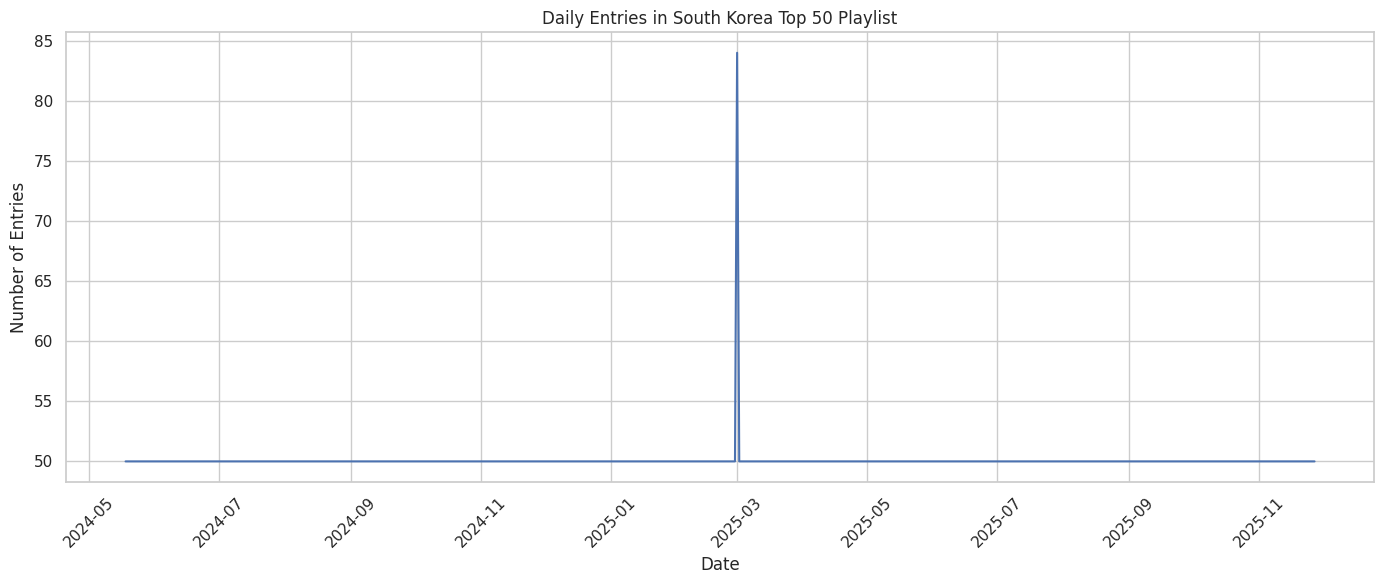

In [17]:
# ============================================================
# 6.2 DAILY CHART ENTRIES ANALYSIS
# ============================================================

if "date" in df.columns:

    daily_entries = (
        df.groupby("date")
        .size()
        .reset_index(name="total_entries")
        .sort_values("date")
    )

    print("Daily Chart Entries")
    display(daily_entries.head(10))

    plt.figure(figsize=(14, 6))

    sns.lineplot(
        data=daily_entries,
        x="date",
        y="total_entries"
    )

    plt.title("Daily Entries in South Korea Top 50 Playlist")
    plt.xlabel("Date")
    plt.ylabel("Number of Entries")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("Date column not found.")

Popularity Statistics


,Popularity
count,27784.000000
mean,76.925173
std,12.909196
min,0.000000
25%,67.000000
50%,79.000000
75%,86.000000
max,100.000000


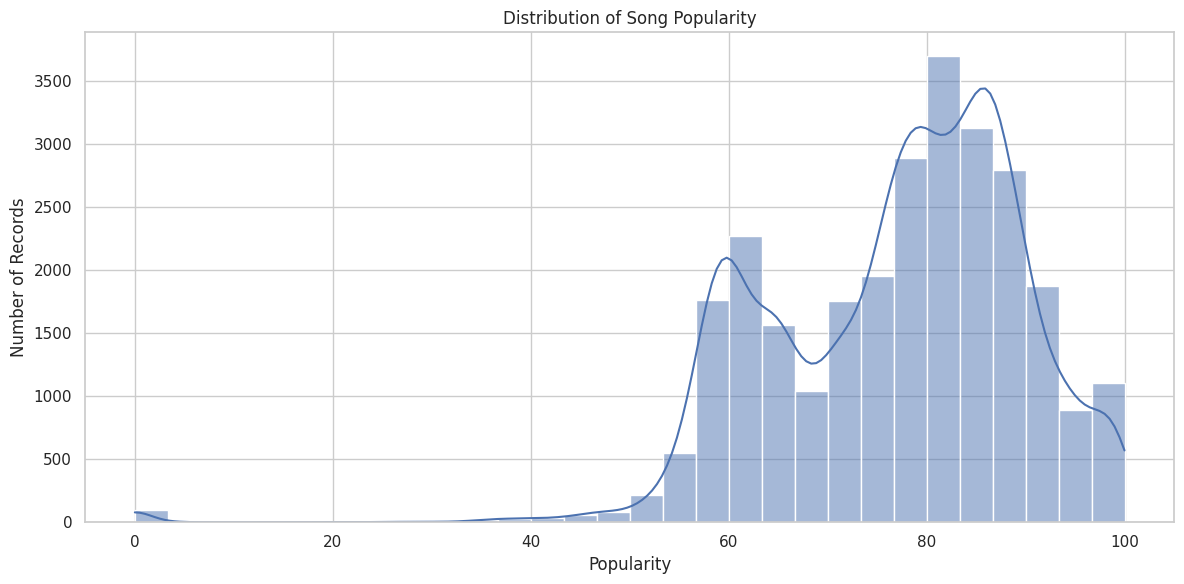

In [18]:
# ============================================================
# 6.3 SONG POPULARITY DISTRIBUTION
# ============================================================

if "popularity" in df.columns:

    popularity_data = pd.to_numeric(
        df["popularity"],
        errors="coerce"
    ).dropna()

    print("Popularity Statistics")
    display(popularity_data.describe().to_frame("Popularity"))

    plt.figure(figsize=(12, 6))

    sns.histplot(
        popularity_data,
        bins=30,
        kde=True
    )

    plt.title("Distribution of Song Popularity")
    plt.xlabel("Popularity")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

else:
    print("Popularity column not found.")

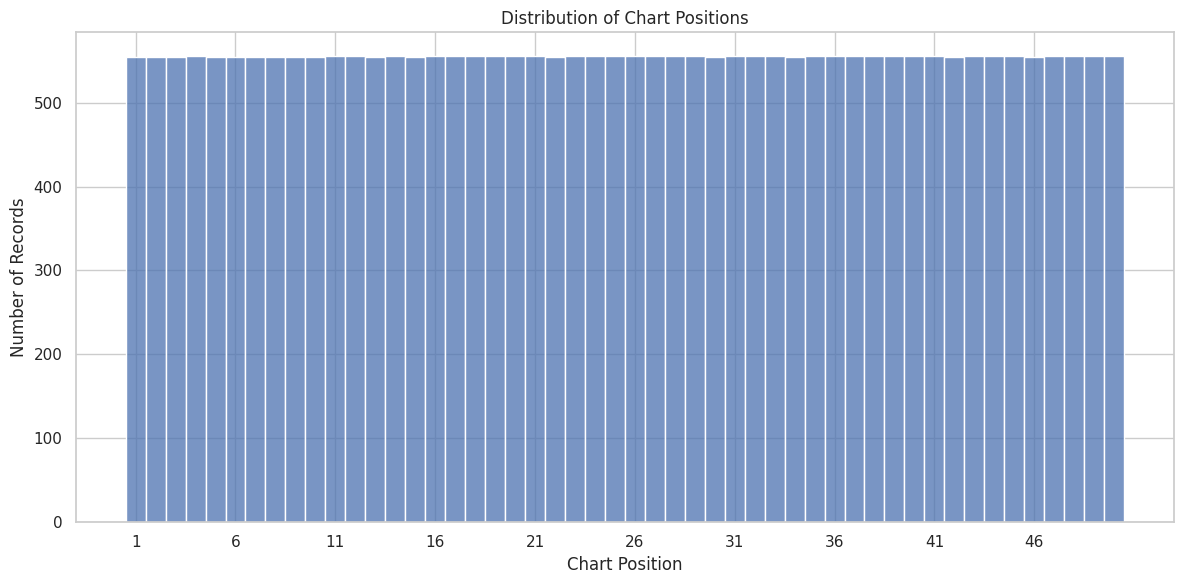

Chart Position Statistics


,Position
count,27784.000000
mean,25.505579
std,14.429442
min,1.000000
25%,13.000000
50%,26.000000
75%,38.000000
max,50.000000


In [19]:
# ============================================================
# 6.4 CHART POSITION DISTRIBUTION
# ============================================================

if "position" in df.columns:

    position_data = pd.to_numeric(
        df["position"],
        errors="coerce"
    ).dropna()

    plt.figure(figsize=(12, 6))

    sns.histplot(
        position_data,
        bins=50,
        discrete=True
    )

    plt.title("Distribution of Chart Positions")
    plt.xlabel("Chart Position")
    plt.ylabel("Number of Records")
    plt.xticks(range(1, 51, 5))
    plt.tight_layout()
    plt.show()

    print("Chart Position Statistics")
    display(position_data.describe().to_frame("Position"))

else:
    print("Position column not found.")

Top 10 Artists by Number of Chart Appearances


,Artist,Chart Appearances
0,Lim Young Woong,4801
1,Jimin,4359
2,NewJeans,2906
3,Jung Kook,1951
4,V,1385
5,LE SSERAFIM,948
6,aespa,911
7,RIIZE,533
8,IVE,496
9,DAY6,435


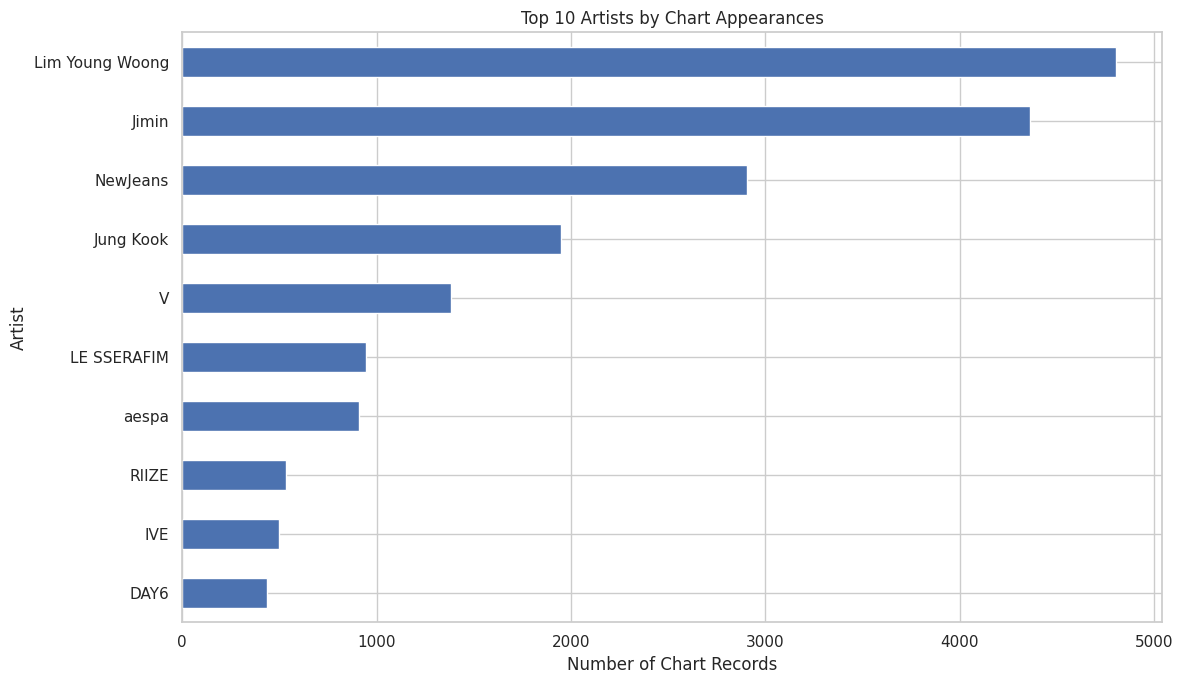

In [20]:
# ============================================================
# 6.5 TOP 10 ARTISTS BY CHART APPEARANCES
# ============================================================

if "artist" in df.columns:

    artist_counts = (
        df["artist"]
        .dropna()
        .value_counts()
        .head(10)
        .sort_values()
    )

    print("Top 10 Artists by Number of Chart Appearances")
    display(
        artist_counts.sort_values(ascending=False)
        .rename_axis("Artist")
        .reset_index(name="Chart Appearances")
    )

    plt.figure(figsize=(12, 7))

    artist_counts.plot(kind="barh")

    plt.title("Top 10 Artists by Chart Appearances")
    plt.xlabel("Number of Chart Records")
    plt.ylabel("Artist")
    plt.tight_layout()
    plt.show()

else:
    print("Artist column not found.")

In [21]:
# ============================================================
# 6.6 MOST FREQUENTLY APPEARING SONGS
# ============================================================

if "song_artist_id" in df.columns:

    song_appearances = (
        df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            chart_appearances=("date", "count")
        )
        .reset_index()
        .sort_values(
            "chart_appearances",
            ascending=False
        )
        .head(10)
    )

    print("Top 10 Songs by Recorded Chart Appearances")
    display(
        song_appearances[
            ["song", "artist", "chart_appearances"]
        ]
    )

else:
    print("Song–artist identifier not found.")
    print("Please complete Step 5 before proceeding.")

Top 10 Songs by Recorded Chart Appearances


,song,artist,chart_appearances
251,Like Crazy,Jimin,554
258,London Boy,Lim Young Woong,521
171,Grain of Sand,Lim Young Woong,516
342,Polaroid,Lim Young Woong,509
210,If We Ever Meet Again,Lim Young Woong,504
268,Love Me Again,V,469
375,Set Me Free Pt.2,Jimin,429
248,Like Crazy (English Version),Jimin,429
445,Super Shy,NewJeans,409
21,Alone,Jimin,407


Album Type Distribution


,Album Type,Number of Records
0,single,17938
1,album,9845
2,compilation,1


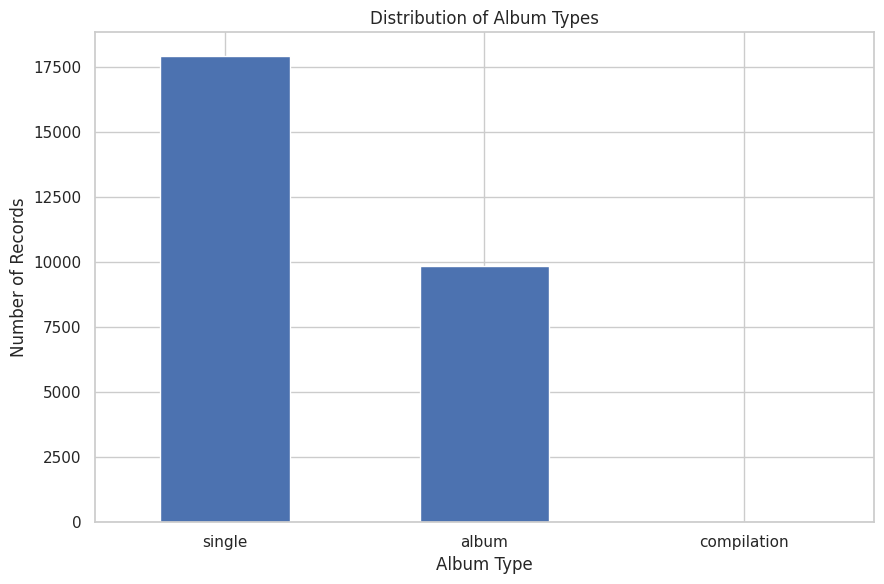

In [22]:
# ============================================================
# 6.7 ALBUM TYPE DISTRIBUTION
# ============================================================

if "album_type" in df.columns:

    album_counts = (
        df["album_type"]
        .fillna("Unknown")
        .astype(str)
        .value_counts()
    )

    print("Album Type Distribution")
    display(
        album_counts.rename_axis("Album Type")
        .reset_index(name="Number of Records")
    )

    plt.figure(figsize=(9, 6))

    album_counts.plot(
        kind="bar",
        rot=0
    )

    plt.title("Distribution of Album Types")
    plt.xlabel("Album Type")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

else:
    print("Album type column not found.")

Explicit Content Distribution


,Content Type,Number of Records
0,false,25132
1,true,2652


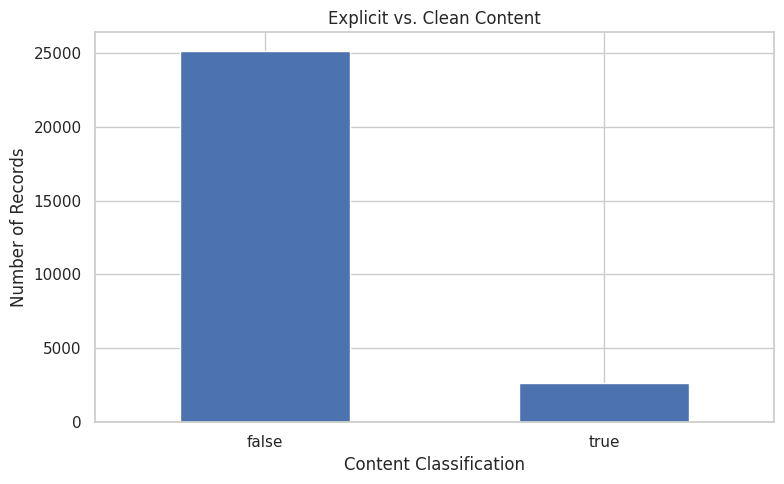

In [23]:
# ============================================================
# 6.8 EXPLICIT VS. CLEAN CONTENT ANALYSIS
# ============================================================

if "is_explicit" in df.columns:

    explicit_counts = (
        df["is_explicit"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.lower()
        .value_counts()
    )

    print("Explicit Content Distribution")
    display(
        explicit_counts.rename_axis("Content Type")
        .reset_index(name="Number of Records")
    )

    plt.figure(figsize=(8, 5))

    explicit_counts.plot(
        kind="bar",
        rot=0
    )

    plt.title("Explicit vs. Clean Content")
    plt.xlabel("Content Classification")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

else:
    print("Explicit-content column not found.")

Song Duration Statistics (Minutes)


,Duration Minutes
count,27784.000000
mean,3.196311
std,0.593580
min,0.603767
25%,2.839767
50%,3.141633
75%,3.537550
max,9.128883


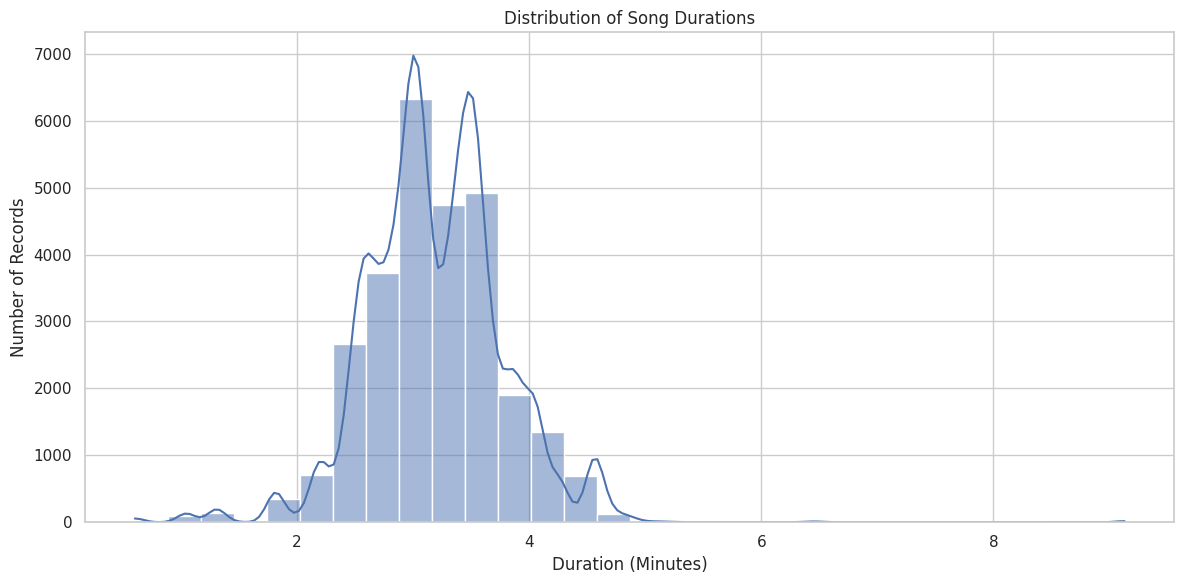

In [24]:
# ============================================================
# 6.9 SONG DURATION ANALYSIS
# ============================================================

if "duration_ms" in df.columns:

    duration_data = pd.to_numeric(
        df["duration_ms"],
        errors="coerce"
    )

    # Convert milliseconds to minutes
    duration_minutes = duration_data / 60000

    print("Song Duration Statistics (Minutes)")
    display(duration_minutes.describe().to_frame("Duration Minutes"))

    plt.figure(figsize=(12, 6))

    sns.histplot(
        duration_minutes.dropna(),
        bins=30,
        kde=True
    )

    plt.title("Distribution of Song Durations")
    plt.xlabel("Duration (Minutes)")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

else:
    print("Duration column not found.")

## **7. Chart Re-Entry Analysis**

In [25]:
# ============================================================
# 7.1 PREPARE AND VALIDATE THE CHART DATA
# ============================================================

# Preserve the original cleaned dataset
chart_source = df.copy()

# Validate required columns
required_columns = [
    "date",
    "position",
    "song",
    "artist",
    "song_artist_id"
]

missing_columns = [
    col for col in required_columns
    if col not in chart_source.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Normalize essential data types
chart_source["date"] = pd.to_datetime(
    chart_source["date"],
    errors="coerce"
)

chart_source["position"] = pd.to_numeric(
    chart_source["position"],
    errors="coerce"
)

# Remove records missing essential fields
chart_source = chart_source.dropna(
    subset=[
        "date",
        "position",
        "song_artist_id"
    ]
).copy()

# Keep valid Top 50 positions
chart_source = chart_source[
    chart_source["position"].between(1, 50)
].copy()

# Remove exact duplicate rows only
chart_source = chart_source.drop_duplicates().copy()

# Exclude the date with unresolved duplicate chart snapshots
anomalous_date = pd.Timestamp("2025-03-01")

excluded_records = chart_source[
    chart_source["date"] == anomalous_date
].copy()

chart_df = chart_source[
    chart_source["date"] != anomalous_date
].copy()

# Check for multiple records per song-date
song_date_conflicts = (
    chart_df.groupby(["song_artist_id", "date"])
    .size()
)

song_date_conflicts = song_date_conflicts[
    song_date_conflicts > 1
]

if not song_date_conflicts.empty:
    raise ValueError(
        "Other song-date conflicts remain. Investigate them "
        "before continuing."
    )

# Check each remaining chart date
daily_validation = chart_df.groupby("date").agg(
    records=("song_artist_id", "size"),
    unique_songs=("song_artist_id", "nunique"),
    unique_positions=("position", "nunique")
)

invalid_dates = daily_validation[
    (daily_validation["records"] != 50)
    | (daily_validation["unique_songs"] != 50)
    | (daily_validation["unique_positions"] != 50)
]

print("SECTION 7.1 — VALIDATION SUMMARY")
print("=" * 45)
print("Source records after exact deduplication:",
      len(chart_source))
print("Records excluded for March 1:",
      len(excluded_records))
print("Records in chart_df:", len(chart_df))
print("Observed chart dates:", chart_df["date"].nunique())
print("Unique songs:", chart_df["song_artist_id"].nunique())
print("Dates with exactly 50 entries:",
      int((daily_validation["records"] == 50).sum()))
print("Dates failing chart validation:", len(invalid_dates))

if not invalid_dates.empty:
    print("\nDates requiring further investigation:")
    display(invalid_dates.head(10))
else:
    print("\nAll remaining dates pass the Top 50 validation.")

# Chronological ordering for re-entry analysis
chart_df = chart_df.sort_values(
    ["song_artist_id", "date"]
).reset_index(drop=True)

chart_dates = pd.DatetimeIndex(
    sorted(chart_df["date"].unique())
)

print("\nFirst observed date:", chart_dates.min())
print("Last observed date:", chart_dates.max())

display(chart_df.head())

SECTION 7.1 — VALIDATION SUMMARY
Source records after exact deduplication: 27784
Records excluded for March 1: 84
Records in chart_df: 27700
Observed chart dates: 554
Unique songs: 537
Dates with exactly 50 entries: 554
Dates failing chart validation: 0

All remaining dates pass the Top 50 validation.

First observed date: 2024-05-18 00:00:00
Last observed date: 2025-11-27 00:00:00


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,song_artist_id
0,2025-09-01,26,1-800-hot-n-fun,LE SSERAFIM,64,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
1,2025-09-02,28,1-800-hot-n-fun,LE SSERAFIM,68,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
2,2025-09-03,28,1-800-hot-n-fun,LE SSERAFIM,70,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
3,2025-09-04,32,1-800-hot-n-fun,LE SSERAFIM,72,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
4,2025-09-05,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim


In [26]:
# ============================================================
# 7.2 CHART RE-ENTRY DETECTION
# ============================================================

# Use the validated chart data from Section 7.1
reentry_df = chart_df.copy()

# Ensure chronological ordering
reentry_df = reentry_df.sort_values(
    ["song_artist_id", "date"]
).reset_index(drop=True)

# All observed chart dates, in chronological order
chart_dates = pd.DatetimeIndex(
    sorted(reentry_df["date"].unique())
)

# Create a set of songs appearing on each observed date
songs_by_date = {
    date: set(
        reentry_df.loc[
            reentry_df["date"] == date,
            "song_artist_id"
        ]
    )
    for date in chart_dates
}

# Track previous appearances and detect re-entries
reentry_events = []
previously_seen = set()
previous_chart_songs = set()

for i, date in enumerate(chart_dates):
    current_songs = songs_by_date[date]

    # Songs returning after being absent from the previous
    # observed chart, but appearing on an earlier chart date
    returning_songs = (
        current_songs
        - previous_chart_songs
    ) & previously_seen

    for song_id in returning_songs:
        song_rows = reentry_df[
            (reentry_df["song_artist_id"] == song_id)
            & (reentry_df["date"] == date)
        ]

        song_row = song_rows.iloc[0]

        # Find the most recent earlier chart appearance
        earlier_dates = reentry_df.loc[
            (reentry_df["song_artist_id"] == song_id)
            & (reentry_df["date"] < date),
            "date"
        ]

        last_seen_date = earlier_dates.max()

        # Count observed chart dates absent between appearances
        gap_dates = chart_dates[
            (chart_dates > last_seen_date)
            & (chart_dates < date)
        ]

        reentry_events.append({
            "song_artist_id": song_id,
            "song": song_row["song"],
            "artist": song_row["artist"],
            "reentry_date": date,
            "last_seen_date": last_seen_date,
            "gap_observed_dates": len(gap_dates),
            "reentry_position": song_row["position"],
            "reentry_popularity": (
                song_row["popularity"]
                if "popularity" in song_row.index
                else np.nan
            )
        })

    previously_seen.update(current_songs)
    previous_chart_songs = current_songs

# Create the re-entry events table
reentry_columns = [
    "song_artist_id",
    "song",
    "artist",
    "reentry_date",
    "last_seen_date",
    "gap_observed_dates",
    "reentry_position",
    "reentry_popularity"
]

reentry_events_df = pd.DataFrame(
    reentry_events,
    columns=reentry_columns
)

print("CHART RE-ENTRY ANALYSIS")
print("=" * 45)
print("Observed chart dates:", len(chart_dates))
print("Detected re-entry events:", len(reentry_events_df))

if not reentry_events_df.empty:
    print(
        "Songs with at least one re-entry:",
        reentry_events_df["song_artist_id"].nunique()
    )

    display(
        reentry_events_df.sort_values(
            ["reentry_date", "reentry_position"]
        ).head(10)
    )
else:
    print("No re-entry events were detected.")

CHART RE-ENTRY ANALYSIS
Observed chart dates: 554
Detected re-entry events: 874
Songs with at least one re-entry: 230


,song_artist_id,song,artist,reentry_date,last_seen_date,gap_observed_dates,reentry_position,reentry_popularity
1,kill bill | sza,Kill Bill,SZA,2024-05-21,2024-05-19,1,46,94
0,teddy bear | stayc,Teddy Bear,STAYC,2024-05-21,2024-05-18,2,47,74
2,love dive | ive,LOVE DIVE,IVE,2024-05-21,2024-05-19,1,49,83
3,love always run away | lim young woong,Love Always Run Away,Lim Young Woong,2024-05-23,2024-05-18,4,47,58
4,vibe (feat. jimin of bts) | taeyang,VIBE (feat. Jimin of BTS),TAEYANG,2024-05-24,2024-05-22,1,43,68
5,interlude : dive | jimin,Interlude : Dive,Jimin,2024-05-24,2024-05-20,3,48,77
6,love always run away | lim young woong,Love Always Run Away,Lim Young Woong,2024-05-25,2024-05-23,1,50,58
7,like crazy (deep house remix) | jimin,Like Crazy (Deep House Remix),Jimin,2024-05-28,2024-05-20,7,43,73
8,like crazy (uk garage remix) | jimin,Like Crazy (UK Garage Remix),Jimin,2024-05-28,2024-05-20,7,44,72
9,promise | jimin,Promise,Jimin,2024-05-28,2024-05-20,7,45,77


In [27]:
# ============================================================
# 7.2.1 VALIDATE RE-ENTRY EVENTS
# ============================================================

# Check whether events have valid dates and gaps
print("RE-ENTRY VALIDATION")
print("=" * 40)

print(
    "Missing re-entry dates:",
    int(reentry_events_df["reentry_date"].isna().sum())
)

print(
    "Missing previous appearance dates:",
    int(reentry_events_df["last_seen_date"].isna().sum())
)

print(
    "Events with invalid or zero gaps:",
    int(
        (
            reentry_events_df["gap_observed_dates"] <= 0
        ).sum()
    )
)

print(
    "Duplicate song-date events:",
    int(
        reentry_events_df.duplicated(
            ["song_artist_id", "reentry_date"]
        ).sum()
    )
)

# Check events immediately after the excluded date
anomalous_date = pd.Timestamp("2025-03-01")

near_anomaly = reentry_events_df[
    (
        reentry_events_df["last_seen_date"] < anomalous_date
    )
    &
    (
        reentry_events_df["reentry_date"] > anomalous_date
    )
].copy()

print(
    "\nEvents spanning the excluded date:",
    len(near_anomaly)
)

display(
    near_anomaly[
        [
            "song",
            "artist",
            "last_seen_date",
            "reentry_date",
            "gap_observed_dates"
        ]
    ].head(10)
)

RE-ENTRY VALIDATION
Missing re-entry dates: 0
Missing previous appearance dates: 0
Events with invalid or zero gaps: 0
Duplicate song-date events: 0

Events spanning the excluded date: 16


,song,artist,last_seen_date,reentry_date,gap_observed_dates
450,My Love Mine All Mine,Mitski,2025-02-25,2025-03-02,3
451,Rainy Days,V,2025-02-20,2025-03-02,8
452,Standing Next to You,Jung Kook,2025-02-28,2025-03-03,1
453,I Love You,Lim Young Woong,2025-02-28,2025-03-04,2
454,CARNIVAL,¥$ & Kanye West & Ty Dolla $ign,2025-02-21,2025-03-06,11
455,STUPID IN LOVE (feat. HUH YUNJIN of LE SSERAFIM),MAX,2025-02-18,2025-03-06,14
463,"yes, and?",Ariana Grande,2025-02-18,2025-03-10,18
465,Ditto,NewJeans,2025-02-17,2025-03-11,20
468,Bling-Bang-Bang-Born,Creepy Nuts,2025-02-20,2025-03-13,19
474,Too Sad to Dance,Jung Kook,2024-12-23,2025-03-17,81


In [28]:
# ============================================================
# 7.2.2 FLAG RE-ENTRIES AFFECTED BY THE EXCLUDED DATE
# ============================================================

anomalous_date = pd.Timestamp("2025-03-01")

reentry_events_df["requires_gap_review"] = (
    (reentry_events_df["last_seen_date"] < anomalous_date)
    &
    (reentry_events_df["reentry_date"] > anomalous_date)
)

print("RE-ENTRY REVIEW SUMMARY")
print("=" * 40)

print(
    "Total re-entry events:",
    len(reentry_events_df)
)

print(
    "Events requiring gap review:",
    int(reentry_events_df["requires_gap_review"].sum())
)

print(
    "Events not spanning the excluded date:",
    int((~reentry_events_df["requires_gap_review"]).sum())
)

print("\nEvents requiring review:")
display(
    reentry_events_df.loc[
        reentry_events_df["requires_gap_review"],
        [
            "song",
            "artist",
            "last_seen_date",
            "reentry_date",
            "gap_observed_dates"
        ]
    ].head(10)
)

RE-ENTRY REVIEW SUMMARY
Total re-entry events: 874
Events requiring gap review: 16
Events not spanning the excluded date: 858

Events requiring review:


,song,artist,last_seen_date,reentry_date,gap_observed_dates
450,My Love Mine All Mine,Mitski,2025-02-25,2025-03-02,3
451,Rainy Days,V,2025-02-20,2025-03-02,8
452,Standing Next to You,Jung Kook,2025-02-28,2025-03-03,1
453,I Love You,Lim Young Woong,2025-02-28,2025-03-04,2
454,CARNIVAL,¥$ & Kanye West & Ty Dolla $ign,2025-02-21,2025-03-06,11
455,STUPID IN LOVE (feat. HUH YUNJIN of LE SSERAFIM),MAX,2025-02-18,2025-03-06,14
463,"yes, and?",Ariana Grande,2025-02-18,2025-03-10,18
465,Ditto,NewJeans,2025-02-17,2025-03-11,20
468,Bling-Bang-Bang-Born,Creepy Nuts,2025-02-20,2025-03-13,19
474,Too Sad to Dance,Jung Kook,2024-12-23,2025-03-17,81


In [29]:
# ============================================================
# 7.3 IDENTIFY CHART EXIT AND RE-ENTRY DATES
# ============================================================

# Build a set of songs present on each observed chart date
songs_by_date = {
    date: set(
        chart_df.loc[
            chart_df["date"] == date,
            "song_artist_id"
        ]
    )
    for date in chart_dates
}

# Store the first available metadata for each song
song_metadata = (
    chart_df.sort_values("date")
    .drop_duplicates("song_artist_id")
    .set_index("song_artist_id")[["song", "artist"]]
    .to_dict("index")
)

# Track songs present on the previous observed chart date
previously_present = set()

# Store detected events
exit_events = []
reentry_events = []

for i, current_date in enumerate(chart_dates):

    current_songs = songs_by_date[current_date]

    # Identify songs that exited the chart
    exited_songs = previously_present - current_songs

    for song_id in exited_songs:
        metadata = song_metadata.get(song_id, {})

        exit_events.append({
            "song_artist_id": song_id,
            "song": metadata.get("song"),
            "artist": metadata.get("artist"),
            "exit_date": current_date
        })

    # Identify songs returning after an observed absence
    returned_songs = current_songs - previously_present

    for song_id in returned_songs:

        # A re-entry requires an earlier chart appearance
        earlier_dates = chart_df.loc[
            (chart_df["song_artist_id"] == song_id)
            & (chart_df["date"] < current_date),
            "date"
        ]

        if not earlier_dates.empty:
            previous_chart_date = earlier_dates.max()
            metadata = song_metadata.get(song_id, {})

            reentry_events.append({
                "song_artist_id": song_id,
                "song": metadata.get("song"),
                "artist": metadata.get("artist"),
                "previous_chart_date": previous_chart_date,
                "reentry_date": current_date,
                "days_between_appearances": (
                    current_date - previous_chart_date
                ).days
            })

    # Update the previous chart for the next iteration
    previously_present = current_songs

# Convert results to DataFrames
exit_df = pd.DataFrame(exit_events)
reentry_df = pd.DataFrame(reentry_events)

print("Chart Exit and Re-Entry Detection Completed")
print("=" * 60)
print("Detected exit events:", len(exit_df))
print("Detected re-entry events:", len(reentry_df))

print("\nUnique songs with re-entry events:",
      reentry_df["song_artist_id"].nunique()
      if not reentry_df.empty else 0)

print("\nSample Exit Events:")
display(exit_df.head(10))

print("\nSample Re-Entry Events:")
display(reentry_df.head(10))

Chart Exit and Re-Entry Detection Completed
Detected exit events: 1361
Detected re-entry events: 874

Unique songs with re-entry events: 230

Sample Exit Events:


,song_artist_id,song,artist,exit_date
0,love always run away | lim young woong,Love Always Run Away,Lim Young Woong,2024-05-19
1,salty & sweet | aespa,Salty & Sweet,aespa,2024-05-19
2,teddy bear | stayc,Teddy Bear,STAYC,2024-05-19
3,kill bill | sza,Kill Bill,SZA,2024-05-20
4,love dive | ive,LOVE DIVE,IVE,2024-05-20
5,like crazy (uk garage remix) | jimin,Like Crazy (UK Garage Remix),Jimin,2024-05-21
6,like crazy (deep house remix) | jimin,Like Crazy (Deep House Remix),Jimin,2024-05-21
7,"angel pt. 1 (feat. jimin of bts, jvke & muni l...","Angel Pt. 1 (feat. Jimin of BTS, JVKE & Muni L...",Fast & Furious: The Fast Saga,2024-05-21
8,interlude : dive | jimin,Interlude : Dive,Jimin,2024-05-21
9,with you | jimin & ha sung woon,With you,Jimin & HA SUNG WOON,2024-05-21



Sample Re-Entry Events:


,song_artist_id,song,artist,previous_chart_date,reentry_date,days_between_appearances
0,teddy bear | stayc,Teddy Bear,STAYC,2024-05-18,2024-05-21,3
1,love dive | ive,LOVE DIVE,IVE,2024-05-19,2024-05-21,2
2,kill bill | sza,Kill Bill,SZA,2024-05-19,2024-05-21,2
3,love always run away | lim young woong,Love Always Run Away,Lim Young Woong,2024-05-18,2024-05-23,5
4,vibe (feat. jimin of bts) | taeyang,VIBE (feat. Jimin of BTS),TAEYANG,2024-05-22,2024-05-24,2
5,interlude : dive | jimin,Interlude : Dive,Jimin,2024-05-20,2024-05-24,4
6,love always run away | lim young woong,Love Always Run Away,Lim Young Woong,2024-05-23,2024-05-25,2
7,like crazy (deep house remix) | jimin,Like Crazy (Deep House Remix),Jimin,2024-05-20,2024-05-28,8
8,like crazy (uk garage remix) | jimin,Like Crazy (UK Garage Remix),Jimin,2024-05-20,2024-05-28,8
9,promise | jimin,Promise,Jimin,2024-05-20,2024-05-28,8


In [30]:
# ============================================================
# 7.4 CALCULATE RE-ENTRY FREQUENCY
# ============================================================

if not reentry_df.empty:

    reentry_frequency = (
        reentry_df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            reentry_count=("reentry_date", "count"),
            first_reentry_date=("reentry_date", "min"),
            latest_reentry_date=("reentry_date", "max"),
            average_gap_days=(
                "days_between_appearances",
                "mean"
            )
        )
        .reset_index()
        .sort_values(
            "reentry_count",
            ascending=False
        )
    )

    reentry_frequency["average_gap_days"] = (
        reentry_frequency["average_gap_days"].round(2)
    )

    print("Songs Ranked by Re-Entry Frequency")

    display(reentry_frequency.head(20))

else:

    reentry_frequency = pd.DataFrame(
        columns=[
            "song_artist_id",
            "song",
            "artist",
            "reentry_count",
            "first_reentry_date",
            "latest_reentry_date",
            "average_gap_days"
        ]
    )

    print("No confirmed re-entry events were detected.")

Songs Ranked by Re-Entry Frequency


,song_artist_id,song,artist,reentry_count,first_reentry_date,latest_reentry_date,average_gap_days
143,"our blues, our life | lim young woong","Our Blues, Our Life",Lim Young Woong,28,2024-07-10,2025-08-12,4.18
47,ditto | newjeans,Ditto,NewJeans,26,2024-11-08,2025-11-05,7.23
2,a bientot | lim young woong,A bientot,Lim Young Woong,22,2024-06-09,2025-07-18,7.64
137,new jeans | newjeans,New Jeans,NewJeans,20,2024-11-03,2025-10-21,10.35
82,hype boy | newjeans,Hype Boy,NewJeans,19,2024-10-22,2025-10-13,11.05
91,interlude : dive | jimin,Interlude : Dive,Jimin,19,2024-05-24,2025-06-28,3.21
55,eta | newjeans,ETA,NewJeans,16,2024-11-23,2025-11-05,9.06
153,rainbow | lim young woong,Rainbow,Lim Young Woong,16,2024-07-08,2025-08-12,3.81
167,somebody | jung kook,Somebody,Jung Kook,15,2024-12-06,2025-03-10,5.33
142,omg | newjeans,OMG,NewJeans,14,2024-12-02,2025-10-13,15.07


In [31]:
# ============================================================
# 7.5 MEASURE TIME GAPS BETWEEN RE-ENTRIES
# ============================================================

if not reentry_df.empty:

    reentry_df = reentry_df.sort_values(
        ["song_artist_id", "reentry_date"]
    ).copy()

    # Calculate the interval between successive re-entry dates
    reentry_df["days_since_previous_reentry"] = (
        reentry_df.groupby("song_artist_id")["reentry_date"]
        .diff()
        .dt.days
    )

    print("Re-Entry Timing Analysis")

    display(
        reentry_df[
            [
                "song",
                "artist",
                "previous_chart_date",
                "reentry_date",
                "days_between_appearances",
                "days_since_previous_reentry"
            ]
        ].head(20)
    )

    print("\nSummary of Days Between Previous Appearance and Re-Entry:")

    display(
        reentry_df["days_between_appearances"]
        .describe()
        .to_frame("Days Between Appearances")
    )

else:
    print("No re-entry timing data is available.")

Re-Entry Timing Analysis


,song,artist,previous_chart_date,reentry_date,days_between_appearances,days_since_previous_reentry
212,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-05,2024-10-09,4,NaN
282,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-11-27,2024-12-03,6,NaN
42,A bientot,Lim Young Woong,2024-06-07,2024-06-09,2,NaN
68,A bientot,Lim Young Woong,2024-06-20,2024-06-22,2,13.0
99,A bientot,Lim Young Woong,2024-07-04,2024-07-11,7,19.0
101,A bientot,Lim Young Woong,2024-07-11,2024-07-13,2,2.0
104,A bientot,Lim Young Woong,2024-07-13,2024-07-17,4,4.0
114,A bientot,Lim Young Woong,2024-07-18,2024-07-23,5,6.0
136,A bientot,Lim Young Woong,2024-07-25,2024-08-04,10,12.0
139,A bientot,Lim Young Woong,2024-08-04,2024-08-06,2,2.0



Summary of Days Between Previous Appearance and Re-Entry:


,Days Between Appearances
count,874.000000
mean,10.262014
std,28.806082
min,2.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,508.000000


In [32]:
# ============================================================
# 7.6 EXPORT CHART RE-ENTRY RESULTS
# ============================================================

exit_df.to_csv(
    "South_Korea_Chart_Exit_Events.csv",
    index=False
)

reentry_df.to_csv(
    "South_Korea_Chart_Reentry_Events.csv",
    index=False
)

reentry_frequency.to_csv(
    "South_Korea_Reentry_Frequency.csv",
    index=False
)

print("Chart re-entry analysis exported successfully!")
print("1. South_Korea_Chart_Exit_Events.csv")
print("2. South_Korea_Chart_Reentry_Events.csv")
print("3. South_Korea_Reentry_Frequency.csv")

Chart re-entry analysis exported successfully!
1. South_Korea_Chart_Exit_Events.csv
2. South_Korea_Chart_Reentry_Events.csv
3. South_Korea_Reentry_Frequency.csv


## **8. Momentum Spike Measurement**

In [33]:
# ============================================================
# 8.1 PREPARE SONG-LEVEL MOMENTUM DATA
# ============================================================

momentum_df = chart_df.copy()

momentum_df["date"] = pd.to_datetime(
    momentum_df["date"],
    errors="coerce"
)

momentum_df["position"] = pd.to_numeric(
    momentum_df["position"],
    errors="coerce"
)

momentum_df["popularity"] = pd.to_numeric(
    momentum_df["popularity"],
    errors="coerce"
)

momentum_df = momentum_df.dropna(
    subset=[
        "date",
        "position",
        "popularity",
        "song_artist_id"
    ]
)

momentum_df = momentum_df.sort_values(
    ["song_artist_id", "date"]
).reset_index(drop=True)

# Add previous observed values for each song
momentum_df["previous_position"] = (
    momentum_df.groupby("song_artist_id")["position"].shift(1)
)

momentum_df["previous_popularity"] = (
    momentum_df.groupby("song_artist_id")["popularity"].shift(1)
)

# Rank improvement is positive when the position number decreases
momentum_df["rank_improvement"] = (
    momentum_df["previous_position"]
    - momentum_df["position"]
)

momentum_df["popularity_change"] = (
    momentum_df["popularity"]
    - momentum_df["previous_popularity"]
)

print("MOMENTUM DATA PREPARATION")
print("=" * 40)
print("Chart records:", len(momentum_df))
print("Unique songs:", momentum_df["song_artist_id"].nunique())
print("Missing previous positions:",
      int(momentum_df["previous_position"].isna().sum()))
print("Missing previous popularity values:",
      int(momentum_df["previous_popularity"].isna().sum()))

print("\nPrepared records:")
display(momentum_df.head(10))

MOMENTUM DATA PREPARATION
Chart records: 27700
Unique songs: 537
Missing previous positions: 537
Missing previous popularity values: 537

Prepared records:


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,song_artist_id,previous_position,previous_popularity,rank_improvement,popularity_change
0,2025-09-01,26,1-800-hot-n-fun,LE SSERAFIM,64,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,NaN,NaN,NaN,NaN
1,2025-09-02,28,1-800-hot-n-fun,LE SSERAFIM,68,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,26.0,64.0,-2.0,4.0
2,2025-09-03,28,1-800-hot-n-fun,LE SSERAFIM,70,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,28.0,68.0,0.0,2.0
3,2025-09-04,32,1-800-hot-n-fun,LE SSERAFIM,72,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,28.0,70.0,-4.0,2.0
4,2025-09-05,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,32.0,72.0,-13.0,1.0
5,2025-09-06,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,45.0,73.0,0.0,0.0
6,2025-09-07,49,1-800-hot-n-fun,LE SSERAFIM,74,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,45.0,73.0,-4.0,1.0
7,2025-09-08,49,1-800-hot-n-fun,LE SSERAFIM,75,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,49.0,74.0,0.0,1.0
8,2025-05-26,26,24YB (Intro),YANGHONGWON,38,83240,album,8,false,https://i.scdn.co/image/ab67616d0000b273e6afca...,24yb (intro) | yanghongwon,NaN,NaN,NaN,NaN
9,2025-05-27,28,24YB (Intro),YANGHONGWON,42,83240,album,8,false,https://i.scdn.co/image/ab67616d0000b273e6afca...,24yb (intro) | yanghongwon,26.0,38.0,-2.0,4.0


In [34]:
# ============================================================
# 8.1.1 VALIDATE MOMENTUM DATA
# ============================================================

print("MOMENTUM DATA VALIDATION")
print("=" * 40)

print("Total records:", len(momentum_df))

print(
    "Duplicate song-date combinations:",
    int(
        momentum_df.duplicated(
            ["song_artist_id", "date"]
        ).sum()
    )
)

print(
    "Invalid chart positions:",
    int(
        (
            ~momentum_df["position"].between(1, 50)
        ).sum()
    )
)

print(
    "Popularity outside 0–100:",
    int(
        (
            ~momentum_df["popularity"].between(0, 100)
        ).sum()
    )
)

print(
    "First appearances without previous position:",
    int(momentum_df["previous_position"].isna().sum())
)

print("\nDaily chart record counts:")
display(
    momentum_df.groupby("date").size()
    .value_counts()
    .sort_index()
    .rename_axis("Records per date")
    .reset_index(name="Number of dates")
)

MOMENTUM DATA VALIDATION
Total records: 27700
Duplicate song-date combinations: 0
Invalid chart positions: 0
Popularity outside 0–100: 0
First appearances without previous position: 537

Daily chart record counts:


,Records per date,Number of dates
0,50,554


In [35]:
# ============================================================
# 8.2 CORRECT MOMENTUM METRICS FOR EACH RE-ENTRY
# ============================================================

# Look up the previous chart position and popularity
previous_records = chart_df[
    ["song_artist_id", "date", "position", "popularity"]
].copy()

previous_records = previous_records.rename(
    columns={
        "date": "last_seen_date",
        "position": "previous_reentry_position",
        "popularity": "previous_reentry_popularity"
    }
)

# Match each event to its actual previous appearance
event_momentum = reentry_events_df.merge(
    previous_records,
    on=["song_artist_id", "last_seen_date"],
    how="left",
    validate="many_to_one"
)

# Re-entry rank and popularity come from the re-entry date
reentry_records = chart_df[
    ["song_artist_id", "date", "position", "popularity"]
].rename(
    columns={
        "date": "reentry_date",
        "position": "reentry_position_check",
        "popularity": "reentry_popularity_check"
    }
)

event_momentum = event_momentum.merge(
    reentry_records,
    on=["song_artist_id", "reentry_date"],
    how="left",
    validate="one_to_one"
)

# Calculate event-specific momentum metrics
event_momentum["rank_improvement"] = (
    event_momentum["previous_reentry_position"]
    - event_momentum["reentry_position_check"]
)

event_momentum["popularity_change"] = (
    event_momentum["reentry_popularity_check"]
    - event_momentum["previous_reentry_popularity"]
)

event_momentum["gap_calendar_days"] = (
    event_momentum["reentry_date"]
    - event_momentum["last_seen_date"]
).dt.days

# Positive rank improvement means the song returned at a better rank
event_momentum["rank_jump_magnitude"] = (
    event_momentum["rank_improvement"].abs()
)

print("EVENT MOMENTUM SUMMARY")
print("=" * 45)
print("Total re-entry events:", len(event_momentum))
print(
    "Events with previous-position matches:",
    int(event_momentum["previous_reentry_position"].notna().sum())
)
print(
    "Events with re-entry matches:",
    int(event_momentum["reentry_position_check"].notna().sum())
)
print(
    "Missing popularity changes:",
    int(event_momentum["popularity_change"].isna().sum())
)

display(
    event_momentum[
        [
            "song",
            "artist",
            "last_seen_date",
            "reentry_date",
            "previous_reentry_position",
            "reentry_position_check",
            "rank_improvement",
            "previous_reentry_popularity",
            "reentry_popularity_check",
            "popularity_change",
            "requires_gap_review"
        ]
    ].head(10)
)

EVENT MOMENTUM SUMMARY
Total re-entry events: 874
Events with previous-position matches: 874
Events with re-entry matches: 874
Missing popularity changes: 0


,song,artist,last_seen_date,reentry_date,previous_reentry_position,reentry_position_check,rank_improvement,previous_reentry_popularity,reentry_popularity_check,popularity_change,requires_gap_review
0,Teddy Bear,STAYC,2024-05-18,2024-05-21,47,47,0,74,74,0,False
1,Kill Bill,SZA,2024-05-19,2024-05-21,46,46,0,94,94,0,False
2,LOVE DIVE,IVE,2024-05-19,2024-05-21,48,49,-1,83,83,0,False
3,Love Always Run Away,Lim Young Woong,2024-05-18,2024-05-23,50,47,3,58,58,0,False
4,VIBE (feat. Jimin of BTS),TAEYANG,2024-05-22,2024-05-24,49,43,6,68,68,0,False
5,Interlude : Dive,Jimin,2024-05-20,2024-05-24,38,48,-10,78,77,-1,False
6,Love Always Run Away,Lim Young Woong,2024-05-23,2024-05-25,47,50,-3,58,58,0,False
7,Like Crazy (Deep House Remix),Jimin,2024-05-20,2024-05-28,46,43,3,74,73,-1,False
8,Like Crazy (UK Garage Remix),Jimin,2024-05-20,2024-05-28,47,44,3,73,72,-1,False
9,Promise,Jimin,2024-05-20,2024-05-28,43,45,-2,78,77,-1,False


In [36]:
# ============================================================
# 8.2.1 VALIDATE CORRECTED MOMENTUM CALCULATIONS
# ============================================================

print("MOMENTUM CALCULATION VALIDATION")
print("=" * 45)

# Check that rank improvement matches the formula
expected_rank_improvement = (
    event_momentum["previous_reentry_position"]
    - event_momentum["reentry_position_check"]
)

rank_mismatches = (
    event_momentum["rank_improvement"]
    != expected_rank_improvement
)

print(
    "Rank improvement mismatches:",
    int(rank_mismatches.sum())
)

# Check that popularity change matches the formula
expected_popularity_change = (
    event_momentum["reentry_popularity_check"]
    - event_momentum["previous_reentry_popularity"]
)

popularity_mismatches = (
    event_momentum["popularity_change"]
    != expected_popularity_change
)

print(
    "Popularity change mismatches:",
    int(popularity_mismatches.sum())
)

# Check for missing required values
required_metrics = [
    "previous_reentry_position",
    "reentry_position_check",
    "previous_reentry_popularity",
    "reentry_popularity_check",
    "rank_improvement",
    "popularity_change"
]

print(
    "Missing required metric values:",
    int(event_momentum[required_metrics].isna().sum().sum())
)

print("\nSample event calculations:")
display(
    event_momentum[
        [
            "song",
            "artist",
            "previous_reentry_position",
            "reentry_position_check",
            "rank_improvement",
            "previous_reentry_popularity",
            "reentry_popularity_check",
            "popularity_change"
        ]
    ].head(10)
)

MOMENTUM CALCULATION VALIDATION
Rank improvement mismatches: 0
Popularity change mismatches: 0
Missing required metric values: 0

Sample event calculations:


,song,artist,previous_reentry_position,reentry_position_check,rank_improvement,previous_reentry_popularity,reentry_popularity_check,popularity_change
0,Teddy Bear,STAYC,47,47,0,74,74,0
1,Kill Bill,SZA,46,46,0,94,94,0
2,LOVE DIVE,IVE,48,49,-1,83,83,0
3,Love Always Run Away,Lim Young Woong,50,47,3,58,58,0
4,VIBE (feat. Jimin of BTS),TAEYANG,49,43,6,68,68,0
5,Interlude : Dive,Jimin,38,48,-10,78,77,-1
6,Love Always Run Away,Lim Young Woong,47,50,-3,58,58,0
7,Like Crazy (Deep House Remix),Jimin,46,43,3,74,73,-1
8,Like Crazy (UK Garage Remix),Jimin,47,44,3,73,72,-1
9,Promise,Jimin,43,45,-2,78,77,-1


In [37]:
# ============================================================
# 8.3 RANK-JUMP MAGNITUDE
# ============================================================

# Previous observed chart position for each song
momentum_df["previous_position"] = (
    momentum_df.groupby("song_artist_id")["position"]
    .shift(1)
)

# Positive values represent rank improvements
momentum_df["rank_jump_magnitude"] = (
    momentum_df["previous_position"]
    - momentum_df["position"]
)

print("Rank-Jump Analysis")

display(
    momentum_df[
        [
            "song",
            "artist",
            "date",
            "previous_position",
            "position",
            "rank_jump_magnitude"
        ]
    ].head(15)
)

Rank-Jump Analysis


,song,artist,date,previous_position,position,rank_jump_magnitude
0,1-800-hot-n-fun,LE SSERAFIM,2025-09-01,NaN,26,NaN
1,1-800-hot-n-fun,LE SSERAFIM,2025-09-02,26.0,28,-2.0
2,1-800-hot-n-fun,LE SSERAFIM,2025-09-03,28.0,28,0.0
3,1-800-hot-n-fun,LE SSERAFIM,2025-09-04,28.0,32,-4.0
4,1-800-hot-n-fun,LE SSERAFIM,2025-09-05,32.0,45,-13.0
5,1-800-hot-n-fun,LE SSERAFIM,2025-09-06,45.0,45,0.0
6,1-800-hot-n-fun,LE SSERAFIM,2025-09-07,45.0,49,-4.0
7,1-800-hot-n-fun,LE SSERAFIM,2025-09-08,49.0,49,0.0
8,24YB (Intro),YANGHONGWON,2025-05-26,NaN,26,NaN
9,24YB (Intro),YANGHONGWON,2025-05-27,26.0,28,-2.0


In [38]:
# ============================================================
# 8.4 PEAK RANK AFTER RE-ENTRY
# ============================================================

if not reentry_df.empty:

    peak_rank_records = []

    for _, event in reentry_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = event["reentry_date"]

        # Select observations from the re-entry date onward
        song_after_reentry = momentum_df[
            (momentum_df["song_artist_id"] == song_id)
            & (momentum_df["date"] >= reentry_date)
        ].copy()

        if not song_after_reentry.empty:

            peak_index = song_after_reentry["position"].idxmin()
            peak_record = song_after_reentry.loc[peak_index]

            peak_rank_records.append({
                "song_artist_id": song_id,
                "song": event["song"],
                "artist": event["artist"],
                "reentry_date": reentry_date,
                "peak_rank_after_reentry": peak_record["position"],
                "peak_rank_date": peak_record["date"]
            })

    peak_rank_df = pd.DataFrame(peak_rank_records)

    print("Peak Rank After Re-Entry")

    display(peak_rank_df.head(20))

else:

    peak_rank_df = pd.DataFrame()

    print("No re-entry events are available.")

Peak Rank After Re-Entry


,song_artist_id,song,artist,reentry_date,peak_rank_after_reentry,peak_rank_date
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-09,38,2024-10-10
1,3d (justin timberlake remix) | jung kook & jus...,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-12-03,36,2024-12-04
2,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-09,18,2024-11-30
3,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-22,18,2024-11-30
4,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-11,18,2024-11-30
5,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-13,18,2024-11-30
6,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-17,18,2024-11-30
7,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-23,18,2024-11-30
8,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-04,18,2024-11-30
9,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-06,18,2024-11-30


In [39]:
# ============================================================
# SECTION 8.5 — MOMENTUM INTENSITY SCORE
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("SECTION 8.5 — MOMENTUM INTENSITY SCORE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare chart observations
# ------------------------------------------------------------

chart = chart_df.copy()

chart["date"] = pd.to_datetime(chart["date"], errors="coerce")
chart["position"] = pd.to_numeric(chart["position"], errors="coerce")
chart["popularity"] = pd.to_numeric(chart["popularity"], errors="coerce")

chart = chart.dropna(
    subset=["date", "song_artist_id", "position"]
).copy()

chart = (
    chart.sort_values(["date", "position"])
    .drop_duplicates(["song_artist_id", "date"], keep="first")
    .sort_values(["song_artist_id", "date"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Prepare re-entry events
# ------------------------------------------------------------

events = reentry_events_df.copy()

events["reentry_date"] = pd.to_datetime(
    events["reentry_date"], errors="coerce"
)

events = events.dropna(
    subset=["song_artist_id", "reentry_date"]
).drop_duplicates(
    ["song_artist_id", "reentry_date"]
).copy()

events["reentry_position"] = pd.to_numeric(
    events["reentry_position"], errors="coerce"
)

events["reentry_popularity"] = pd.to_numeric(
    events["reentry_popularity"], errors="coerce"
)

# ------------------------------------------------------------
# 3. Find the immediately preceding chart appearance
# ------------------------------------------------------------

previous_chart = chart[
    ["song_artist_id", "date", "position", "popularity"]
].rename(
    columns={
        "date": "previous_chart_date",
        "position": "previous_position",
        "popularity": "previous_popularity"
    }
)

previous_candidates = events[
    ["song_artist_id", "reentry_date"]
].merge(
    previous_chart,
    on="song_artist_id",
    how="left"
)

previous_candidates = previous_candidates[
    previous_candidates["previous_chart_date"]
    < previous_candidates["reentry_date"]
].copy()

previous_candidates = (
    previous_candidates
    .sort_values("previous_chart_date")
    .drop_duplicates(
        ["song_artist_id", "reentry_date"],
        keep="last"
    )
)

event_momentum = events.merge(
    previous_candidates,
    on=["song_artist_id", "reentry_date"],
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. Calculate event-level momentum metrics
# ------------------------------------------------------------

event_momentum["gap_days"] = (
    event_momentum["reentry_date"]
    - event_momentum["previous_chart_date"]
).dt.days

event_momentum["rank_improvement"] = (
    event_momentum["previous_position"]
    - event_momentum["reentry_position"]
)

event_momentum["popularity_change"] = (
    event_momentum["reentry_popularity"]
    - event_momentum["previous_popularity"]
)

event_momentum["positive_rank_improvement"] = (
    event_momentum["rank_improvement"].clip(lower=0)
)

event_momentum["positive_popularity_change"] = (
    event_momentum["popularity_change"].clip(lower=0)
)

# ------------------------------------------------------------
# 5. Normalize both momentum components to 0–100
# ------------------------------------------------------------

def minmax_score(series):

    values = pd.to_numeric(series, errors="coerce")

    minimum = values.min()
    maximum = values.max()

    if pd.isna(minimum) or pd.isna(maximum):
        return pd.Series(
            np.nan,
            index=values.index,
            dtype=float
        )

    if maximum == minimum:
        return pd.Series(
            np.where(values.notna(), 0.0, np.nan),
            index=values.index,
            dtype=float
        )

    return (
        (values - minimum)
        / (maximum - minimum)
        * 100
    )


event_momentum["rank_momentum_score"] = minmax_score(
    event_momentum["positive_rank_improvement"]
)

event_momentum["popularity_momentum_score"] = minmax_score(
    event_momentum["positive_popularity_change"]
)

# ------------------------------------------------------------
# 6. Calculate improved composite momentum score
# ------------------------------------------------------------

momentum_components = [
    "rank_momentum_score",
    "popularity_momentum_score"
]

event_momentum["momentum_intensity_score"] = (
    event_momentum[momentum_components]
    .mean(axis=1, skipna=False)
)

# ------------------------------------------------------------
# 7. Preserve excluded-date gap-review flags
# ------------------------------------------------------------

excluded_date = pd.Timestamp("2025-03-01")

event_momentum["requires_gap_review"] = (
    event_momentum["previous_chart_date"].lt(excluded_date)
    & event_momentum["reentry_date"].gt(excluded_date)
)

# Connect results to subsequent notebook sections
momentum_events = event_momentum.copy()

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

print("\nMOMENTUM VALIDATION")
print("-" * 70)

print("Re-entry events:", len(events))
print("Momentum records:", len(event_momentum))

print(
    "Duplicate event keys:",
    event_momentum.duplicated(
        ["song_artist_id", "reentry_date"]
    ).sum()
)

print(
    "Missing previous positions:",
    event_momentum["previous_position"].isna().sum()
)

print(
    "Missing momentum scores:",
    event_momentum["momentum_intensity_score"].isna().sum()
)

print(
    "Scores outside 0–100:",
    (
        (event_momentum["momentum_intensity_score"] < 0)
        | (event_momentum["momentum_intensity_score"] > 100)
    ).sum()
)

print("\nImproved Momentum Statistics:")
display(
    event_momentum["momentum_intensity_score"].describe()
)

print("\nTop Momentum Events:")

display(
    event_momentum.sort_values(
        "momentum_intensity_score",
        ascending=False
    )[
        [
            "song",
            "artist",
            "reentry_date",
            "rank_improvement",
            "popularity_change",
            "gap_days",
            "rank_momentum_score",
            "popularity_momentum_score",
            "momentum_intensity_score",
            "requires_gap_review"
        ]
    ].head(20)
)

print("\nSection 8.5 completed successfully.")

SECTION 8.5 — MOMENTUM INTENSITY SCORE

MOMENTUM VALIDATION
----------------------------------------------------------------------
Re-entry events: 874
Momentum records: 874
Duplicate event keys: 0
Missing previous positions: 0
Missing momentum scores: 0
Scores outside 0–100: 0

Improved Momentum Statistics:


,momentum_intensity_score
count,874.000000
mean,3.594467
std,6.644033
min,0.000000
25%,0.000000
50%,0.574713
75%,5.357143
max,51.785714



Top Momentum Events:


,song,artist,reentry_date,rank_improvement,popularity_change,gap_days,rank_momentum_score,popularity_momentum_score,momentum_intensity_score,requires_gap_review
122,K-POP,Travis Scott & Bad Bunny & The Weeknd,2024-07-29,1,87,3,3.571429,100.000000,51.785714,False
569,Jealousyvalhalla,YANGHONGWON,2025-05-26,28,2,4,100.000000,2.298851,51.149425,False
370,Lost and Found,KingLee & Lil' Flip,2025-01-16,19,16,19,67.857143,18.390805,43.123974,False
215,You & Me (Coachella ver.),JENNIE,2024-10-10,-12,74,3,0.000000,85.057471,42.528736,False
166,Memories,RIIZE,2024-09-05,23,1,3,82.142857,1.149425,41.646141,False
169,Seven (feat. Latto) (Alesso Remix),Jung Kook & Latto,2024-09-07,22,1,2,78.571429,1.149425,39.860427,False
382,With you,Jimin & HA SUNG WOON,2025-01-23,22,-3,201,78.571429,0.000000,39.285714,False
255,Christmas Love,Jimin,2024-11-05,20,1,136,71.428571,1.149425,36.288998,False
311,All I Want for Christmas Is You,Mariah Carey,2024-12-17,20,1,6,71.428571,1.149425,36.288998,False
500,Filter,BTS,2025-04-06,19,-4,288,67.857143,0.000000,33.928571,True



Section 8.5 completed successfully.


In [40]:
# ============================================================
# SECTION 8.6 — EXPORT MOMENTUM ANALYSIS RESULTS
# ============================================================

import os
import pandas as pd

# 1. Export the complete chart momentum dataset
if "momentum_df" in globals() and not momentum_df.empty:
    momentum_df.to_csv(
        "South_Korea_Momentum_Analysis.csv",
        index=False
    )
    print("Exported: South_Korea_Momentum_Analysis.csv")
else:
    print("Warning: momentum_df is unavailable or empty.")

# 2. Export post-re-entry peak rank results
if "peak_rank_df" in globals() and not peak_rank_df.empty:
    peak_rank_df.to_csv(
        "South_Korea_Post_Reentry_Peak_Ranks.csv",
        index=False
    )
    print("Exported: South_Korea_Post_Reentry_Peak_Ranks.csv")
else:
    print("Warning: peak_rank_df is unavailable or empty.")

# 3. Use the corrected event-level momentum results
if "event_momentum" in globals() and not event_momentum.empty:

    # Keep downstream sections compatible
    momentum_events = event_momentum.copy()

    momentum_events.to_csv(
        "South_Korea_Momentum_Intensity_Scores.csv",
        index=False
    )

    print("Exported: South_Korea_Momentum_Intensity_Scores.csv")

elif "momentum_events" in globals() and not momentum_events.empty:

    momentum_events.to_csv(
        "South_Korea_Momentum_Intensity_Scores.csv",
        index=False
    )

    print("Exported: South_Korea_Momentum_Intensity_Scores.csv")

else:
    print("Warning: No momentum event data is available to export.")

print("\nMomentum analysis export process completed.")
print("Current working directory:", os.getcwd())

Exported: South_Korea_Momentum_Analysis.csv
Exported: South_Korea_Post_Reentry_Peak_Ranks.csv
Exported: South_Korea_Momentum_Intensity_Scores.csv

Momentum analysis export process completed.
Current working directory: /content


## **9. Momentum Sustainability Analysis**

In [41]:
# ============================================================
# 9.1 PREPARE COMEBACK SUSTAINABILITY DATA
# ============================================================

# Verify that re-entry events have been identified
if reentry_df.empty:
    print("No re-entry events are available for sustainability analysis.")
else:
    print("Re-entry events available:", len(reentry_df))

# Ensure dates and positions have appropriate data types
sustainability_df = chart_df.copy()

sustainability_df["date"] = pd.to_datetime(
    sustainability_df["date"],
    errors="coerce"
)

sustainability_df["position"] = pd.to_numeric(
    sustainability_df["position"],
    errors="coerce"
)

sustainability_df = sustainability_df.dropna(
    subset=["date", "position", "song_artist_id"]
)

sustainability_df = sustainability_df.sort_values(
    ["song_artist_id", "date"]
).reset_index(drop=True)

print("Sustainability dataset prepared successfully!")
print("Total records:", len(sustainability_df))
print("Unique songs:", sustainability_df["song_artist_id"].nunique())

display(sustainability_df.head())

Re-entry events available: 874
Sustainability dataset prepared successfully!
Total records: 27700
Unique songs: 537


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,song_artist_id
0,2025-09-01,26,1-800-hot-n-fun,LE SSERAFIM,64,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
1,2025-09-02,28,1-800-hot-n-fun,LE SSERAFIM,68,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
2,2025-09-03,28,1-800-hot-n-fun,LE SSERAFIM,70,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
3,2025-09-04,32,1-800-hot-n-fun,LE SSERAFIM,72,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
4,2025-09-05,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim


In [42]:
# ============================================================
# 9.2 POST-COMEBACK RETENTION DAYS
# ============================================================

retention_records = []

# Use the observed chart dates
observed_dates = pd.DatetimeIndex(
    sorted(sustainability_df["date"].unique())
)

# Map each observed date to its position in the chart calendar
date_to_index = {
    date: index
    for index, date in enumerate(observed_dates)
}

# Build each song's observed chart appearances
song_appearances = {
    song_id: sorted(group["date"].unique())
    for song_id, group in sustainability_df.groupby("song_artist_id")
}

if not reentry_df.empty:

    for _, event in reentry_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = pd.Timestamp(event["reentry_date"])

        appearances = song_appearances.get(song_id, [])

        if reentry_date not in appearances:
            continue

        start_index = date_to_index[reentry_date]
        end_index = start_index

        # Continue until the next observed chart date on which
        # the song is absent, or until the dataset ends.
        for index in range(start_index + 1, len(observed_dates)):

            next_date = observed_dates[index]

            if next_date in appearances:
                end_index = index
            else:
                break

        last_chart_date = observed_dates[end_index]

        retention_records.append({
            "song_artist_id": song_id,
            "song": event["song"],
            "artist": event["artist"],
            "reentry_date": reentry_date,
            "last_chart_date": last_chart_date,
            "retention_calendar_days": (
                last_chart_date - reentry_date
            ).days,
            "retention_observed_dates": (
                end_index - start_index + 1
            ),
            "right_censored": (
                end_index == len(observed_dates) - 1
            )
        })

retention_df = pd.DataFrame(retention_records)

print("Post-Comeback Retention Analysis")

if not retention_df.empty:
    display(retention_df.head(20))
else:
    print("No retention records could be calculated.")

Post-Comeback Retention Analysis


,song_artist_id,song,artist,reentry_date,last_chart_date,retention_calendar_days,retention_observed_dates,right_censored
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-09,2024-10-13,4,5,False
1,3d (justin timberlake remix) | jung kook & jus...,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-12-03,2024-12-05,2,3,False
2,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-09,2024-06-20,11,12,False
3,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-22,2024-07-04,12,13,False
4,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-11,2024-07-11,0,1,False
5,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-13,2024-07-13,0,1,False
6,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-17,2024-07-18,1,2,False
7,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-23,2024-07-25,2,3,False
8,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-04,2024-08-04,0,1,False
9,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-06,2024-08-12,6,7,False


In [43]:
# ============================================================
# 9.3 RANK DECAY AFTER PEAK
# ============================================================

rank_decay_records = []

if not retention_df.empty:

    for _, event in retention_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = event["reentry_date"]
        last_chart_date = event["last_chart_date"]

        run_data = sustainability_df[
            (sustainability_df["song_artist_id"] == song_id)
            & (sustainability_df["date"] >= reentry_date)
            & (sustainability_df["date"] <= last_chart_date)
        ].sort_values("date")

        if run_data.empty:
            continue

        # Best numerical rank during the post-comeback run
        peak_index = run_data["position"].idxmin()
        peak_record = run_data.loc[peak_index]

        # Rank on the final observed date of this run
        final_record = run_data.sort_values("date").iloc[-1]

        rank_decay_records.append({
            "song_artist_id": song_id,
            "song": event["song"],
            "artist": event["artist"],
            "reentry_date": reentry_date,
            "peak_date": peak_record["date"],
            "peak_rank": peak_record["position"],
            "last_chart_date": final_record["date"],
            "last_rank": final_record["position"],
            "rank_decay": (
                final_record["position"] - peak_record["position"]
            )
        })

rank_decay_df = pd.DataFrame(rank_decay_records)

if not rank_decay_df.empty:

    print("Rank Decay After Peak")

    display(rank_decay_df.head(20))

else:
    print("No rank-decay records are available.")

Rank Decay After Peak


,song_artist_id,song,artist,reentry_date,peak_date,peak_rank,last_chart_date,last_rank,rank_decay
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-09,2024-10-10,38,2024-10-13,49,11
1,3d (justin timberlake remix) | jung kook & jus...,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-12-03,2024-12-04,36,2024-12-05,46,10
2,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-09,2024-06-10,40,2024-06-20,48,8
3,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-22,2024-06-24,39,2024-07-04,47,8
4,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-11,2024-07-11,47,2024-07-11,47,0
5,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-13,2024-07-13,50,2024-07-13,50,0
6,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-17,2024-07-17,50,2024-07-18,50,0
7,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-23,2024-07-25,46,2024-07-25,46,0
8,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-04,2024-08-04,50,2024-08-04,50,0
9,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-06,2024-08-07,43,2024-08-12,44,1


In [44]:
# ============================================================
# 9.4 MOMENTUM STABILITY AND VOLATILITY
# ============================================================

volatility_records = []

if not retention_df.empty:

    for _, event in retention_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = event["reentry_date"]
        last_chart_date = event["last_chart_date"]

        run_data = sustainability_df[
            (sustainability_df["song_artist_id"] == song_id)
            & (sustainability_df["date"] >= reentry_date)
            & (sustainability_df["date"] <= last_chart_date)
        ].sort_values("date")

        rank_changes = run_data["position"].diff().dropna()

        volatility_records.append({
            "song_artist_id": song_id,
            "song": event["song"],
            "artist": event["artist"],
            "reentry_date": reentry_date,
            "observed_appearances": len(run_data),
            "average_rank_change": (
                rank_changes.mean()
                if not rank_changes.empty else np.nan
            ),
            "rank_change_std": (
                rank_changes.std()
                if len(rank_changes) > 1 else np.nan
            ),
            "maximum_rank_change": (
                rank_changes.abs().max()
                if not rank_changes.empty else np.nan
            )
        })

volatility_df = pd.DataFrame(volatility_records)

if not volatility_df.empty:

    print("Momentum Stability and Volatility")

    display(volatility_df.head(20))

else:
    print("No volatility records are available.")

Momentum Stability and Volatility


,song_artist_id,song,artist,reentry_date,observed_appearances,average_rank_change,rank_change_std,maximum_rank_change
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-09,5,-0.250000,8.732125,12.0
1,3d (justin timberlake remix) | jung kook & jus...,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-12-03,3,4.000000,8.485281,10.0
2,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-09,12,0.363636,2.693426,5.0
3,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-22,13,0.083333,3.800917,7.0
4,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-11,1,NaN,NaN,NaN
5,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-13,1,NaN,NaN,NaN
6,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-17,2,0.000000,NaN,0.0
7,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-23,3,-2.000000,2.828427,4.0
8,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-04,1,NaN,NaN,NaN
9,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-06,7,-0.833333,2.857738,6.0


In [45]:
# ============================================================
# 9.5 COMBINED COMEBACK SUSTAINABILITY SUMMARY
# ============================================================

if not retention_df.empty:

    sustainability_summary = (
        retention_df
        .merge(
            rank_decay_df[
                [
                    "song_artist_id",
                    "reentry_date",
                    "peak_rank",
                    "rank_decay"
                ]
            ],
            on=["song_artist_id", "reentry_date"],
            how="left"
        )
        .merge(
            volatility_df[
                [
                    "song_artist_id",
                    "reentry_date",
                    "rank_change_std",
                    "maximum_rank_change"
                ]
            ],
            on=["song_artist_id", "reentry_date"],
            how="left"
        )
    )

    print("Combined Comeback Sustainability Summary")

    display(sustainability_summary.head(20))

    print("\nAverage Retention Calendar Days:")
    print(
        round(
            sustainability_summary["retention_calendar_days"].mean(),
            2
        )
    )

    print("\nAverage Rank Decay:")
    print(
        round(
            sustainability_summary["rank_decay"].mean(),
            2
        )
    )

else:
    sustainability_summary = pd.DataFrame()
    print("No sustainability summary is available.")

Combined Comeback Sustainability Summary


,song_artist_id,song,artist,reentry_date,last_chart_date,retention_calendar_days,retention_observed_dates,right_censored,peak_rank,rank_decay,rank_change_std,maximum_rank_change
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,2024-10-09,2024-10-13,4,5,False,38,11,8.732125,12.0
1,3d (justin timberlake remix) | jung kook & jus...,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,2024-12-03,2024-12-05,2,3,False,36,10,8.485281,10.0
2,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-09,2024-06-20,11,12,False,40,8,2.693426,5.0
3,a bientot | lim young woong,A bientot,Lim Young Woong,2024-06-22,2024-07-04,12,13,False,39,8,3.800917,7.0
4,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-11,2024-07-11,0,1,False,47,0,NaN,NaN
5,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-13,2024-07-13,0,1,False,50,0,NaN,NaN
6,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-17,2024-07-18,1,2,False,50,0,NaN,0.0
7,a bientot | lim young woong,A bientot,Lim Young Woong,2024-07-23,2024-07-25,2,3,False,46,0,2.828427,4.0
8,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-04,2024-08-04,0,1,False,50,0,NaN,NaN
9,a bientot | lim young woong,A bientot,Lim Young Woong,2024-08-06,2024-08-12,6,7,False,43,1,2.857738,6.0



Average Retention Calendar Days:
8.86

Average Rank Decay:
3.96


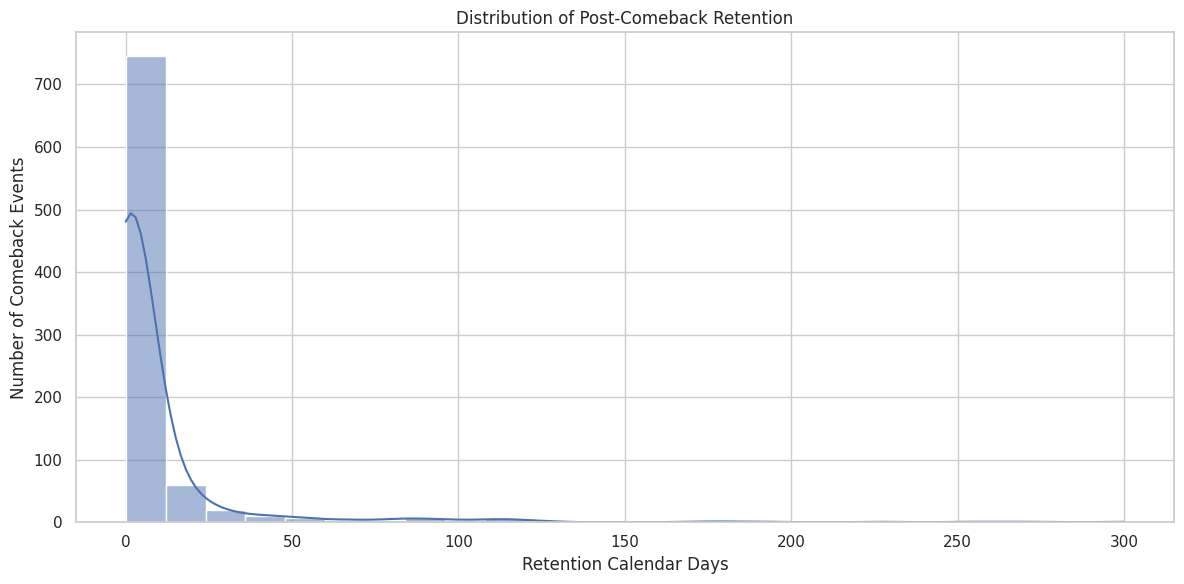

In [46]:
# ============================================================
# 9.6 POST-COMEBACK RETENTION VISUALIZATION
# ============================================================

if not retention_df.empty:

    plt.figure(figsize=(12, 6))

    sns.histplot(
        data=retention_df,
        x="retention_calendar_days",
        bins=25,
        kde=True
    )

    plt.title("Distribution of Post-Comeback Retention")
    plt.xlabel("Retention Calendar Days")
    plt.ylabel("Number of Comeback Events")
    plt.tight_layout()
    plt.show()

else:
    print("No retention data is available to visualize.")

In [47]:
# ============================================================
# 9.7 EXPORT SUSTAINABILITY RESULTS
# ============================================================

retention_df.to_csv(
    "South_Korea_Post_Comeback_Retention.csv",
    index=False
)

rank_decay_df.to_csv(
    "South_Korea_Rank_Decay.csv",
    index=False
)

volatility_df.to_csv(
    "South_Korea_Momentum_Volatility.csv",
    index=False
)

sustainability_summary.to_csv(
    "South_Korea_Sustainability_Summary.csv",
    index=False
)

print("Sustainability analysis exported successfully!")
print("1. South_Korea_Post_Comeback_Retention.csv")
print("2. South_Korea_Rank_Decay.csv")
print("3. South_Korea_Momentum_Volatility.csv")
print("4. South_Korea_Sustainability_Summary.csv")

Sustainability analysis exported successfully!
1. South_Korea_Post_Comeback_Retention.csv
2. South_Korea_Rank_Decay.csv
3. South_Korea_Momentum_Volatility.csv
4. South_Korea_Sustainability_Summary.csv


## **10. Content Attribute vs. Momentum Analysis**

In [48]:
# ============================================================
# 10.1 PREPARE CONTENT ANALYSIS DATASET
# ============================================================

# Start with the cleaned chart dataset
content_df = chart_df.copy()

# Convert numerical columns
numeric_columns = [
    "position",
    "popularity",
    "duration_ms",
    "total_tracks"
]

for column in numeric_columns:
    if column in content_df.columns:
        content_df[column] = pd.to_numeric(
            content_df[column],
            errors="coerce"
        )

# Convert duration from milliseconds to minutes
if "duration_ms" in content_df.columns:
    content_df["duration_minutes"] = (
        content_df["duration_ms"] / 60000
    )

# Display available content attributes
content_columns = [
    column for column in [
        "song",
        "artist",
        "album_type",
        "total_tracks",
        "duration_minutes",
        "is_explicit",
        "popularity",
        "position"
    ]
    if column in content_df.columns
]

print("Content analysis dataset prepared!")
print("Total Records:", len(content_df))
print("\nAvailable Analysis Columns:")

display(content_df[content_columns].head())


Content analysis dataset prepared!
Total Records: 27700

Available Analysis Columns:


,song,artist,album_type,total_tracks,duration_minutes,is_explicit,popularity,position
0,1-800-hot-n-fun,LE SSERAFIM,single,5,2.890517,false,64,26
1,1-800-hot-n-fun,LE SSERAFIM,single,5,2.890517,false,68,28
2,1-800-hot-n-fun,LE SSERAFIM,single,5,2.890517,false,70,28
3,1-800-hot-n-fun,LE SSERAFIM,single,5,2.890517,false,72,32
4,1-800-hot-n-fun,LE SSERAFIM,single,5,2.890517,false,73,45


In [49]:
# ============================================================
# 10.2 SINGLE VS. ALBUM-TRACK COMEBACK STRENGTH
# ============================================================

if not reentry_df.empty and "album_type" in content_df.columns:

    # Retrieve album type for each song
    song_metadata = (
        content_df
        .drop_duplicates("song_artist_id")
        [["song_artist_id", "album_type"]]
    )

    # Join album type to re-entry events
    content_reentries = reentry_df.merge(
        song_metadata,
        on="song_artist_id",
        how="left"
    )

    # Summarize comeback activity by album type
    comeback_by_album_type = (
        content_reentries
        .groupby("album_type", dropna=False)
        .agg(
            total_reentries=("song_artist_id", "size"),
            unique_songs=("song_artist_id", "nunique"),
            average_gap_days=("days_between_appearances", "mean")
        )
        .reset_index()
    )

    comeback_by_album_type["average_gap_days"] = (
        comeback_by_album_type["average_gap_days"].round(2)
    )

    print("Comeback Activity by Album Type")

    display(comeback_by_album_type)

else:
    print(
        "Re-entry events or album_type information "
        "are unavailable for this analysis."
    )

Comeback Activity by Album Type


,album_type,total_reentries,unique_songs,average_gap_days
0,album,365,77,11.26
1,single,509,153,9.54


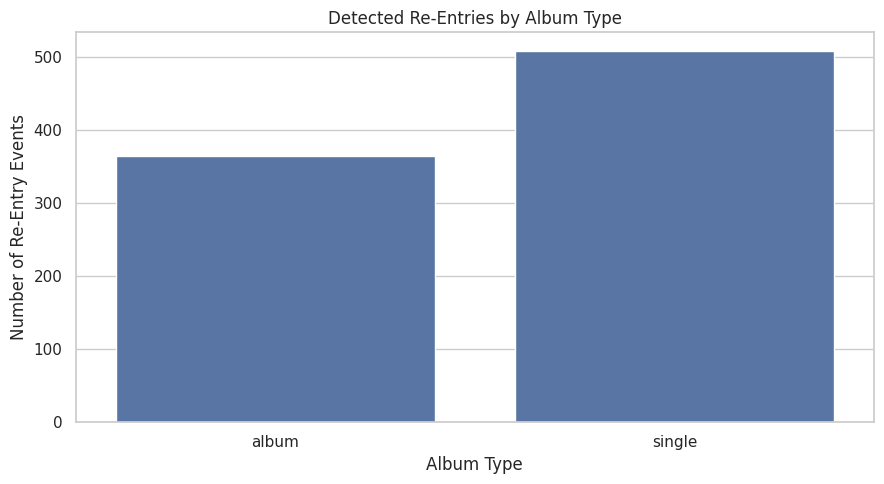

In [50]:
# ============================================================
# COMEBACK ACTIVITY BY ALBUM TYPE — VISUALIZATION
# ============================================================

if "comeback_by_album_type" in globals() and not comeback_by_album_type.empty:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=comeback_by_album_type,
        x="album_type",
        y="total_reentries"
    )

    plt.title("Detected Re-Entries by Album Type")
    plt.xlabel("Album Type")
    plt.ylabel("Number of Re-Entry Events")
    plt.tight_layout()
    plt.show()

else:
    print("No album-type comeback results to visualize.")

Album Size vs. Resurgence Intensity


,song,artist,total_tracks,average_momentum_score
0,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,3,2.873563
1,3D (Justin Timberlake Remix),Jung Kook & Justin Timberlake,1,2.298851
2,A bientot,Lim Young Woong,12,1.348149
3,A bientot,Lim Young Woong,12,1.348149
4,A bientot,Lim Young Woong,12,1.348149
5,A bientot,Lim Young Woong,12,1.348149
6,A bientot,Lim Young Woong,12,1.348149
7,A bientot,Lim Young Woong,12,1.348149
8,A bientot,Lim Young Woong,12,1.348149
9,A bientot,Lim Young Woong,12,1.348149


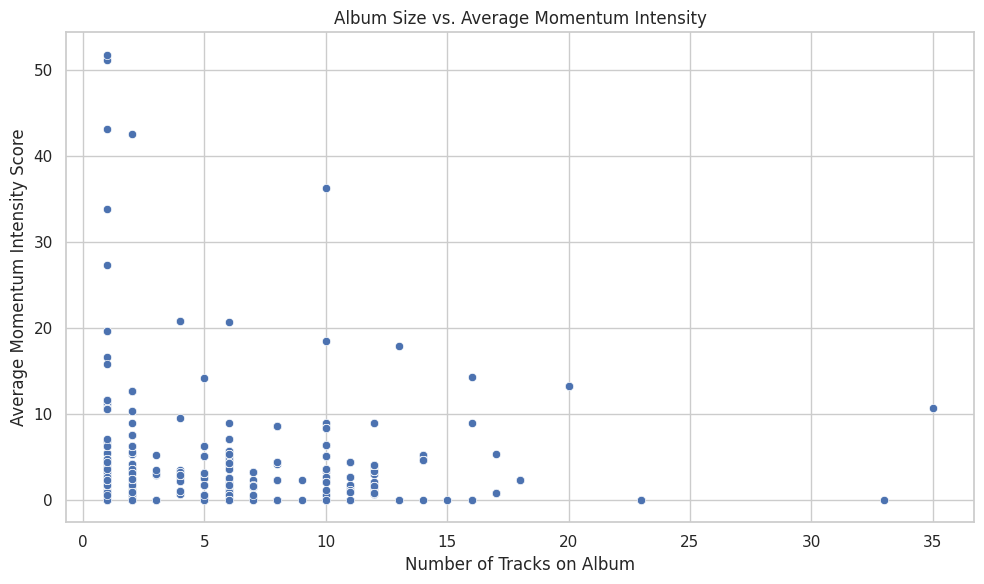

In [51]:
# ============================================================
# 10.3 ALBUM SIZE VS. RESURGENCE INTENSITY
# ============================================================

if (
    not reentry_df.empty
    and "total_tracks" in content_df.columns
    and not momentum_events.empty
):

    # Obtain album size for each song
    album_metadata = (
        content_df
        .drop_duplicates("song_artist_id")
        [["song_artist_id", "total_tracks"]]
    )

    # Aggregate momentum scores by song
    momentum_by_song = (
        momentum_events
        .groupby("song_artist_id")
        .agg(
            average_momentum_score=(
                "momentum_intensity_score", "mean"
            )
        )
        .reset_index()
    )

    album_momentum = (
        reentry_df
        .merge(album_metadata, on="song_artist_id", how="left")
        .merge(momentum_by_song, on="song_artist_id", how="left")
    )

    album_momentum["total_tracks"] = pd.to_numeric(
        album_momentum["total_tracks"],
        errors="coerce"
    )

    print("Album Size vs. Resurgence Intensity")

    display(
        album_momentum[
            [
                "song",
                "artist",
                "total_tracks",
                "average_momentum_score"
            ]
        ].head(20)
    )

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=album_momentum,
        x="total_tracks",
        y="average_momentum_score"
    )

    plt.title("Album Size vs. Average Momentum Intensity")
    plt.xlabel("Number of Tracks on Album")
    plt.ylabel("Average Momentum Intensity Score")
    plt.tight_layout()
    plt.show()

else:
    print(
        "Required re-entry events, album metadata, or "
        "momentum scores are unavailable."
    )

Song Duration vs. Momentum


,song,artist,duration_minutes,rank_improvement,popularity_change
0,Teddy Bear,STAYC,3.162883,0,0
1,Kill Bill,SZA,2.565767,0,0
2,LOVE DIVE,IVE,2.953100,-1,0
3,Love Always Run Away,Lim Young Woong,4.046000,3,0
4,VIBE (feat. Jimin of BTS),TAEYANG,2.929583,6,0
5,Interlude : Dive,Jimin,2.183267,-10,-1
6,Love Always Run Away,Lim Young Woong,4.046000,-3,0
7,Like Crazy (Deep House Remix),Jimin,3.011983,3,-1
8,Like Crazy (UK Garage Remix),Jimin,3.506583,3,-1
9,Promise,Jimin,2.516850,-2,-1


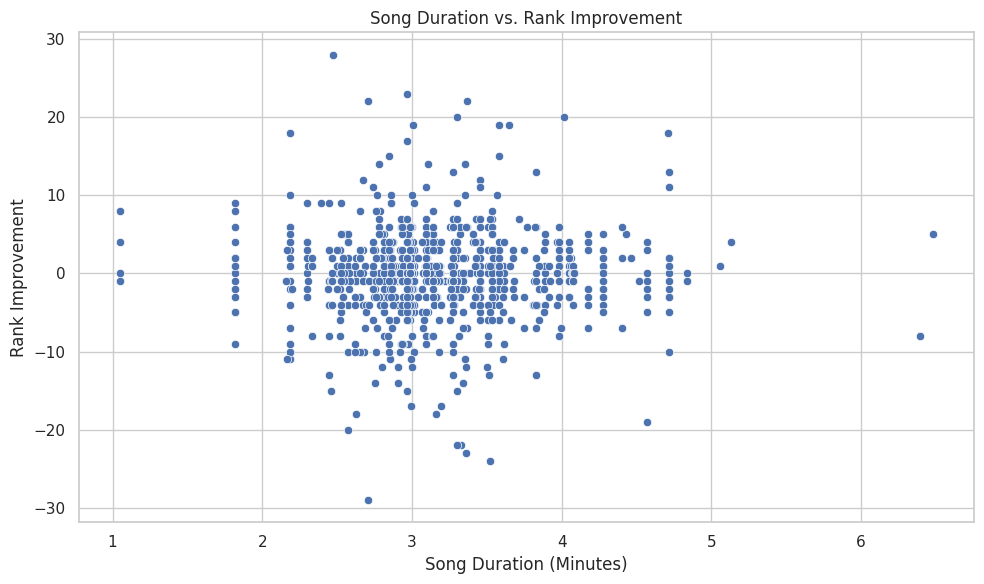

In [52]:
# ============================================================
# 10.4 SONG DURATION VS. MOMENTUM SPIKE MAGNITUDE
# ============================================================

if (
    not momentum_events.empty
    and "duration_ms" in content_df.columns
):

    # Retrieve song duration
    duration_metadata = (
        content_df
        .drop_duplicates("song_artist_id")
        [["song_artist_id", "duration_ms"]]
    )

    duration_metadata["duration_ms"] = pd.to_numeric(
        duration_metadata["duration_ms"],
        errors="coerce"
    )

    duration_metadata["duration_minutes"] = (
        duration_metadata["duration_ms"] / 60000
    )

    duration_momentum = momentum_events.merge(
        duration_metadata[
            ["song_artist_id", "duration_minutes"]
        ],
        on="song_artist_id",
        how="left"
    )

    print("Song Duration vs. Momentum")

    display(
        duration_momentum[
            [
                "song",
                "artist",
                "duration_minutes",
                "rank_improvement",
                "popularity_change"
            ]
        ].head(20)
    )

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=duration_momentum,
        x="duration_minutes",
        y="rank_improvement"
    )

    plt.title("Song Duration vs. Rank Improvement")
    plt.xlabel("Song Duration (Minutes)")
    plt.ylabel("Rank Improvement")
    plt.tight_layout()
    plt.show()

else:
    print(
        "Momentum event data or duration information "
        "is unavailable."
    )

Explicit vs. Clean-Content Momentum Analysis


,content_type,event_count,average_momentum_score,average_rank_improvement
0,Clean,831,3.377956,-0.263538
1,Explicit,43,7.778669,0.302326


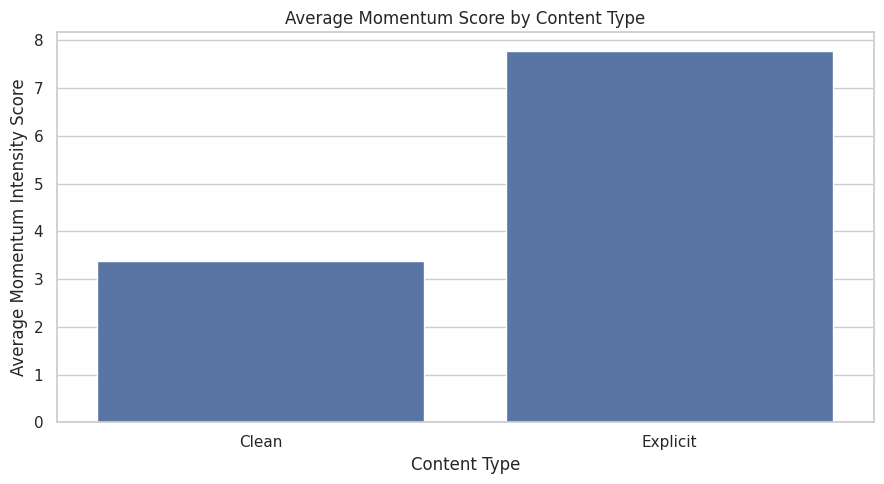

In [53]:
# ============================================================
# 10.5 EXPLICIT VS. CLEAN-CONTENT MOMENTUM
# ============================================================

# Step 1: Prepare explicit-content metadata
explicit_metadata = (
    df[["song_artist_id", "is_explicit"]]
    .drop_duplicates(subset=["song_artist_id"])
    .copy()
)

# Step 2: Remove any existing explicit-content column
# from momentum_events to avoid duplicate column names
momentum_base = momentum_events.drop(
    columns=["is_explicit", "is_explicit_x", "is_explicit_y"],
    errors="ignore"
).copy()

# Step 3: Merge the metadata
explicit_momentum = momentum_base.merge(
    explicit_metadata,
    on="song_artist_id",
    how="left",
    validate="many_to_one"
)

# Step 4: Standardize explicit-content labels
explicit_momentum["content_type"] = (
    explicit_momentum["is_explicit"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": "Explicit",
        "false": "Clean",
        "1": "Explicit",
        "0": "Clean",
        "yes": "Explicit",
        "no": "Clean"
    })
    .fillna("Unknown")
)

# Step 5: Calculate summary metrics
explicit_summary = (
    explicit_momentum
    .groupby("content_type")
    .agg(
        event_count=("song_artist_id", "size"),
        average_momentum_score=(
            "momentum_intensity_score", "mean"
        ),
        average_rank_improvement=(
            "rank_improvement", "mean"
        )
    )
    .reset_index()
)

print("Explicit vs. Clean-Content Momentum Analysis")
print("=" * 60)

display(explicit_summary)

# Step 6: Visualize the results
plot_data = explicit_summary[
    explicit_summary["content_type"].isin(
        ["Explicit", "Clean"]
    )
]

if not plot_data.empty:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=plot_data,
        x="content_type",
        y="average_momentum_score"
    )

    plt.title("Average Momentum Score by Content Type")
    plt.xlabel("Content Type")
    plt.ylabel("Average Momentum Intensity Score")

    plt.tight_layout()
    plt.show()

else:
    print("No classified explicit or clean tracks to visualize.")

In [54]:
# ============================================================
# 10.6 EXPORT CONTENT ATTRIBUTE ANALYSIS
# ============================================================

content_df.to_csv(
    "South_Korea_Content_Analysis.csv",
    index=False
)

if "comeback_by_album_type" in globals():
    comeback_by_album_type.to_csv(
        "South_Korea_Album_Type_Comeback_Analysis.csv",
        index=False
    )

if "album_momentum" in globals():
    album_momentum.to_csv(
        "South_Korea_Album_Size_Momentum_Analysis.csv",
        index=False
    )

if "duration_momentum" in globals():
    duration_momentum.to_csv(
        "South_Korea_Duration_Momentum_Analysis.csv",
        index=False
    )

if "explicit_summary" in globals():
    explicit_summary.to_csv(
        "South_Korea_Explicit_Content_Momentum.csv",
        index=False
    )

print("Content attribute analysis exports completed!")

Content attribute analysis exports completed!


## **11. Fandom Engagement Proxy Analysis**

In [55]:
# ============================================================
# 11.1 PREPARE FANDOM ANALYSIS DATA
# ============================================================

# Prepare the chart dataset
fandom_df = chart_df.copy()

fandom_df["date"] = pd.to_datetime(
    fandom_df["date"],
    errors="coerce"
)

fandom_df["position"] = pd.to_numeric(
    fandom_df["position"],
    errors="coerce"
)

if "popularity" in fandom_df.columns:
    fandom_df["popularity"] = pd.to_numeric(
        fandom_df["popularity"],
        errors="coerce"
    )

fandom_df = fandom_df.dropna(
    subset=["date", "position", "song_artist_id"]
)

fandom_df = fandom_df.sort_values(
    ["song_artist_id", "date"]
).reset_index(drop=True)

print("Fandom analysis data prepared successfully!")
print("Total records:", len(fandom_df))
print("Unique songs:", fandom_df["song_artist_id"].nunique())

display(fandom_df.head())

Fandom analysis data prepared successfully!
Total records: 27700
Unique songs: 537


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,song_artist_id
0,2025-09-01,26,1-800-hot-n-fun,LE SSERAFIM,64,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
1,2025-09-02,28,1-800-hot-n-fun,LE SSERAFIM,68,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
2,2025-09-03,28,1-800-hot-n-fun,LE SSERAFIM,70,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
3,2025-09-04,32,1-800-hot-n-fun,LE SSERAFIM,72,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim
4,2025-09-05,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim


In [56]:
# ============================================================
# 11.2 RE-ENTRY FREQUENCY ANALYSIS
# ============================================================

if not reentry_df.empty:

    fandom_reentry_frequency = (
        reentry_df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            reentry_frequency=("reentry_date", "count")
        )
        .reset_index()
        .sort_values(
            "reentry_frequency",
            ascending=False
        )
    )

    print("Re-Entry Frequency by Song")

    display(fandom_reentry_frequency.head(20))

else:

    fandom_reentry_frequency = pd.DataFrame(
        columns=[
            "song_artist_id",
            "song",
            "artist",
            "reentry_frequency"
        ]
    )

    print("No re-entry events are available.")

Re-Entry Frequency by Song


,song_artist_id,song,artist,reentry_frequency
143,"our blues, our life | lim young woong","Our Blues, Our Life",Lim Young Woong,28
47,ditto | newjeans,Ditto,NewJeans,26
2,a bientot | lim young woong,A bientot,Lim Young Woong,22
137,new jeans | newjeans,New Jeans,NewJeans,20
82,hype boy | newjeans,Hype Boy,NewJeans,19
91,interlude : dive | jimin,Interlude : Dive,Jimin,19
55,eta | newjeans,ETA,NewJeans,16
153,rainbow | lim young woong,Rainbow,Lim Young Woong,16
167,somebody | jung kook,Somebody,Jung Kook,15
142,omg | newjeans,OMG,NewJeans,14


In [57]:
# ============================================================
# 11.3 POPULARITY SPIKE SHARPNESS
# ============================================================

spike_records = []

if not reentry_df.empty and "popularity" in fandom_df.columns:

    for _, event in reentry_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = pd.Timestamp(event["reentry_date"])
        previous_date = pd.Timestamp(event["previous_chart_date"])

        # Popularity immediately before the absence
        previous_rows = fandom_df[
            (fandom_df["song_artist_id"] == song_id)
            & (fandom_df["date"] == previous_date)
        ]

        # Popularity on the re-entry date
        reentry_rows = fandom_df[
            (fandom_df["song_artist_id"] == song_id)
            & (fandom_df["date"] == reentry_date)
        ]

        if previous_rows.empty or reentry_rows.empty:
            continue

        previous_popularity = previous_rows["popularity"].iloc[-1]
        reentry_popularity = reentry_rows["popularity"].iloc[-1]

        if pd.isna(previous_popularity) or pd.isna(reentry_popularity):
            continue

        elapsed_days = max(
            (reentry_date - previous_date).days,
            1
        )

        popularity_change = (
            reentry_popularity - previous_popularity
        )

        spike_records.append({
            "song_artist_id": song_id,
            "song": event["song"],
            "artist": event["artist"],
            "reentry_date": reentry_date,
            "previous_popularity": previous_popularity,
            "reentry_popularity": reentry_popularity,
            "popularity_change": popularity_change,
            "popularity_spike_sharpness": (
                max(popularity_change, 0) / elapsed_days
            )
        })

spike_df = pd.DataFrame(spike_records)

if not spike_df.empty:

    print("Popularity Spike Sharpness")

    display(
        spike_df.sort_values(
            "popularity_spike_sharpness",
            ascending=False
        ).head(20)
    )

else:
    print("Popularity spike measurements are unavailable.")

Popularity Spike Sharpness


,song_artist_id,song,artist,reentry_date,previous_popularity,reentry_popularity,popularity_change,popularity_spike_sharpness
368,k-pop | travis scott & bad bunny & the weeknd,K-POP,Travis Scott & Bad Bunny & The Weeknd,2024-07-29,4,91,87,29.000000
846,you & me (coachella ver.) | jennie,You & Me (Coachella ver.),JENNIE,2024-10-10,0,74,74,24.666667
540,no tomorrow - spotify singles | various artists,No Tomorrow - Spotify Singles,Various Artists,2025-04-10,30,45,15,7.500000
91,chihiro | billie eilish,CHIHIRO,Billie Eilish,2025-05-23,61,90,29,7.250000
328,i will come to you | jin,I will come to you,Jin,2025-11-23,43,53,10,5.000000
691,spring snow | 10cm,Spring Snow,10CM,2025-05-19,60,69,9,4.500000
653,seven (feat. latto) (explicit ver.) | jung koo...,Seven (feat. Latto) (Explicit Ver.),Jung Kook & Latto,2024-07-19,86,95,9,3.000000
47,armageddon | aespa & grimes & flava d,Armageddon,aespa & Grimes & Flava D,2025-10-06,0,36,36,2.400000
226,euphoria | kendrick lamar,euphoria,Kendrick Lamar,2025-05-06,85,89,4,2.000000
654,seven (feat. latto) (instrumental) | jung kook...,Seven (feat. Latto) (Instrumental),Jung Kook & Latto,2024-07-19,74,80,6,2.000000


In [58]:
# ============================================================
# 11.4 RANK RECOVERY SPEED
# ============================================================

recovery_records = []

if not retention_df.empty:

    for _, event in retention_df.iterrows():

        song_id = event["song_artist_id"]
        reentry_date = pd.Timestamp(event["reentry_date"])
        last_chart_date = pd.Timestamp(event["last_chart_date"])

        run_data = fandom_df[
            (fandom_df["song_artist_id"] == song_id)
            & (fandom_df["date"] >= reentry_date)
            & (fandom_df["date"] <= last_chart_date)
        ].sort_values("date")

        if run_data.empty:
            continue

        reentry_position = run_data.iloc[0]["position"]

        peak_index = run_data["position"].idxmin()
        peak_record = run_data.loc[peak_index]

        peak_position = peak_record["position"]
        peak_date = peak_record["date"]

        rank_improvement = (
            reentry_position - peak_position
        )

        recovery_days = (
            peak_date - reentry_date
        ).days

        # Positive values indicate improvement in chart position
        # per elapsed calendar day.
        if recovery_days > 0:
            recovery_speed = rank_improvement / recovery_days
        elif recovery_days == 0 and rank_improvement > 0:
            recovery_speed = np.nan
        else:
            recovery_speed = 0.0

        recovery_records.append({
            "song_artist_id": song_id,
            "song": event["song"],
            "artist": event["artist"],
            "reentry_date": reentry_date,
            "reentry_position": reentry_position,
            "peak_position": peak_position,
            "peak_date": peak_date,
            "rank_improvement": rank_improvement,
            "recovery_days": recovery_days,
            "rank_recovery_speed": recovery_speed
        })

recovery_df = pd.DataFrame(recovery_records)

if not recovery_df.empty:

    print("Rank Recovery Speed Analysis")

    display(
        recovery_df.sort_values(
            "rank_recovery_speed",
            ascending=False,
            na_position="last"
        ).head(20)
    )

else:
    print("Rank recovery measurements are unavailable.")

Rank Recovery Speed Analysis


,song_artist_id,song,artist,reentry_date,reentry_position,peak_position,peak_date,rank_improvement,recovery_days,rank_recovery_speed
793,who (acoustic remix) | jimin,Who (Acoustic Remix),Jimin,2025-09-21,50,29,2025-09-22,21,1,21.0
600,please don't change (feat. dj snake) | jung kook,Please Don't Change (feat. DJ Snake),Jung Kook,2024-12-28,50,31,2024-12-29,19,1,19.0
607,please don't change (feat. dj snake) | jung kook,Please Don't Change (feat. DJ Snake),Jung Kook,2025-02-13,45,30,2025-02-14,15,1,15.0
377,left and right (feat. jung kook of bts) | char...,Left and Right (Feat. Jung Kook of BTS),Charlie Puth,2024-10-26,30,15,2024-10-27,15,1,15.0
598,perfect night | le sserafim,Perfect Night,LE SSERAFIM,2025-09-01,45,30,2025-09-02,15,1,15.0
376,last christmas - single version | wham!,Last Christmas - Single Version,Wham!,2024-12-23,42,13,2024-12-25,29,2,14.5
195,dreamers [music from the fifa world cup qatar ...,Dreamers [Music from the FIFA World Cup Qatar ...,Jung Kook & BTS,2024-10-20,42,28,2024-10-21,14,1,14.0
626,pump up the volume! | plave,Pump Up The Volume!,PLAVE,2025-10-24,47,33,2025-10-25,14,1,14.0
508,nemonemo | yena,NEMONEMO,YENA,2025-10-25,50,36,2025-10-26,14,1,14.0
728,take two | bts,Take Two,BTS,2024-11-07,49,35,2024-11-08,14,1,14.0


In [59]:
# ============================================================
# 11.5 FANDOM INTENSITY PROXY SCORE
# ============================================================

# Begin with re-entry frequency
fandom_scores = fandom_reentry_frequency.copy()

# Merge average popularity spike sharpness by song
if not spike_df.empty:

    spike_summary = (
        spike_df.groupby("song_artist_id")
        .agg(
            average_spike_sharpness=(
                "popularity_spike_sharpness",
                "mean"
            )
        )
        .reset_index()
    )

    fandom_scores = fandom_scores.merge(
        spike_summary,
        on="song_artist_id",
        how="left"
    )

else:

    fandom_scores["average_spike_sharpness"] = np.nan

# Merge rank recovery speed by song
if not recovery_df.empty:

    recovery_summary = (
        recovery_df.groupby("song_artist_id")
        .agg(
            average_rank_recovery_speed=(
                "rank_recovery_speed",
                "mean"
            )
        )
        .reset_index()
    )

    fandom_scores = fandom_scores.merge(
        recovery_summary,
        on="song_artist_id",
        how="left"
    )

else:

    fandom_scores["average_rank_recovery_speed"] = np.nan


# Normalize each indicator on a 0–100 scale
def normalize_indicator(series):

    numeric_series = pd.to_numeric(
        series,
        errors="coerce"
    )

    valid = numeric_series.dropna()

    if valid.empty:
        return pd.Series(
            np.nan,
            index=numeric_series.index
        )

    minimum = valid.min()
    maximum = valid.max()

    if maximum == minimum:
        return pd.Series(
            np.where(numeric_series.notna(), 50.0, np.nan),
            index=numeric_series.index
        )

    return (
        (numeric_series - minimum)
        / (maximum - minimum)
        * 100
    )


fandom_scores["reentry_frequency_score"] = normalize_indicator(
    fandom_scores["reentry_frequency"]
)

fandom_scores["spike_sharpness_score"] = normalize_indicator(
    fandom_scores["average_spike_sharpness"]
)

fandom_scores["rank_recovery_score"] = normalize_indicator(
    fandom_scores["average_rank_recovery_speed"]
)

# Calculate the mean of available component scores
score_columns = [
    "reentry_frequency_score",
    "spike_sharpness_score",
    "rank_recovery_score"
]

fandom_scores["fandom_intensity_proxy_score"] = (
    fandom_scores[score_columns].mean(axis=1)
)

# Rank songs by their proxy score
fandom_leaderboard = fandom_scores.sort_values(
    "fandom_intensity_proxy_score",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("Fandom Intensity Proxy Leaderboard")

display(
    fandom_leaderboard[
        [
            "song",
            "artist",
            "reentry_frequency",
            "average_spike_sharpness",
            "average_rank_recovery_speed",
            "fandom_intensity_proxy_score"
        ]
    ].head(20)
)

Fandom Intensity Proxy Leaderboard


,song,artist,reentry_frequency,average_spike_sharpness,average_rank_recovery_speed,fandom_intensity_proxy_score
0,"Our Blues, Our Life",Lim Young Woong,28,0.069643,0.783695,35.214980
1,K-POP,Travis Scott & Bad Bunny & The Weeknd,1,29.000000,0.000000,33.333333
2,Last Christmas - Single Version,Wham!,1,0.000000,14.500000,33.333333
3,Ditto,NewJeans,26,0.011095,0.626068,32.316188
4,Take Two,BTS,1,0.000000,14.000000,32.183908
5,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,1,1.250000,12.000000,29.022989
6,A bientot,Lim Young Woong,22,0.014399,1.321023,28.979310
7,You & Me (Coachella ver.),JENNIE,1,24.666667,0.000000,28.352490
8,Interlude : Dive,Jimin,19,0.065414,2.426686,27.875999
9,New Jeans,NewJeans,20,0.041667,0.309070,24.215190


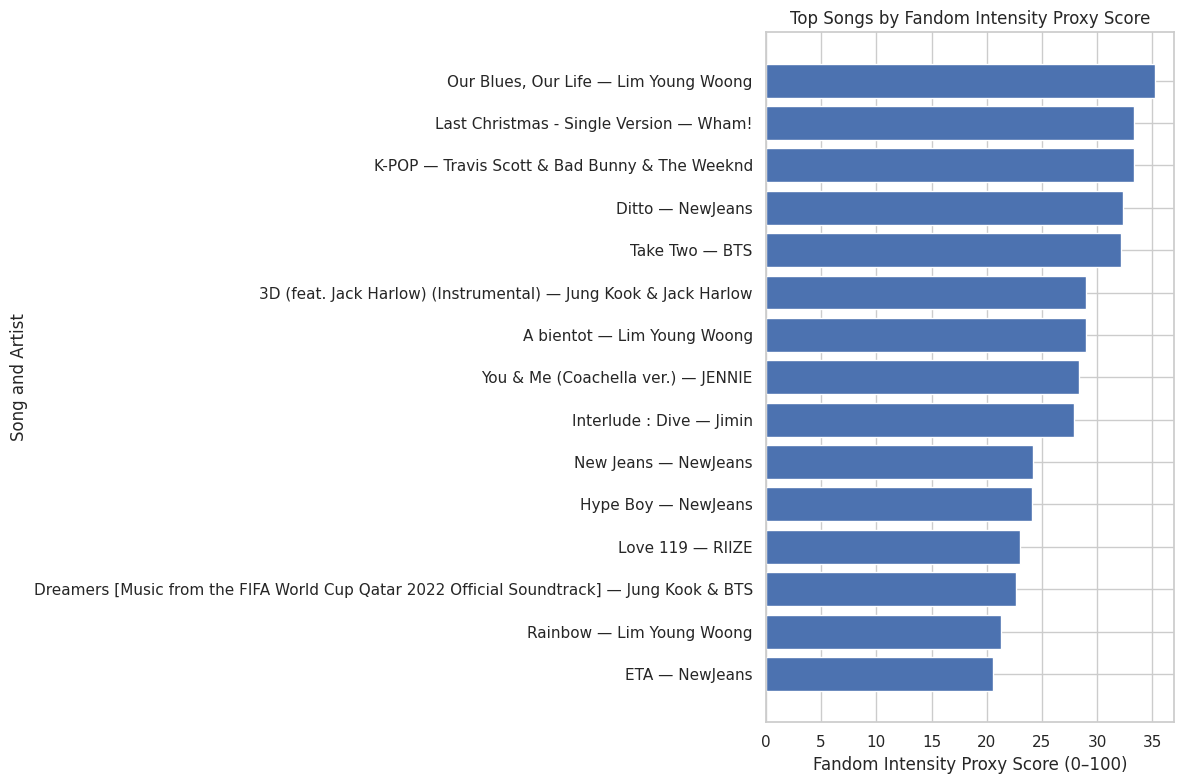

In [60]:
# ============================================================
# 11.6 FANDOM INTENSITY LEADERBOARD VISUALIZATION
# ============================================================

if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):

    leaderboard_plot = (
        fandom_leaderboard
        .dropna(subset=["fandom_intensity_proxy_score"])
        .head(15)
        .copy()
    )

    if not leaderboard_plot.empty:

        leaderboard_plot["song_label"] = (
            leaderboard_plot["song"].fillna("Unknown Song")
            + " — "
            + leaderboard_plot["artist"].fillna("Unknown Artist")
        )

        leaderboard_plot = leaderboard_plot.sort_values(
            "fandom_intensity_proxy_score",
            ascending=True
        )

        plt.figure(figsize=(12, 8))

        plt.barh(
            leaderboard_plot["song_label"],
            leaderboard_plot["fandom_intensity_proxy_score"]
        )

        plt.title("Top Songs by Fandom Intensity Proxy Score")
        plt.xlabel("Fandom Intensity Proxy Score (0–100)")
        plt.ylabel("Song and Artist")

        plt.tight_layout()
        plt.show()

    else:
        print("No valid fandom scores are available to visualize.")

else:
    print("Fandom leaderboard is not available.")

In [61]:
# ============================================================
# 11.7 EXPORT FANDOM ENGAGEMENT RESULTS
# ============================================================

fandom_reentry_frequency.to_csv(
    "South_Korea_Fandom_Reentry_Frequency.csv",
    index=False
)

spike_df.to_csv(
    "South_Korea_Popularity_Spike_Sharpness.csv",
    index=False
)

recovery_df.to_csv(
    "South_Korea_Rank_Recovery_Speed.csv",
    index=False
)

fandom_leaderboard.to_csv(
    "South_Korea_Fandom_Intensity_Leaderboard.csv",
    index=False
)

print("Fandom engagement analysis exported successfully!")
print("1. South_Korea_Fandom_Reentry_Frequency.csv")
print("2. South_Korea_Popularity_Spike_Sharpness.csv")
print("3. South_Korea_Rank_Recovery_Speed.csv")
print("4. South_Korea_Fandom_Intensity_Leaderboard.csv")

Fandom engagement analysis exported successfully!
1. South_Korea_Fandom_Reentry_Frequency.csv
2. South_Korea_Popularity_Spike_Sharpness.csv
3. South_Korea_Rank_Recovery_Speed.csv
4. South_Korea_Fandom_Intensity_Leaderboard.csv


## **12. Key Performance Indicators (KPIs)**

In [62]:
# ============================================================
# 12.1 PREPARE KPI ANALYSIS
# ============================================================

print("KPI Analysis Preparation")
print("=" * 60)

print("Detected Re-Entry Events:", len(reentry_df))
print("Songs with Re-Entries:", reentry_df["song_artist_id"].nunique())
print("Event-Level Momentum Records:", len(momentum_events))
print("Retention Records:", len(retention_df))
print("Fandom Leaderboard Records:", len(fandom_leaderboard))

print("\nRequired KPI Components:")
print("1. Re-Entry Frequency")
print("2. Momentum Spike Score")
print("3. Post-Comeback Retention Days")
print("4. Rank Recovery Speed")
print("5. Album Comeback Advantage Index")
print("6. Fandom Intensity Proxy Score")

KPI Analysis Preparation
Detected Re-Entry Events: 874
Songs with Re-Entries: 230
Event-Level Momentum Records: 874
Retention Records: 874
Fandom Leaderboard Records: 230

Required KPI Components:
1. Re-Entry Frequency
2. Momentum Spike Score
3. Post-Comeback Retention Days
4. Rank Recovery Speed
5. Album Comeback Advantage Index
6. Fandom Intensity Proxy Score


In [63]:
# ============================================================
# 12.2 RE-ENTRY FREQUENCY KPI
# ============================================================

if not reentry_df.empty:

    reentry_frequency_kpi = (
        reentry_df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            reentry_frequency=("reentry_date", "count")
        )
        .reset_index()
        .sort_values("reentry_frequency", ascending=False)
    )

    print("Re-Entry Frequency KPI")
    display(reentry_frequency_kpi.head(20))

    print(
        "\nTotal Detected Re-Entry Events:",
        len(reentry_df)
    )

else:

    reentry_frequency_kpi = pd.DataFrame()

    print("No re-entry events are available.")

Re-Entry Frequency KPI


,song_artist_id,song,artist,reentry_frequency
143,"our blues, our life | lim young woong","Our Blues, Our Life",Lim Young Woong,28
47,ditto | newjeans,Ditto,NewJeans,26
2,a bientot | lim young woong,A bientot,Lim Young Woong,22
137,new jeans | newjeans,New Jeans,NewJeans,20
82,hype boy | newjeans,Hype Boy,NewJeans,19
91,interlude : dive | jimin,Interlude : Dive,Jimin,19
55,eta | newjeans,ETA,NewJeans,16
153,rainbow | lim young woong,Rainbow,Lim Young Woong,16
167,somebody | jung kook,Somebody,Jung Kook,15
142,omg | newjeans,OMG,NewJeans,14



Total Detected Re-Entry Events: 874


In [64]:
# ============================================================
# 12.3 MOMENTUM SPIKE SCORE KPI
# ============================================================

if (
    "momentum_events" in globals()
    and not momentum_events.empty
    and "momentum_intensity_score" in momentum_events.columns
):

    momentum_kpi = (
        momentum_events.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            average_momentum_spike_score=(
                "momentum_intensity_score", "mean"
            ),
            maximum_momentum_spike_score=(
                "momentum_intensity_score", "max"
            )
        )
        .reset_index()
        .sort_values(
            "average_momentum_spike_score",
            ascending=False
        )
    )

    print("Momentum Spike Score KPI")
    display(momentum_kpi.head(20))

else:

    momentum_kpi = pd.DataFrame()

    print("Momentum intensity scores are unavailable.")

Momentum Spike Score KPI


,song_artist_id,song,artist,average_momentum_spike_score,maximum_momentum_spike_score
95,k-pop | travis scott & bad bunny & the weeknd,K-POP,Travis Scott & Bad Bunny & The Weeknd,51.785714,51.785714
94,jealousyvalhalla | yanghongwon,Jealousyvalhalla,YANGHONGWON,51.149425,51.149425
110,lost and found | kinglee & lil' flip,Lost and Found,KingLee & Lil' Flip,43.123974,43.123974
221,you & me (coachella ver.) | jennie,You & Me (Coachella ver.),JENNIE,42.528736,42.528736
4,all i want for christmas is you | mariah carey,All I Want for Christmas Is You,Mariah Carey,36.288998,36.288998
194,the astronaut | jin,The Astronaut,Jin,33.866995,33.866995
42,cupido | engel montaz & kuv507 & latinnites music,Cupido,Engel Montaz & Kuv507 & Latinnites Music,27.360427,27.360427
155,seven (feat. latto) (alesso remix) | jung kook...,Seven (feat. Latto) (Alesso Remix),Jung Kook & Latto,20.792282,39.860427
11,armageddon | aespa & grimes & flava d,Armageddon,aespa & Grimes & Flava D,20.689655,20.689655
220,"yes, and? | ariana grande","yes, and?",Ariana Grande,19.642857,33.928571


In [65]:
# ============================================================
# 12.4 POST-COMEBACK RETENTION DAYS KPI
# ============================================================

if not retention_df.empty:

    retention_kpi = (
        retention_df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            average_retention_days=(
                "retention_calendar_days", "mean"
            ),
            maximum_retention_days=(
                "retention_calendar_days", "max"
            ),
            comeback_events=("reentry_date", "count")
        )
        .reset_index()
        .sort_values(
            "average_retention_days",
            ascending=False
        )
    )

    print("Post-Comeback Retention KPI")
    display(retention_kpi.head(20))

else:

    retention_kpi = pd.DataFrame()

    print("Retention data is unavailable.")

Post-Comeback Retention KPI


,song_artist_id,song,artist,average_retention_days,maximum_retention_days,comeback_events
173,standing next to you | jung kook,Standing Next to You,Jung Kook,269.000000,269,1
19,birds of a feather | billie eilish,BIRDS OF A FEATHER,Billie Eilish,180.000000,180,1
88,if we ever meet again | lim young woong,If We Ever Meet Again,Lim Young Woong,107.750000,300,4
157,seven (feat. latto) (explicit ver.) | jung koo...,Seven (feat. Latto) (Explicit Ver.),Jung Kook & Latto,107.000000,107,1
76,happy | day6,HAPPY,DAY6,90.000000,90,1
105,like crazy | jimin,Like Crazy,Jimin,83.000000,83,1
186,supernova | aespa,Supernova,aespa,66.000000,66,1
144,people pt.2 (feat. iu) | agust d,People Pt.2 (feat. IU),Agust D,62.500000,125,2
163,slow dancing | v,Slow Dancing,V,56.750000,225,4
16,beautiful things | benson boone,Beautiful Things,Benson Boone,42.000000,84,2


In [66]:
# ============================================================
# 12.5 RANK RECOVERY SPEED KPI
# ============================================================

if not recovery_df.empty:

    recovery_kpi = (
        recovery_df.groupby("song_artist_id")
        .agg(
            song=("song", "first"),
            artist=("artist", "first"),
            average_rank_recovery_speed=(
                "rank_recovery_speed", "mean"
            ),
            average_rank_improvement=(
                "rank_improvement", "mean"
            )
        )
        .reset_index()
        .sort_values(
            "average_rank_recovery_speed",
            ascending=False,
            na_position="last"
        )
    )

    print("Rank Recovery Speed KPI")
    display(recovery_kpi.head(20))

else:

    recovery_kpi = pd.DataFrame()

    print("Rank recovery data is unavailable.")

Rank Recovery Speed KPI


,song_artist_id,song,artist,average_rank_recovery_speed,average_rank_improvement
99,last christmas - single version | wham!,Last Christmas - Single Version,Wham!,14.500000,29.000000
189,take two | bts,Take Two,BTS,14.000000,14.000000
0,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,12.000000,12.000000
111,love 119 | riize,Love 119,RIIZE,10.000000,10.000000
51,dreamers [music from the fifa world cup qatar ...,Dreamers [Music from the FIFA World Cup Qatar ...,Jung Kook & BTS,8.250000,8.250000
41,cupid | fifty fifty,Cupid,FIFTY FIFTY,8.000000,8.000000
151,pump up the volume! | plave,Pump Up The Volume!,PLAVE,8.000000,8.000000
139,night dancer - big naughty remix | imase & big...,NIGHT DANCER - BIG Naughty Remix,imase & BIG Naughty,6.500000,13.000000
211,who (acoustic remix) | jimin,Who (Acoustic Remix),Jimin,6.303571,14.000000
207,way 4 luv | plave,WAY 4 LUV,PLAVE,6.000000,6.000000


In [67]:
# ============================================================
# 12.6 ALBUM COMEBACK ADVANTAGE INDEX
# ============================================================

album_advantage = pd.DataFrame()
album_type_summary = pd.DataFrame()

if (
    not momentum_kpi.empty
    and "album_type" in df.columns
):

    album_metadata = (
        df[["song_artist_id", "album_type"]]
        .drop_duplicates("song_artist_id")
    )

    album_momentum_kpi = momentum_kpi.merge(
        album_metadata,
        on="song_artist_id",
        how="left",
        validate="one_to_one"
    )

    album_type_summary = (
        album_momentum_kpi
        .groupby("album_type", dropna=False)
        .agg(
            songs=("song_artist_id", "nunique"),
            average_momentum_score=(
                "average_momentum_spike_score", "mean"
            )
        )
        .reset_index()
    )

    print("Average Momentum by Album Type")
    display(album_type_summary)

    single_rows = album_type_summary[
        album_type_summary["album_type"].astype(str).str.lower()
        == "single"
    ]

    album_rows = album_type_summary[
        album_type_summary["album_type"].astype(str).str.lower()
        == "album"
    ]

    if not single_rows.empty and not album_rows.empty:

        single_score = single_rows[
            "average_momentum_score"
        ].iloc[0]

        album_score = album_rows[
            "average_momentum_score"
        ].iloc[0]

        if pd.notna(single_score) and pd.notna(album_score):

            album_advantage = pd.DataFrame([{
                "single_average_momentum_score": single_score,
                "album_average_momentum_score": album_score,
                "album_minus_single_advantage": (
                    album_score - single_score
                )
            }])

            print("\nAlbum Comeback Advantage Index")
            display(album_advantage)

            if album_score > single_score:
                print("Album tracks have a higher average momentum score.")
            elif album_score < single_score:
                print("Singles have a higher average momentum score.")
            else:
                print("Both groups have equal average momentum scores.")

    else:
        print(
            "Both 'single' and 'album' categories were not found. "
            "Check the actual album_type values before comparing."
        )

else:

    print(
        "Momentum KPI data or album_type information is unavailable."
    )

Average Momentum by Album Type


,album_type,songs,average_momentum_score
0,album,77,3.609027
1,single,153,4.796853



Album Comeback Advantage Index


,single_average_momentum_score,album_average_momentum_score,album_minus_single_advantage
0,4.796853,3.609027,-1.187826


Singles have a higher average momentum score.


In [68]:
# ============================================================
# 12.7 FANDOM INTENSITY PROXY SCORE KPI
# ============================================================

if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):

    fandom_kpi = fandom_leaderboard[
        [
            "song_artist_id",
            "song",
            "artist",
            "reentry_frequency",
            "average_spike_sharpness",
            "average_rank_recovery_speed",
            "fandom_intensity_proxy_score"
        ]
    ].copy()

    fandom_kpi = fandom_kpi.sort_values(
        "fandom_intensity_proxy_score",
        ascending=False,
        na_position="last"
    )

    print("Fandom Intensity Proxy KPI")
    display(fandom_kpi.head(20))

else:

    fandom_kpi = pd.DataFrame()

    print("Fandom intensity scores are unavailable.")

Fandom Intensity Proxy KPI


,song_artist_id,song,artist,reentry_frequency,average_spike_sharpness,average_rank_recovery_speed,fandom_intensity_proxy_score
0,"our blues, our life | lim young woong","Our Blues, Our Life",Lim Young Woong,28,0.069643,0.783695,35.214980
1,k-pop | travis scott & bad bunny & the weeknd,K-POP,Travis Scott & Bad Bunny & The Weeknd,1,29.000000,0.000000,33.333333
2,last christmas - single version | wham!,Last Christmas - Single Version,Wham!,1,0.000000,14.500000,33.333333
3,ditto | newjeans,Ditto,NewJeans,26,0.011095,0.626068,32.316188
4,take two | bts,Take Two,BTS,1,0.000000,14.000000,32.183908
5,3d (feat. jack harlow) (instrumental) | jung k...,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,1,1.250000,12.000000,29.022989
6,a bientot | lim young woong,A bientot,Lim Young Woong,22,0.014399,1.321023,28.979310
7,you & me (coachella ver.) | jennie,You & Me (Coachella ver.),JENNIE,1,24.666667,0.000000,28.352490
8,interlude : dive | jimin,Interlude : Dive,Jimin,19,0.065414,2.426686,27.875999
9,new jeans | newjeans,New Jeans,NewJeans,20,0.041667,0.309070,24.215190


In [69]:
# ============================================================
# 12.8 CONSOLIDATED KPI SUMMARY
# ============================================================

kpi_tables = []

# Re-entry frequency
if not reentry_frequency_kpi.empty:

    temp = reentry_frequency_kpi[
        ["song_artist_id", "song", "artist", "reentry_frequency"]
    ].copy()

    kpi_tables.append(temp)

# Momentum spike score
if not momentum_kpi.empty:

    temp = momentum_kpi[
        [
            "song_artist_id",
            "song",
            "artist",
            "average_momentum_spike_score"
        ]
    ].copy()

    kpi_tables.append(temp)

# Retention days
if not retention_kpi.empty:

    temp = retention_kpi[
        [
            "song_artist_id",
            "song",
            "artist",
            "average_retention_days"
        ]
    ].copy()

    kpi_tables.append(temp)

# Rank recovery speed
if not recovery_kpi.empty:

    temp = recovery_kpi[
        [
            "song_artist_id",
            "song",
            "artist",
            "average_rank_recovery_speed"
        ]
    ].copy()

    kpi_tables.append(temp)

# Fandom intensity
if not fandom_kpi.empty:

    temp = fandom_kpi[
        [
            "song_artist_id",
            "song",
            "artist",
            "fandom_intensity_proxy_score"
        ]
    ].copy()

    kpi_tables.append(temp)


if kpi_tables:

    # Build a master song list
    kpi_summary = (
        df[["song_artist_id", "song", "artist"]]
        .drop_duplicates("song_artist_id")
        .copy()
    )

    # Merge each available KPI table
    for table in kpi_tables:

        table = table.drop(
            columns=["song", "artist"],
            errors="ignore"
        )

        kpi_summary = kpi_summary.merge(
            table,
            on="song_artist_id",
            how="left"
        )

    print("Consolidated KPI Summary")
    display(kpi_summary.head(25))

else:

    kpi_summary = pd.DataFrame()

    print("No KPI tables are available for consolidation.")

Consolidated KPI Summary


,song_artist_id,song,artist,reentry_frequency,average_momentum_spike_score,average_retention_days,average_rank_recovery_speed,fandom_intensity_proxy_score
0,like crazy | jimin,Like Crazy,Jimin,1.0,8.928571,83.000000,0.316456,0.727484
1,unforgiven (feat. nile rodgers) | le sserafim,UNFORGIVEN (feat. Nile Rodgers),LE SSERAFIM,NaN,NaN,NaN,NaN,NaN
2,spicy | aespa,Spicy,aespa,1.0,7.142857,1.000000,0.000000,0.000000
3,i am | ive,I AM,IVE,NaN,NaN,NaN,NaN,NaN
4,queencard | (g)i-dle,Queencard,(G)I-DLE,2.0,0.892857,0.000000,0.000000,1.234568
5,like crazy (english version) | jimin,Like Crazy (English Version),Jimin,NaN,NaN,NaN,NaN,NaN
6,set me free pt.2 | jimin,Set Me Free Pt.2,Jimin,NaN,NaN,NaN,NaN,NaN
7,アイドル | yoasobi,アイドル,YOASOBI,3.0,2.380952,3.000000,0.333333,3.235419
8,kitsch | ive,Kitsch,IVE,2.0,0.892857,0.000000,0.000000,1.234568
9,cupid - twin ver. | fifty fifty,Cupid - Twin Ver.,FIFTY FIFTY,3.0,0.000000,4.666667,0.777778,4.257131


In [70]:
# ============================================================
# 12.9 EXPORT KPI SUMMARY
# ============================================================

if not kpi_summary.empty:

    kpi_summary.to_csv(
        "South_Korea_Top_50_KPI_Summary.csv",
        index=False
    )

    print("KPI summary exported successfully!")
    print("File: South_Korea_Top_50_KPI_Summary.csv")

else:

    print("KPI summary is empty and was not exported.")

KPI summary exported successfully!
File: South_Korea_Top_50_KPI_Summary.csv


STATISTICAL ANALYSIS


,Momentum Score
count,874.000000
mean,3.594467
std,6.644033
min,0.000000
25%,0.000000
50%,0.574713
75%,5.357143
max,51.785714


,Rank Improvement
count,874.000000
mean,-0.235698
std,5.672571
min,-29.000000
25%,-3.000000
50%,0.000000
75%,2.000000
max,28.000000


,Popularity Change
count,874.000000
mean,0.066362
std,5.430826
min,-56.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,87.000000



Correlation Matrix:


,rank_improvement,popularity_change,gap_days,momentum_intensity_score
rank_improvement,1.000000,-0.076832,0.154221,0.712278
popularity_change,-0.076832,1.000000,-0.072227,0.294806
gap_days,0.154221,-0.072227,1.000000,0.164397
momentum_intensity_score,0.712278,0.294806,0.164397,1.000000


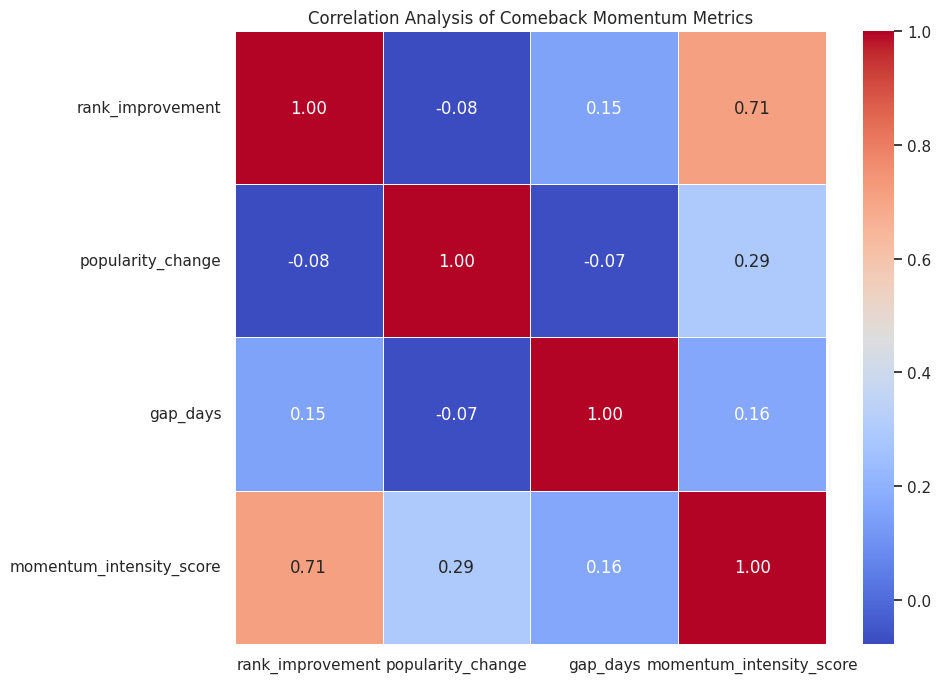

Statistical analysis completed.


In [71]:
# ============================================================
# SECTION 12.10 — STATISTICAL ANALYSIS
# ============================================================

print("=" * 70)
print("STATISTICAL ANALYSIS")
print("=" * 70)

# Momentum statistics

momentum_statistics = (
    momentum_events["momentum_intensity_score"]
    .describe()
    .to_frame(name="Momentum Score")
)

display(momentum_statistics)

# Rank improvement statistics

rank_statistics = (
    momentum_events["rank_improvement"]
    .describe()
    .to_frame(name="Rank Improvement")
)

display(rank_statistics)

# Popularity change statistics

popularity_statistics = (
    momentum_events["popularity_change"]
    .describe()
    .to_frame(name="Popularity Change")
)

display(popularity_statistics)

# Correlation analysis

correlation_columns = [
    "rank_improvement",
    "popularity_change",
    "gap_days",
    "momentum_intensity_score"
]

correlation_matrix = momentum_events[
    correlation_columns
].corr(method="pearson")

print("\nCorrelation Matrix:")
display(correlation_matrix)

# Correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Analysis of Comeback Momentum Metrics")
plt.tight_layout()
plt.show()

# Export

momentum_statistics.to_csv(
    "South_Korea_Momentum_Statistics.csv"
)

correlation_matrix.to_csv(
    "South_Korea_Momentum_Correlation.csv"
)

print("Statistical analysis completed.")

TOP ARTISTS BY RE-ENTRY PERFORMANCE


,artist,total_reentry_events,unique_songs,average_momentum_score,maximum_momentum_score,average_rank_improvement,average_popularity_change,average_gap_days
60,Lim Young Woong,159,22,2.407545,23.788998,0.106918,-0.081761,7.867925
41,Jimin,120,15,4.673816,36.288998,-0.100000,-0.033333,5.466667
71,NewJeans,113,9,3.063560,19.642857,0.398230,-0.353982,11.292035
44,Jung Kook,63,11,1.501290,16.071429,-1.476190,-0.746032,8.301587
20,DAY6,35,8,3.343889,23.788998,-0.085714,-0.085714,19.657143
56,LE SSERAFIM,20,5,3.654557,20.217570,0.150000,0.100000,8.000000
78,RIIZE,20,6,4.241585,41.646141,-0.100000,0.300000,8.150000
95,V,20,8,2.375821,10.714286,-0.900000,-0.800000,11.050000
16,Charlie Puth,16,3,3.157071,11.288998,-0.687500,-0.375000,19.937500
91,Taylor Swift,15,2,1.977285,8.928571,-1.266667,-0.600000,14.000000


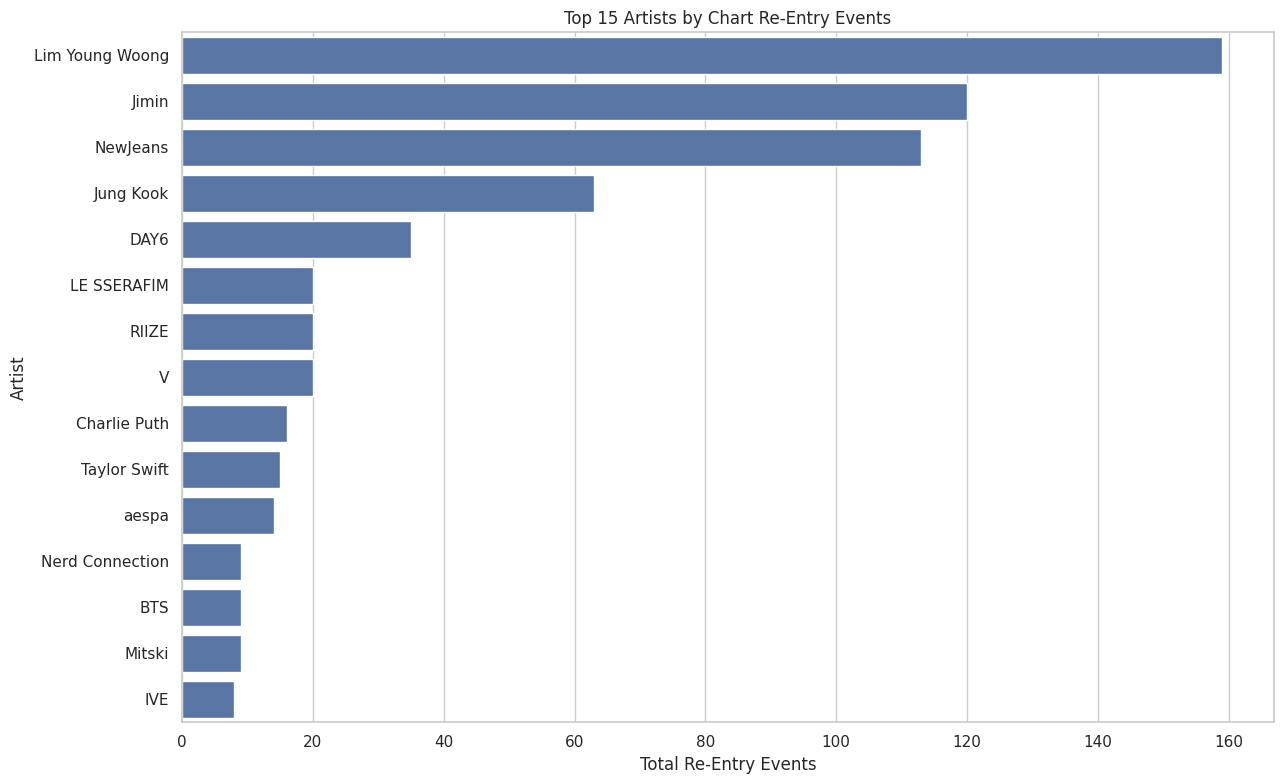

Artist performance analysis completed.


In [72]:
# ============================================================
# SECTION 12.11 — ARTIST-LEVEL PERFORMANCE ANALYSIS
# ============================================================

artist_performance = (
    momentum_events
    .groupby("artist")
    .agg(
        total_reentry_events=("song_artist_id", "count"),
        unique_songs=("song_artist_id", "nunique"),
        average_momentum_score=(
            "momentum_intensity_score", "mean"
        ),
        maximum_momentum_score=(
            "momentum_intensity_score", "max"
        ),
        average_rank_improvement=(
            "rank_improvement", "mean"
        ),
        average_popularity_change=(
            "popularity_change", "mean"
        ),
        average_gap_days=("gap_days", "mean")
    )
    .reset_index()
)

artist_performance = artist_performance.sort_values(
    "total_reentry_events",
    ascending=False
)

print("TOP ARTISTS BY RE-ENTRY PERFORMANCE")

display(artist_performance.head(20))

# Artist re-entry leaderboard

plt.figure(figsize=(13, 8))

top_artists = artist_performance.head(15)

sns.barplot(
    data=top_artists,
    x="total_reentry_events",
    y="artist"
)

plt.title("Top 15 Artists by Chart Re-Entry Events")
plt.xlabel("Total Re-Entry Events")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

# Export

artist_performance.to_csv(
    "South_Korea_Artist_Performance_Analysis.csv",
    index=False
)

print("Artist performance analysis completed.")

ALBUM VS SINGLE COMEBACK PERFORMANCE


,album_type,unique_songs,total_comeback_events,average_momentum_score,median_momentum_score
0,album,77,365,3.609027,1.785714
1,single,153,509,4.796853,2.319376


Album minus Single Momentum Difference: -1.188
Singles show higher average comeback momentum.


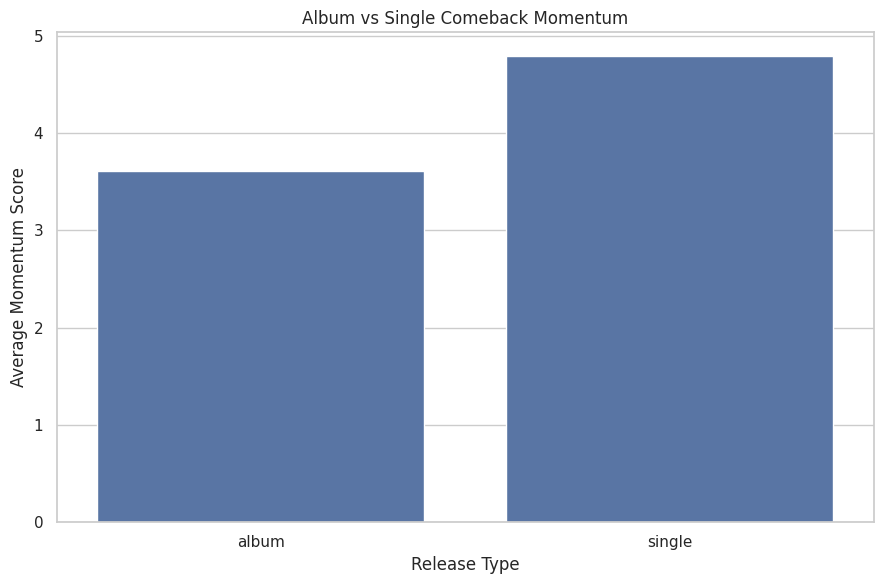

Album comeback advantage analysis completed.


In [73]:
# ============================================================
# SECTION 12.12 — ALBUM COMEBACK ADVANTAGE INDEX
# ============================================================

album_metadata = (
    chart_df[
        [
            "song_artist_id",
            "song",
            "artist",
            "album_type",
            "total_tracks"
        ]
    ]
    .drop_duplicates("song_artist_id")
    .copy()
)

album_metadata["album_type"] = (
    album_metadata["album_type"]
    .astype(str)
    .str.lower()
    .str.strip()
)

album_metadata["total_tracks"] = pd.to_numeric(
    album_metadata["total_tracks"],
    errors="coerce"
)

momentum_by_song = (
    momentum_events
    .groupby("song_artist_id")
    .agg(
        average_momentum_score=(
            "momentum_intensity_score", "mean"
        ),
        total_comeback_events=(
            "reentry_date", "count"
        )
    )
    .reset_index()
)

album_momentum = album_metadata.merge(
    momentum_by_song,
    on="song_artist_id",
    how="inner"
)

album_advantage = (
    album_momentum
    .groupby("album_type")
    .agg(
        unique_songs=("song_artist_id", "nunique"),
        total_comeback_events=("total_comeback_events", "sum"),
        average_momentum_score=(
            "average_momentum_score", "mean"
        ),
        median_momentum_score=(
            "average_momentum_score", "median"
        )
    )
    .reset_index()
)

print("ALBUM VS SINGLE COMEBACK PERFORMANCE")

display(album_advantage)

# Calculate difference

album_score = album_advantage.loc[
    album_advantage["album_type"] == "album",
    "average_momentum_score"
]

single_score = album_advantage.loc[
    album_advantage["album_type"] == "single",
    "average_momentum_score"
]

if not album_score.empty and not single_score.empty:

    advantage_difference = (
        album_score.iloc[0] - single_score.iloc[0]
    )

    print(
        "Album minus Single Momentum Difference:",
        round(advantage_difference, 3)
    )

    if advantage_difference > 0:
        print("Albums show higher average comeback momentum.")

    elif advantage_difference < 0:
        print("Singles show higher average comeback momentum.")

    else:
        print("Both categories have equal average momentum.")

# Visualization

plt.figure(figsize=(9, 6))

sns.barplot(
    data=album_advantage,
    x="album_type",
    y="average_momentum_score"
)

plt.title("Album vs Single Comeback Momentum")
plt.xlabel("Release Type")
plt.ylabel("Average Momentum Score")
plt.tight_layout()
plt.show()

# Export

album_advantage.to_csv(
    "South_Korea_Album_Comeback_Advantage_Index.csv",
    index=False
)

album_momentum.to_csv(
    "South_Korea_Album_Momentum_Details.csv",
    index=False
)

print("Album comeback advantage analysis completed.")

## **13. Advanced Data Visualization**

In [74]:
# ============================================================
# 13.1 CHART RE-ENTRY TIMELINE
# ============================================================

if not reentry_df.empty:

    timeline_df = reentry_df.copy()

    timeline_df["reentry_date"] = pd.to_datetime(
        timeline_df["reentry_date"],
        errors="coerce"
    )

    # Select the 20 songs with the most re-entries
    top_song_ids = (
        timeline_df["song_artist_id"]
        .value_counts()
        .head(20)
        .index
    )

    timeline_df = timeline_df[
        timeline_df["song_artist_id"].isin(top_song_ids)
    ].copy()

    timeline_df["song_label"] = (
        timeline_df["song"].fillna("Unknown Song")
        + " — "
        + timeline_df["artist"].fillna("Unknown Artist")
    )

    fig = px.scatter(
        timeline_df,
        x="reentry_date",
        y="song_label",
        color="song",
        hover_data=[
            "artist",
            "previous_chart_date",
            "days_between_appearances"
        ],
        title="Chart Re-Entry Timeline",
        labels={
            "reentry_date": "Re-Entry Date",
            "song_label": "Song",
            "song": "Song Title"
        }
    )

    fig.update_layout(
        height=700,
        showlegend=False
    )

    fig.show()

else:
    print("No chart re-entry events are available.")

In [75]:
# ============================================================
# 13.2 POPULARITY MOMENTUM OVER TIME
# ============================================================

if "popularity" in chart_df.columns:

    popularity_df = chart_df.copy()

    popularity_df["popularity"] = pd.to_numeric(
        popularity_df["popularity"],
        errors="coerce"
    )

    # Select songs with the most chart appearances
    top_song_ids = (
        popularity_df["song_artist_id"]
        .value_counts()
        .head(10)
        .index
    )

    popularity_df = popularity_df[
        popularity_df["song_artist_id"].isin(top_song_ids)
    ].copy()

    fig = px.line(
        popularity_df.sort_values("date"),
        x="date",
        y="popularity",
        color="song_artist_id",
        hover_data=["song", "artist", "position"],
        title="Popularity Trends of Frequently Appearing Songs",
        labels={
            "date": "Date",
            "popularity": "Popularity Score",
            "song_artist_id": "Song Identifier"
        }
    )

    fig.update_layout(height=600)
    fig.show()

else:
    print("Popularity data is unavailable.")

In [76]:
# ============================================================
# 13.3 CHART RANK TRENDS
# ============================================================

if "position" in chart_df.columns:

    rank_plot_df = chart_df.copy()

    rank_plot_df["position"] = pd.to_numeric(
        rank_plot_df["position"],
        errors="coerce"
    )

    # Select the 10 songs with the most chart appearances
    top_song_ids = (
        rank_plot_df["song_artist_id"]
        .value_counts()
        .head(10)
        .index
    )

    rank_plot_df = rank_plot_df[
        rank_plot_df["song_artist_id"].isin(top_song_ids)
    ].copy()

    fig = px.line(
        rank_plot_df.sort_values("date"),
        x="date",
        y="position",
        color="song_artist_id",
        hover_data=["song", "artist"],
        title="Chart Position Trends",
        labels={
            "date": "Date",
            "position": "Chart Position",
            "song_artist_id": "Song Identifier"
        }
    )

    fig.update_yaxes(
        autorange="reversed",
        dtick=5
    )

    fig.update_layout(height=600)
    fig.show()

else:
    print("Chart position data is unavailable.")

In [77]:
# ============================================================
# 13.4 MOMENTUM INTENSITY COMPARISON
# ============================================================

if (
    "momentum_kpi" in globals()
    and not momentum_kpi.empty
):

    momentum_plot_df = (
        momentum_kpi
        .sort_values(
            "average_momentum_spike_score",
            ascending=False
        )
        .head(15)
        .copy()
    )

    momentum_plot_df["song_label"] = (
        momentum_plot_df["song"].fillna("Unknown Song")
        + " — "
        + momentum_plot_df["artist"].fillna("Unknown Artist")
    )

    fig = px.bar(
        momentum_plot_df.sort_values(
            "average_momentum_spike_score"
        ),
        x="average_momentum_spike_score",
        y="song_label",
        orientation="h",
        title="Top Songs by Average Momentum Spike Score",
        labels={
            "average_momentum_spike_score": "Average Momentum Score",
            "song_label": "Song"
        }
    )

    fig.update_layout(height=650)
    fig.show()

else:
    print("Momentum KPI data is unavailable.")

In [78]:
# ============================================================
# 13.5 POST-COMEBACK RETENTION COMPARISON
# ============================================================

if not retention_df.empty:

    retention_plot_df = retention_df.copy()

    retention_plot_df["song_label"] = (
        retention_plot_df["song"].fillna("Unknown Song")
        + " — "
        + retention_plot_df["artist"].fillna("Unknown Artist")
    )

    retention_plot_df = (
        retention_plot_df
        .sort_values("retention_calendar_days", ascending=False)
        .head(15)
        .sort_values("retention_calendar_days")
    )

    fig = px.bar(
        retention_plot_df,
        x="retention_calendar_days",
        y="song_label",
        orientation="h",
        color="right_censored",
        title="Post-Comeback Retention by Song",
        labels={
            "retention_calendar_days": "Retention (Calendar Days)",
            "song_label": "Song",
            "right_censored": "Run Reaches Dataset End"
        }
    )

    fig.update_layout(height=650)
    fig.show()

else:
    print("Retention data is unavailable.")

In [79]:
# ============================================================
# 13.6 FANDOM INTENSITY LEADERBOARD
# ============================================================

if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):

    fandom_plot_df = (
        fandom_leaderboard
        .dropna(subset=["fandom_intensity_proxy_score"])
        .sort_values(
            "fandom_intensity_proxy_score",
            ascending=False
        )
        .head(15)
        .copy()
    )

    fandom_plot_df["song_label"] = (
        fandom_plot_df["song"].fillna("Unknown Song")
        + " — "
        + fandom_plot_df["artist"].fillna("Unknown Artist")
    )

    fig = px.bar(
        fandom_plot_df.sort_values(
            "fandom_intensity_proxy_score"
        ),
        x="fandom_intensity_proxy_score",
        y="song_label",
        orientation="h",
        title="Fandom Intensity Proxy Leaderboard",
        labels={
            "fandom_intensity_proxy_score": "Fandom Intensity Proxy Score",
            "song_label": "Song"
        },
        hover_data=[
            "reentry_frequency",
            "average_spike_sharpness",
            "average_rank_recovery_speed"
        ]
    )

    fig.update_layout(height=650)
    fig.show()

else:
    print("Fandom intensity data is unavailable.")

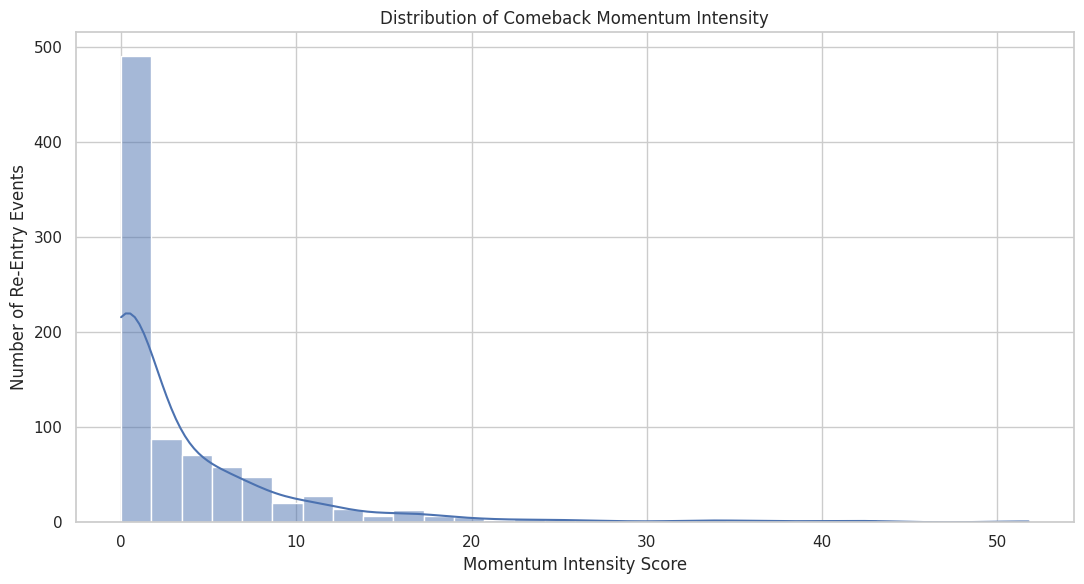

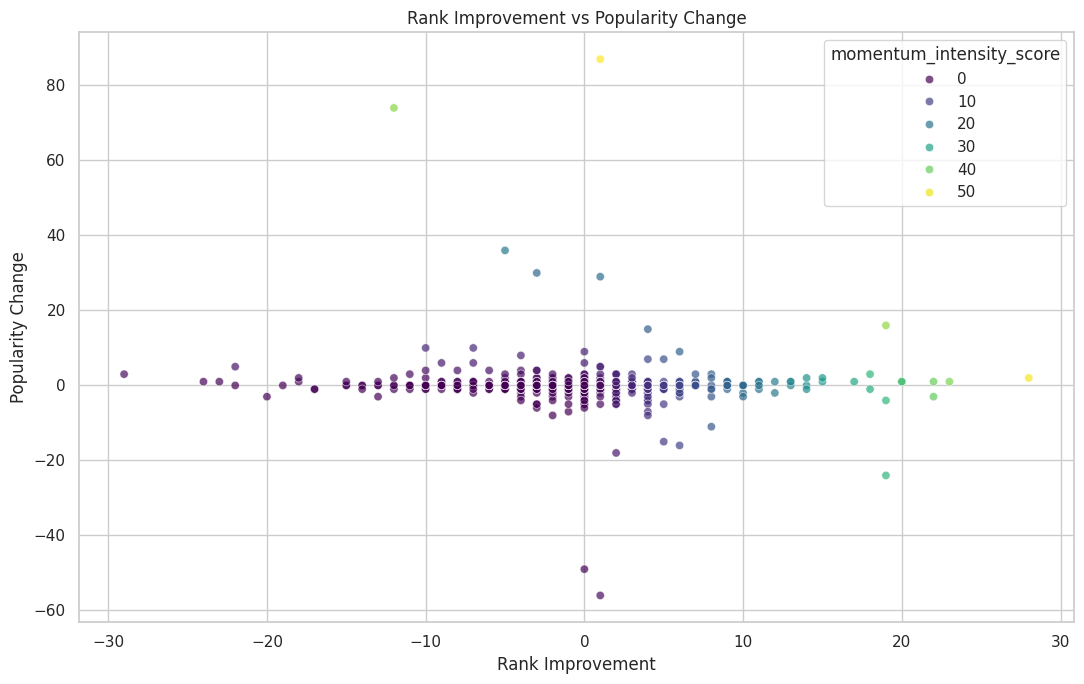

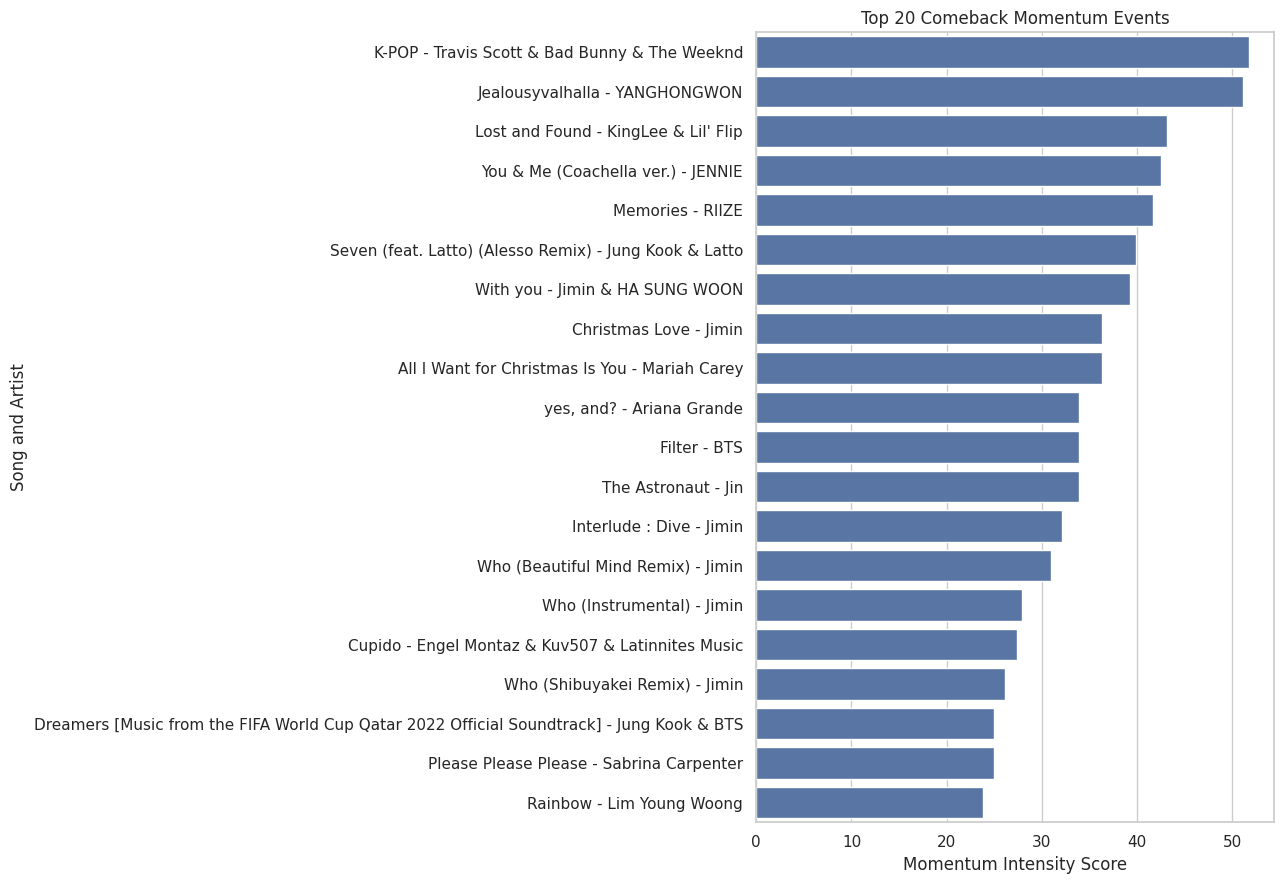

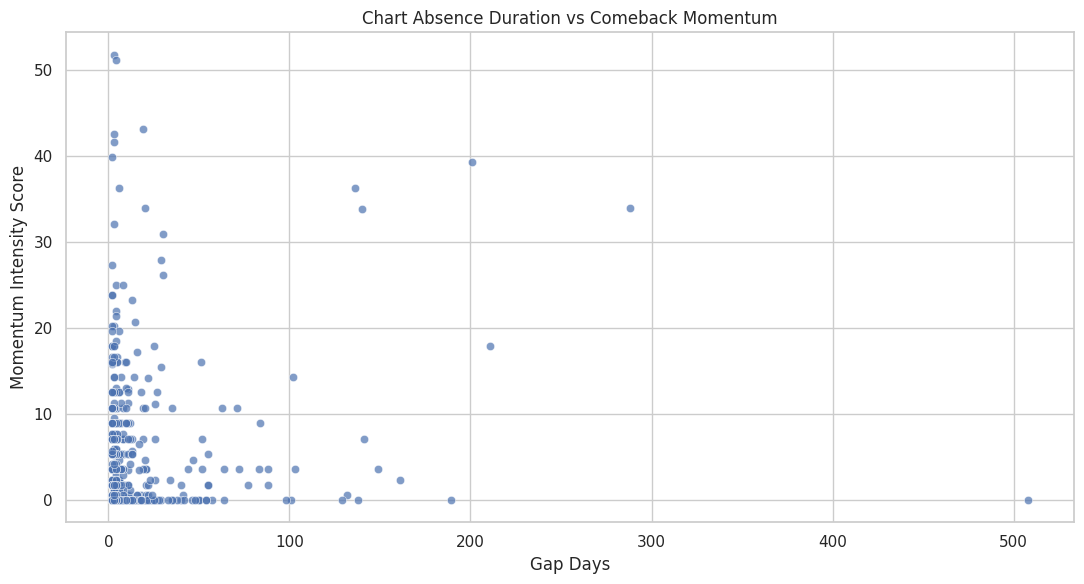

Advanced momentum visualizations completed.


In [80]:
# ============================================================
# SECTION 13.7 — ADVANCED MOMENTUM VISUALIZATIONS
# ============================================================

# 1. Momentum Score Distribution

plt.figure(figsize=(11, 6))

sns.histplot(
    data=momentum_events,
    x="momentum_intensity_score",
    bins=30,
    kde=True
)

plt.title("Distribution of Comeback Momentum Intensity")
plt.xlabel("Momentum Intensity Score")
plt.ylabel("Number of Re-Entry Events")
plt.tight_layout()
plt.show()


# 2. Rank Improvement vs Popularity Change

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=momentum_events,
    x="rank_improvement",
    y="popularity_change",
    hue="momentum_intensity_score",
    palette="viridis",
    alpha=0.7
)

plt.title("Rank Improvement vs Popularity Change")
plt.xlabel("Rank Improvement")
plt.ylabel("Popularity Change")
plt.tight_layout()
plt.show()


# 3. Top 20 Comeback Momentum Events

top_momentum = momentum_events.nlargest(
    20,
    "momentum_intensity_score"
).copy()

top_momentum["song_label"] = (
    top_momentum["song"].astype(str)
    + " - "
    + top_momentum["artist"].astype(str)
)

plt.figure(figsize=(13, 9))

sns.barplot(
    data=top_momentum,
    x="momentum_intensity_score",
    y="song_label"
)

plt.title("Top 20 Comeback Momentum Events")
plt.xlabel("Momentum Intensity Score")
plt.ylabel("Song and Artist")
plt.tight_layout()
plt.show()


# 4. Gap Days vs Momentum Score
# This is a diagnostic chart, not a momentum formula.

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=momentum_events,
    x="gap_days",
    y="momentum_intensity_score",
    alpha=0.7
)

plt.title("Chart Absence Duration vs Comeback Momentum")
plt.xlabel("Gap Days")
plt.ylabel("Momentum Intensity Score")
plt.tight_layout()
plt.show()

print("Advanced momentum visualizations completed.")

In [81]:
# ============================================================
# 13.8 - EXPORT VISUALIZATION DATA
# ============================================================

visualization_exports = {
    "South_Korea_Reentry_Timeline_Data.csv": reentry_df,
    "South_Korea_Retention_Visualization_Data.csv": retention_df,
    "South_Korea_Fandom_Leaderboard_Data.csv": fandom_leaderboard
}

for filename, data in visualization_exports.items():

    if isinstance(data, pd.DataFrame) and not data.empty:

        data.to_csv(filename, index=False)

        print("Exported:", filename)

print("Visualization data export completed!")

Exported: South_Korea_Reentry_Timeline_Data.csv
Exported: South_Korea_Retention_Visualization_Data.csv
Exported: South_Korea_Fandom_Leaderboard_Data.csv
Visualization data export completed!


## **14. Final Insights and Findings**

In [82]:
# ============================================================
# 14.1 OVERALL DATASET INSIGHTS
# ============================================================

print("=" * 70)
print("SOUTH KOREA TOP 50 PLAYLIST — DATASET INSIGHTS")
print("=" * 70)

print("\n1. DATASET OVERVIEW")

print("Total chart records:", len(chart_df))
print("Unique songs:", chart_df["song_artist_id"].nunique())
print("Unique artists:", chart_df["artist"].nunique())
print("Chart start date:", chart_df["date"].min())
print("Chart end date:", chart_df["date"].max())
print("Observed chart dates:", chart_df["date"].nunique())

print("\n2. CHART RE-ENTRY OVERVIEW")

if not reentry_df.empty:
    print("Detected re-entry events:", len(reentry_df))
    print(
        "Songs with detected re-entries:",
        reentry_df["song_artist_id"].nunique()
    )
else:
    print("No re-entry events were detected.")

print("\n3. MOMENTUM OVERVIEW")

if (
    "momentum_kpi" in globals()
    and not momentum_kpi.empty
):
    print(
        "Songs with momentum scores:",
        momentum_kpi["song_artist_id"].nunique()
    )

    print(
        "Average momentum score:",
        round(
            momentum_kpi["average_momentum_spike_score"].mean(),
            2
        )
    )
else:
    print("Momentum KPI results are unavailable.")

print("\n4. RETENTION OVERVIEW")

if not retention_df.empty:
    print(
        "Average post-comeback retention:",
        round(
            retention_df["retention_calendar_days"].mean(),
            2
        ),
        "calendar days"
    )
else:
    print("Retention results are unavailable.")

print("\n5. FANDOM INTENSITY OVERVIEW")

if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):
    print(
        "Songs in fandom leaderboard:",
        len(fandom_leaderboard)
    )

    print(
        "Average fandom intensity proxy score:",
        round(
            fandom_leaderboard[
                "fandom_intensity_proxy_score"
            ].mean(),
            2
        )
    )
else:
    print("Fandom intensity results are unavailable.")

SOUTH KOREA TOP 50 PLAYLIST — DATASET INSIGHTS

1. DATASET OVERVIEW
Total chart records: 27700
Unique songs: 537
Unique artists: 194
Chart start date: 2024-05-18 00:00:00
Chart end date: 2025-11-27 00:00:00
Observed chart dates: 554

2. CHART RE-ENTRY OVERVIEW
Detected re-entry events: 874
Songs with detected re-entries: 230

3. MOMENTUM OVERVIEW
Songs with momentum scores: 230
Average momentum score: 4.4

4. RETENTION OVERVIEW
Average post-comeback retention: 8.86 calendar days

5. FANDOM INTENSITY OVERVIEW
Songs in fandom leaderboard: 230
Average fandom intensity proxy score: 7.1


In [83]:
# ============================================================
# 14.2 SONGS WITH THE MOST CHART RE-ENTRIES
# ============================================================

if (
    "reentry_frequency_kpi" in globals()
    and not reentry_frequency_kpi.empty
):

    top_reentry_songs = (
        reentry_frequency_kpi
        .sort_values(
            "reentry_frequency",
            ascending=False
        )
        .head(10)
        .copy()
    )

    print("Top 10 Songs by Re-Entry Frequency")

    display(
        top_reentry_songs[
            [
                "song",
                "artist",
                "reentry_frequency"
            ]
        ]
    )

    highest_count = top_reentry_songs[
        "reentry_frequency"
    ].max()

    print(
        "\nHighest observed re-entry count:",
        highest_count
    )

else:
    print("Re-entry frequency results are unavailable.")

Top 10 Songs by Re-Entry Frequency


,song,artist,reentry_frequency
143,"Our Blues, Our Life",Lim Young Woong,28
47,Ditto,NewJeans,26
2,A bientot,Lim Young Woong,22
137,New Jeans,NewJeans,20
82,Hype Boy,NewJeans,19
91,Interlude : Dive,Jimin,19
55,ETA,NewJeans,16
153,Rainbow,Lim Young Woong,16
167,Somebody,Jung Kook,15
142,OMG,NewJeans,14



Highest observed re-entry count: 28


In [84]:
# ============================================================
# 14.3 STRONGEST MOMENTUM PERFORMERS
# ============================================================

if (
    "momentum_kpi" in globals()
    and not momentum_kpi.empty
):

    top_momentum_songs = (
        momentum_kpi
        .dropna(
            subset=["average_momentum_spike_score"]
        )
        .sort_values(
            "average_momentum_spike_score",
            ascending=False
        )
        .head(10)
    )

    print("Top 10 Songs by Average Momentum Score")

    display(
        top_momentum_songs[
            [
                "song",
                "artist",
                "average_momentum_spike_score",
                "maximum_momentum_spike_score"
            ]
        ]
    )

else:
    print("Momentum results are unavailable.")

Top 10 Songs by Average Momentum Score


,song,artist,average_momentum_spike_score,maximum_momentum_spike_score
95,K-POP,Travis Scott & Bad Bunny & The Weeknd,51.785714,51.785714
94,Jealousyvalhalla,YANGHONGWON,51.149425,51.149425
110,Lost and Found,KingLee & Lil' Flip,43.123974,43.123974
221,You & Me (Coachella ver.),JENNIE,42.528736,42.528736
4,All I Want for Christmas Is You,Mariah Carey,36.288998,36.288998
194,The Astronaut,Jin,33.866995,33.866995
42,Cupido,Engel Montaz & Kuv507 & Latinnites Music,27.360427,27.360427
155,Seven (feat. Latto) (Alesso Remix),Jung Kook & Latto,20.792282,39.860427
11,Armageddon,aespa & Grimes & Flava D,20.689655,20.689655
220,"yes, and?",Ariana Grande,19.642857,33.928571


In [85]:
# ============================================================
# 14.4 LONGEST POST-COMEBACK RETENTION
# ============================================================

if not retention_df.empty:

    longest_retention = (
        retention_df
        .sort_values(
            "retention_calendar_days",
            ascending=False
        )
        .head(10)
    )

    print("Top 10 Comeback Events by Retention")

    display(
        longest_retention[
            [
                "song",
                "artist",
                "reentry_date",
                "last_chart_date",
                "retention_calendar_days",
                "right_censored"
            ]
        ]
    )

else:
    print("Retention results are unavailable.")

Top 10 Comeback Events by Retention


,song,artist,reentry_date,last_chart_date,retention_calendar_days,right_censored
338,If We Ever Meet Again,Lim Young Woong,2024-07-30,2025-05-26,300,False
695,Standing Next to You,Jung Kook,2025-03-03,2025-11-27,269,True
633,Rainbow,Lim Young Woong,2024-09-10,2025-05-22,254,False
662,Slow Dancing,V,2024-09-17,2025-04-30,225,False
567,"Our Blues, Our Life",Lim Young Woong,2024-10-13,2025-04-22,191,False
68,BIRDS OF A FEATHER,Billie Eilish,2025-05-28,2025-11-24,180,False
17,A bientot,Lim Young Woong,2024-10-13,2025-04-03,172,False
588,People Pt.2 (feat. IU),Agust D,2024-07-02,2024-11-04,125,False
339,If We Ever Meet Again,Lim Young Woong,2025-05-29,2025-09-29,123,False
130,Cruel Summer,Taylor Swift,2024-12-28,2025-04-24,117,False


In [86]:
# ============================================================
# 14.5 HIGHEST FANDOM INTENSITY PROXY SCORES
# ============================================================

if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):

    top_fandom_songs = (
        fandom_leaderboard
        .dropna(
            subset=["fandom_intensity_proxy_score"]
        )
        .sort_values(
            "fandom_intensity_proxy_score",
            ascending=False
        )
        .head(10)
    )

    print("Top 10 Songs by Fandom Intensity Proxy Score")

    display(
        top_fandom_songs[
            [
                "song",
                "artist",
                "reentry_frequency",
                "average_spike_sharpness",
                "average_rank_recovery_speed",
                "fandom_intensity_proxy_score"
            ]
        ]
    )

else:
    print("Fandom intensity results are unavailable.")

Top 10 Songs by Fandom Intensity Proxy Score


,song,artist,reentry_frequency,average_spike_sharpness,average_rank_recovery_speed,fandom_intensity_proxy_score
0,"Our Blues, Our Life",Lim Young Woong,28,0.069643,0.783695,35.214980
1,K-POP,Travis Scott & Bad Bunny & The Weeknd,1,29.000000,0.000000,33.333333
2,Last Christmas - Single Version,Wham!,1,0.000000,14.500000,33.333333
3,Ditto,NewJeans,26,0.011095,0.626068,32.316188
4,Take Two,BTS,1,0.000000,14.000000,32.183908
5,3D (feat. Jack Harlow) (Instrumental),Jung Kook & Jack Harlow,1,1.250000,12.000000,29.022989
6,A bientot,Lim Young Woong,22,0.014399,1.321023,28.979310
7,You & Me (Coachella ver.),JENNIE,1,24.666667,0.000000,28.352490
8,Interlude : Dive,Jimin,19,0.065414,2.426686,27.875999
9,New Jeans,NewJeans,20,0.041667,0.309070,24.215190


In [87]:
# ============================================================
# 14.6 AUTOMATED FINDINGS SUMMARY
# ============================================================

findings = []

# Dataset overview
findings.append(
    f"The dataset contains {len(chart_df):,} chart records "
    f"covering {chart_df['date'].nunique():,} observed chart dates."
)

findings.append(
    f"The analysis includes "
    f"{chart_df['song_artist_id'].nunique():,} unique song identifiers."
)

# Re-entry findings
if not reentry_df.empty:

    findings.append(
        f"The current detection method identified "
        f"{len(reentry_df):,} potential re-entry events across "
        f"{reentry_df['song_artist_id'].nunique():,} songs."
    )

    findings.append(
        "These events should be interpreted only after confirming "
        "that chart-date coverage and exit detection are valid."
    )

else:
    findings.append(
        "No potential re-entry events were identified by the current method."
    )

# Momentum findings
if (
    "momentum_kpi" in globals()
    and not momentum_kpi.empty
):

    valid_momentum = momentum_kpi[
        "average_momentum_spike_score"
    ].dropna()

    if not valid_momentum.empty:

        findings.append(
            f"The average song-level momentum score is "
            f"{valid_momentum.mean():.2f}."
        )

        best_song = momentum_kpi.loc[
            momentum_kpi[
                "average_momentum_spike_score"
            ].idxmax()
        ]

        findings.append(
            f"The highest average momentum score belongs to "
            f"'{best_song['song']}' by '{best_song['artist']}'."
        )

# Retention findings
if not retention_df.empty:

    findings.append(
        f"The mean observed post-comeback retention is "
        f"{retention_df['retention_calendar_days'].mean():.2f} "
        f"calendar days."
    )

# Fandom proxy findings
if (
    "fandom_leaderboard" in globals()
    and not fandom_leaderboard.empty
):

    valid_fandom = fandom_leaderboard.dropna(
        subset=["fandom_intensity_proxy_score"]
    )

    if not valid_fandom.empty:

        top_song = valid_fandom.iloc[0]

        findings.append(
            f"The highest fandom intensity proxy score belongs to "
            f"'{top_song['song']}' by '{top_song['artist']}'."
        )

# Print findings
print("=" * 70)
print("AUTOMATED PROJECT FINDINGS")
print("=" * 70)

for number, finding in enumerate(findings, start=1):
    print(f"{number}. {finding}")

# Save findings
with open(
    "South_Korea_Project_Findings.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write("SOUTH KOREA TOP 50 PLAYLIST — PROJECT FINDINGS\n\n")

    for number, finding in enumerate(findings, start=1):
        file.write(f"{number}. {finding}\n")

print("\nFindings saved to South_Korea_Project_Findings.txt")

AUTOMATED PROJECT FINDINGS
1. The dataset contains 27,700 chart records covering 554 observed chart dates.
2. The analysis includes 537 unique song identifiers.
3. The current detection method identified 874 potential re-entry events across 230 songs.
4. These events should be interpreted only after confirming that chart-date coverage and exit detection are valid.
5. The average song-level momentum score is 4.40.
6. The highest average momentum score belongs to 'K-POP' by 'Travis Scott & Bad Bunny & The Weeknd'.
7. The mean observed post-comeback retention is 8.86 calendar days.
8. The highest fandom intensity proxy score belongs to 'Our Blues, Our Life' by 'Lim Young Woong'.

Findings saved to South_Korea_Project_Findings.txt


In [88]:
# ============================================================
# 14.7 EXPORT FINAL ANALYSIS TABLES
# ============================================================

final_exports = {
    "South_Korea_KPI_Summary.csv": kpi_summary,
    "South_Korea_Reentry_Events.csv": reentry_df,
    "South_Korea_Retention_Analysis.csv": retention_df,
    "South_Korea_Fandom_Leaderboard.csv": fandom_leaderboard,
    "South_Korea_Momentum_KPI.csv": momentum_kpi
}

for filename, data in final_exports.items():

    if isinstance(data, pd.DataFrame) and not data.empty:

        data.to_csv(filename, index=False)

        print("Exported:", filename)

print("\nFinal analysis table export completed!")

Exported: South_Korea_KPI_Summary.csv
Exported: South_Korea_Reentry_Events.csv
Exported: South_Korea_Retention_Analysis.csv
Exported: South_Korea_Fandom_Leaderboard.csv
Exported: South_Korea_Momentum_KPI.csv

Final analysis table export completed!


## **15. Independent Validation**

In [89]:
# ============================================================
# 15.1 DATASET VALIDATION
# ============================================================

print("=" * 70)
print("INDEPENDENT DATASET VALIDATION")
print("=" * 70)

validation_results = []

# 1. Missing values
missing_count = chart_df.isnull().sum().sum()

validation_results.append({
    "Validation": "Missing Values",
    "Result": int(missing_count),
    "Status": "PASS" if missing_count == 0 else "CHECK"
})

# 2. Duplicate records
duplicate_count = chart_df.duplicated().sum()

validation_results.append({
    "Validation": "Duplicate Records",
    "Result": int(duplicate_count),
    "Status": "PASS" if duplicate_count == 0 else "CHECK"
})

# 3. Chart positions
invalid_positions = (
    (~chart_df["position"].between(1, 50)).sum()
)

validation_results.append({
    "Validation": "Invalid Chart Positions",
    "Result": int(invalid_positions),
    "Status": "PASS" if invalid_positions == 0 else "CHECK"
})

# 4. Date coverage
date_counts = chart_df.groupby("date").size()

invalid_chart_dates = (
    date_counts[date_counts != 50].shape[0]
)

validation_results.append({
    "Validation": "Dates Without Exactly 50 Records",
    "Result": int(invalid_chart_dates),
    "Status": "PASS" if invalid_chart_dates == 0 else "CHECK"
})

# 5. Unique positions per date
unique_position_counts = (
    chart_df.groupby("date")["position"].nunique()
)

invalid_unique_positions = (
    unique_position_counts[unique_position_counts != 50].shape[0]
)

validation_results.append({
    "Validation": "Dates Without 50 Unique Positions",
    "Result": int(invalid_unique_positions),
    "Status": "PASS" if invalid_unique_positions == 0 else "CHECK"
})

validation_report = pd.DataFrame(validation_results)

display(validation_report)

print("\nVALIDATION SUMMARY")

print("Total Chart Records:", len(chart_df))
print("Unique Songs:", chart_df["song_artist_id"].nunique())
print("Unique Artists:", chart_df["artist"].nunique())
print("Observed Dates:", chart_df["date"].nunique())

validation_report.to_csv(
    "South_Korea_Independent_Validation.csv",
    index=False
)

print("\nIndependent validation completed.")

INDEPENDENT DATASET VALIDATION


,Validation,Result,Status
0,Missing Values,0,PASS
1,Duplicate Records,0,PASS
2,Invalid Chart Positions,0,PASS
3,Dates Without Exactly 50 Records,0,PASS
4,Dates Without 50 Unique Positions,0,PASS



VALIDATION SUMMARY
Total Chart Records: 27700
Unique Songs: 537
Unique Artists: 194
Observed Dates: 554

Independent validation completed.


In [90]:
# ============================================================
# 15.2 — RE-ENTRY AND MOMENTUM VALIDATION
# ============================================================

print("=" * 70)
print("RE-ENTRY AND MOMENTUM VALIDATION")
print("=" * 70)

momentum_validation = []

# Standardize event dates
reentry_check = reentry_df.copy()
momentum_check = momentum_events.copy()

reentry_check["reentry_date"] = pd.to_datetime(
    reentry_check["reentry_date"]
)

momentum_check["reentry_date"] = pd.to_datetime(
    momentum_check["reentry_date"]
)

# Create event keys
reentry_keys = set(
    zip(
        reentry_check["song_artist_id"],
        reentry_check["reentry_date"]
    )
)

momentum_keys = set(
    zip(
        momentum_check["song_artist_id"],
        momentum_check["reentry_date"]
    )
)

# 1. Event count comparison
event_count_match = len(reentry_df) == len(momentum_events)

momentum_validation.append({
    "Check": "Re-entry and Momentum Event Count Match",
    "Value": event_count_match,
    "Status": "PASS" if event_count_match else "CHECK"
})

# 2. Event key consistency
matching_keys = reentry_keys == momentum_keys

momentum_validation.append({
    "Check": "Re-entry and Momentum Event Keys Match",
    "Value": matching_keys,
    "Status": "PASS" if matching_keys else "CHECK"
})

# 3. Missing momentum scores
missing_scores = momentum_check[
    "momentum_intensity_score"
].isna().sum()

momentum_validation.append({
    "Check": "Missing Momentum Scores",
    "Value": int(missing_scores),
    "Status": "PASS" if missing_scores == 0 else "CHECK"
})

# 4. Duplicate momentum event keys
duplicate_events = momentum_check.duplicated(
    subset=["song_artist_id", "reentry_date"]
).sum()

momentum_validation.append({
    "Check": "Duplicate Momentum Event Keys",
    "Value": int(duplicate_events),
    "Status": "PASS" if duplicate_events == 0 else "CHECK"
})

# 5. Non-finite momentum scores
finite_scores = np.isfinite(
    pd.to_numeric(
        momentum_check["momentum_intensity_score"],
        errors="coerce"
    )
)

non_finite_scores = int((~finite_scores).sum())

momentum_validation.append({
    "Check": "Non-Finite Momentum Scores",
    "Value": non_finite_scores,
    "Status": "PASS" if non_finite_scores == 0 else "CHECK"
})

# 6. Momentum scores outside the valid range
numeric_scores = pd.to_numeric(
    momentum_check["momentum_intensity_score"],
    errors="coerce"
)

invalid_scores = (
    (~numeric_scores.between(0, 100))
    & numeric_scores.notna()
).sum()

momentum_validation.append({
    "Check": "Scores Outside 0-100",
    "Value": int(invalid_scores),
    "Status": "PASS" if invalid_scores == 0 else "CHECK"
})

# Create validation report
momentum_validation_df = pd.DataFrame(
    momentum_validation
)

display(momentum_validation_df)

# Overall validation status
overall_status = (
    "PASS"
    if (momentum_validation_df["Status"] == "PASS").all()
    else "CHECK"
)

print("\nOVERALL MOMENTUM VALIDATION:", overall_status)

# Export validation report
momentum_validation_df.to_csv(
    "South_Korea_Momentum_Validation.csv",
    index=False
)

print("\nMomentum validation completed.")

RE-ENTRY AND MOMENTUM VALIDATION


,Check,Value,Status
0,Re-entry and Momentum Event Count Match,True,PASS
1,Re-entry and Momentum Event Keys Match,True,PASS
2,Missing Momentum Scores,0,PASS
3,Duplicate Momentum Event Keys,0,PASS
4,Non-Finite Momentum Scores,0,PASS
5,Scores Outside 0-100,0,PASS



OVERALL MOMENTUM VALIDATION: PASS

Momentum validation completed.


## **16. Statistical Significance Testing**

In [91]:
# ============================================================
# 16.1 ALBUM VS SINGLE MOMENTUM
# ============================================================

from scipy.stats import mannwhitneyu

print("=" * 70)
print("ALBUM VS SINGLE STATISTICAL TEST")
print("=" * 70)

album_data = album_momentum.loc[
    album_momentum["album_type"].str.lower() == "album",
    "average_momentum_score"
].dropna()

single_data = album_momentum.loc[
    album_momentum["album_type"].str.lower() == "single",
    "average_momentum_score"
].dropna()

if len(album_data) > 0 and len(single_data) > 0:

    statistic, p_value = mannwhitneyu(
        album_data,
        single_data,
        alternative="two-sided"
    )

    print("Album Sample Size:", len(album_data))
    print("Single Sample Size:", len(single_data))

    print("Album Mean Momentum:", round(album_data.mean(), 3))
    print("Single Mean Momentum:", round(single_data.mean(), 3))

    print("Mann-Whitney U Statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Result: Statistically significant difference.")
    else:
        print("Result: No statistically significant difference.")

else:
    print("Insufficient data for comparison.")

ALBUM VS SINGLE STATISTICAL TEST
Album Sample Size: 77
Single Sample Size: 153
Album Mean Momentum: 3.609
Single Mean Momentum: 4.797
Mann-Whitney U Statistic: 5659.0
P-value: 0.6254800123084752
Result: No statistically significant difference.


In [92]:
# ============================================================
# 16.2 — EXPLICIT VS CLEAN MOMENTUM
# ============================================================

from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np

print("=" * 70)
print("EXPLICIT VS CLEAN MOMENTUM ANALYSIS")
print("=" * 70)

# Prepare chart metadata
metadata = chart_df[
    ["song_artist_id", "date", "is_explicit"]
].copy()

events = momentum_events.copy()

# Standardize matching keys
metadata["song_artist_id"] = (
    metadata["song_artist_id"].astype("string")
)

events["song_artist_id"] = (
    events["song_artist_id"].astype("string")
)

# Standardize dates
metadata["date"] = pd.to_datetime(metadata["date"])
events["reentry_date"] = pd.to_datetime(events["reentry_date"])

# Normalize explicit values
metadata["is_explicit"] = (
    metadata["is_explicit"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Match each event with the latest available metadata
explicit_test_df = pd.merge_asof(
    events.sort_values("reentry_date"),
    metadata.sort_values("date"),
    left_on="reentry_date",
    right_on="date",
    by="song_artist_id",
    direction="backward",
    allow_exact_matches=True
)

# Separate clean and explicit events
clean_scores = explicit_test_df.loc[
    explicit_test_df["is_explicit"].isin(
        ["false", "0", "no", "clean", "not explicit"]
    ),
    "momentum_intensity_score"
].dropna()

explicit_scores = explicit_test_df.loc[
    explicit_test_df["is_explicit"].isin(
        ["true", "1", "yes", "explicit"]
    ),
    "momentum_intensity_score"
].dropna()

# Display results
print("\nTotal re-entry events:", len(events))
print("Matched events:", explicit_test_df["is_explicit"].notna().sum())
print("Unmatched events:", explicit_test_df["is_explicit"].isna().sum())

print("\nClean events:", len(clean_scores))
print("Explicit events:", len(explicit_scores))

print("\nClean Mean Momentum:", round(clean_scores.mean(), 3))
print("Explicit Mean Momentum:", round(explicit_scores.mean(), 3))

# Statistical test
if len(clean_scores) > 0 and len(explicit_scores) > 0:

    statistic, p_value = mannwhitneyu(
        clean_scores,
        explicit_scores,
        alternative="two-sided"
    )

    print("\nMann-Whitney U Statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Result: Statistically significant difference detected.")
    else:
        print("Result: No statistically significant difference detected.")

else:
    print("\nInsufficient observations for statistical testing.")

# Export event-level results
explicit_test_df.to_csv(
    "South_Korea_Explicit_Clean_Event_Analysis.csv",
    index=False
)

print("\nAnalysis completed.")

EXPLICIT VS CLEAN MOMENTUM ANALYSIS

Total re-entry events: 874
Matched events: 874
Unmatched events: 0

Clean events: 831
Explicit events: 43

Clean Mean Momentum: 3.378
Explicit Mean Momentum: 7.779

Mann-Whitney U Statistic: 14547.5
P-value: 0.02945282344407048
Result: Statistically significant difference detected.

Analysis completed.


In [93]:
# ============================================================
# 16.2.1 — SONG-LEVEL STATISTICAL VALIDATION
# ============================================================

song_level_df = explicit_test_df.copy()

# Assign content categories without np.where()
song_level_df["content_category"] = "Unknown"

clean_mask = song_level_df["is_explicit"].isin(
    ["false", "0", "no", "clean", "not explicit"]
)

explicit_mask = song_level_df["is_explicit"].isin(
    ["true", "1", "yes", "explicit"]
)

song_level_df.loc[clean_mask, "content_category"] = "Clean"
song_level_df.loc[explicit_mask, "content_category"] = "Explicit"

# Check category consistency for each song
category_check = (
    song_level_df.groupby("song_artist_id")["content_category"]
    .nunique()
)

print(
    "Songs with inconsistent content categories:",
    (category_check > 1).sum()
)

# Aggregate momentum at song level
song_level_df = (
    song_level_df[
        song_level_df["content_category"].isin(["Clean", "Explicit"])
    ]
    .dropna(subset=["momentum_intensity_score"])
    .groupby(
        ["song_artist_id", "content_category"],
        as_index=False
    )
    .agg(
        average_momentum=("momentum_intensity_score", "mean"),
        reentry_events=("momentum_intensity_score", "count")
    )
)

# Separate song-level scores
clean_song_scores = song_level_df.loc[
    song_level_df["content_category"] == "Clean",
    "average_momentum"
]

explicit_song_scores = song_level_df.loc[
    song_level_df["content_category"] == "Explicit",
    "average_momentum"
]

print("\nSONG-LEVEL SAMPLE SIZES")
print("Clean songs:", len(clean_song_scores))
print("Explicit songs:", len(explicit_song_scores))

print("\nSONG-LEVEL MEAN MOMENTUM")
print("Clean:", round(clean_song_scores.mean(), 3))
print("Explicit:", round(explicit_song_scores.mean(), 3))

# Mann-Whitney U test
if len(clean_song_scores) > 0 and len(explicit_song_scores) > 0:

    statistic, p_value = mannwhitneyu(
        clean_song_scores,
        explicit_song_scores,
        alternative="two-sided"
    )

    print("\nSong-level Mann-Whitney U:", statistic)
    print("Song-level p-value:", p_value)

    if p_value < 0.05:
        print("Conclusion: Significant song-level difference detected.")
    else:
        print("Conclusion: No significant song-level difference detected.")

else:
    print("\nInsufficient song-level observations.")

Songs with inconsistent content categories: 0

SONG-LEVEL SAMPLE SIZES
Clean songs: 211
Explicit songs: 19

SONG-LEVEL MEAN MOMENTUM
Clean: 3.844
Explicit: 10.562

Song-level Mann-Whitney U: 1288.0
Song-level p-value: 0.00950121456986467
Conclusion: Significant song-level difference detected.


## **17. Machine Learning and Predictive Analytics**

In [94]:
# ============================================================
# 17.1 COMEBACK CLASSIFICATION DATASET
# ============================================================

print("=" * 70)
print("COMEBACK PREDICTION DATASET")
print("=" * 70)

chart_ml = chart_df.copy()

chart_ml["date"] = pd.to_datetime(chart_ml["date"])

chart_ml = chart_ml.sort_values(
    ["date", "song_artist_id"]
).reset_index(drop=True)

observed_dates = sorted(chart_ml["date"].unique())

chart_by_date = {
    date: group.copy()
    for date, group in chart_ml.groupby("date")
}

# Historical records by song
song_history = {}

classification_rows = []

for date_index, current_date in enumerate(observed_dates):

    if date_index + 7 >= len(observed_dates):
        break

    current_chart = chart_by_date[current_date]

    current_ids = set(
        current_chart["song_artist_id"]
    )

    # Songs appearing in the current chart
    for song_id in current_ids:

        row = current_chart[
            current_chart["song_artist_id"] == song_id
        ].iloc[0]

        song_history.setdefault(song_id, []).append(row)

    # Songs previously seen but currently absent
    absent_song_ids = (
        set(song_history.keys()) - current_ids
    )

    future_dates = observed_dates[
        date_index + 1:date_index + 8
    ]

    future_ids = set()

    for future_date in future_dates:

        future_ids.update(
            chart_by_date[future_date][
                "song_artist_id"
            ].tolist()
        )

    for song_id in absent_song_ids:

        history = song_history[song_id]

        previous = history[-1]

        last_seen_date = previous["date"]

        days_absent = (
            current_date - last_seen_date
        ).days

        historical_positions = [
            float(item["position"])
            for item in history
        ]

        historical_popularity = [
            float(item["popularity"])
            for item in history
        ]

        classification_rows.append({

            "prediction_date": current_date,

            "song_artist_id": song_id,

            "days_absent": days_absent,

            "previous_position": historical_positions[-1],

            "previous_popularity": historical_popularity[-1],

            "mean_previous_position": np.mean(
                historical_positions[-3:]
            ),

            "mean_previous_popularity": np.mean(
                historical_popularity[-3:]
            ),

            "previous_appearances": len(history),

            "position_std": (
                np.std(historical_positions[-5:])
                if len(historical_positions) > 1 else 0
            ),

            "popularity_std": (
                np.std(historical_popularity[-5:])
                if len(historical_popularity) > 1 else 0
            ),

            "duration_ms": previous["duration_ms"],

            "total_tracks": previous["total_tracks"],

            "album_type": previous["album_type"],

            "is_explicit": previous["is_explicit"],

            "comeback_within_7_dates": int(
                song_id in future_ids
            )
        })

classification_df = pd.DataFrame(
    classification_rows
)

print("Classification Dataset Shape:", classification_df.shape)

print("\nTarget Distribution:")

display(
    classification_df[
        "comeback_within_7_dates"
    ].value_counts().rename("Count").to_frame()
)

display(classification_df.head())

classification_df.to_csv(
    "South_Korea_Comeback_Classification_Dataset.csv",
    index=False
)

COMEBACK PREDICTION DATASET
Classification Dataset Shape: (137668, 15)

Target Distribution:


,Count
comeback_within_7_dates,
0,134949
1,2719


,prediction_date,song_artist_id,days_absent,previous_position,previous_popularity,mean_previous_position,mean_previous_popularity,previous_appearances,position_std,popularity_std,duration_ms,total_tracks,album_type,is_explicit,comeback_within_7_dates
0,2024-05-19,love always run away | lim young woong,1,50.0,58.0,50.0,58.0,1,0.0,0.0,242760,2,single,false,1
1,2024-05-19,salty & sweet | aespa,1,46.0,74.0,46.0,74.0,1,0.0,0.0,201760,6,single,false,0
2,2024-05-19,teddy bear | stayc,1,47.0,74.0,47.0,74.0,1,0.0,0.0,189773,2,single,false,1
3,2024-05-20,love always run away | lim young woong,2,50.0,58.0,50.0,58.0,1,0.0,0.0,242760,2,single,false,1
4,2024-05-20,teddy bear | stayc,2,47.0,74.0,47.0,74.0,1,0.0,0.0,189773,2,single,false,1


In [95]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [96]:
# ============================================================
# 17.2 — CLASSIFICATION MODEL TRAINING AND EVALUATION
# CHRONOLOGICAL DATE-BASED SPLIT
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. DEFINE FEATURES AND TARGET
# ------------------------------------------------------------

classification_features = [
    "days_absent",
    "previous_position",
    "previous_popularity",
    "mean_previous_position",
    "mean_previous_popularity",
    "previous_appearances",
    "position_std",
    "popularity_std",
    "duration_ms",
    "total_tracks",
    "album_type",
    "is_explicit"
]

target = "comeback_within_7_dates"

# Remove missing target values
classification_df = classification_df.dropna(
    subset=[target]
).copy()

# Standardize prediction dates
classification_df["prediction_date"] = pd.to_datetime(
    classification_df["prediction_date"]
)

# ------------------------------------------------------------
# 2. CHRONOLOGICAL DATE-BASED TRAIN/TEST SPLIT
# ------------------------------------------------------------

classification_df = classification_df.sort_values(
    "prediction_date"
).copy()

unique_prediction_dates = sorted(
    classification_df["prediction_date"].unique()
)

split_date_index = int(
    len(unique_prediction_dates) * 0.80
)

split_date = unique_prediction_dates[split_date_index]

train_data = classification_df[
    classification_df["prediction_date"] < split_date
].copy()

test_data = classification_df[
    classification_df["prediction_date"] >= split_date
].copy()

# ------------------------------------------------------------
# 3. DISPLAY SPLIT INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("CLASSIFICATION CHRONOLOGICAL TRAIN/TEST SPLIT")
print("=" * 70)

print("Total records:", len(classification_df))
print("Unique prediction dates:", len(unique_prediction_dates))

print("\nTraining records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining date range:")
print(
    train_data["prediction_date"].min(),
    "to",
    train_data["prediction_date"].max()
)

print("\nTesting date range:")
print(
    test_data["prediction_date"].min(),
    "to",
    test_data["prediction_date"].max()
)

print("\nSplit date:", split_date)

# Validate date separation
assert (
    train_data["prediction_date"].max()
    < test_data["prediction_date"].min()
)

print("\nDate separation validation: PASSED")

# ------------------------------------------------------------
# 4. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

X_train = train_data[classification_features]
y_train = train_data[target]

X_test = test_data[classification_features]
y_test = test_data[target]

print("\nTRAINING CLASS DISTRIBUTION")
print(y_train.value_counts())

print("\nTESTING CLASS DISTRIBUTION")
print(y_test.value_counts())

# ------------------------------------------------------------
# 5. DEFINE PREPROCESSING
# ------------------------------------------------------------

numeric_features = [
    "days_absent",
    "previous_position",
    "previous_popularity",
    "mean_previous_position",
    "mean_previous_popularity",
    "previous_appearances",
    "position_std",
    "popularity_std",
    "duration_ms",
    "total_tracks"
]

categorical_features = [
    "album_type",
    "is_explicit"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

# ------------------------------------------------------------
# 6. DEFINE CLASSIFICATION MODELS
# ------------------------------------------------------------

classification_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# ------------------------------------------------------------
# 7. TRAIN AND EVALUATE MODELS
# ------------------------------------------------------------

classification_results = []

trained_classification_models = {}

for model_name, model in classification_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    result = {

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "ROC AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        ),

        "PR AUC": (
            average_precision_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        )
    }

    classification_results.append(result)

    trained_classification_models[model_name] = pipeline

    print("\n" + "=" * 70)
    print(model_name)

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            y_test,
            predictions
        )
    )

    print("\nROC AUC:", result["ROC AUC"])
    print("PR AUC:", result["PR AUC"])

# ------------------------------------------------------------
# 8. FINAL MODEL COMPARISON
# ------------------------------------------------------------

classification_results_df = pd.DataFrame(
    classification_results
)

print("\nFINAL CLASSIFICATION MODEL COMPARISON")

display(classification_results_df)

# ------------------------------------------------------------
# 9. EXPORT RESULTS
# ------------------------------------------------------------

classification_results_df.to_csv(
    "South_Korea_Classification_Model_Results.csv",
    index=False
)

print("\nClassification model training and evaluation completed.")

CLASSIFICATION CHRONOLOGICAL TRAIN/TEST SPLIT
Total records: 137668
Unique prediction dates: 546

Training records: 89613
Testing records: 48055

Training date range:
2024-05-19 00:00:00 to 2025-08-01 00:00:00

Testing date range:
2025-08-02 00:00:00 to 2025-11-20 00:00:00

Split date: 2025-08-02 00:00:00

Date separation validation: PASSED

TRAINING CLASS DISTRIBUTION
comeback_within_7_dates
0    87497
1     2116
Name: count, dtype: int64

TESTING CLASS DISTRIBUTION
comeback_within_7_dates
0    47452
1      603
Name: count, dtype: int64

Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     47452
           1       0.10      0.86      0.18       603

    accuracy                           0.90     48055
   macro avg       0.55      0.88      0.56     48055
weighted avg       0.99      0.90      0.94     48055

Confusion Matrix:
[[42833  4619]
 [   84   519]]

ROC AUC: 0.9412021700483504
PR AUC

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.902133,0.101012,0.860697,0.180805,0.941202,0.212719
1,Random Forest,0.972386,0.261842,0.660033,0.374941,0.944395,0.343225



Classification model training and evaluation completed.


In [97]:
# ============================================================
# 17.3 NEXT-DAY CHART POSITION REGRESSION DATASET
# ============================================================

print("=" * 70)
print("NEXT-DAY CHART POSITION DATASET")
print("=" * 70)

regression_source = chart_df.copy()

regression_source["date"] = pd.to_datetime(
    regression_source["date"]
)

regression_source = regression_source.sort_values(
    ["song_artist_id", "date"]
).copy()

regression_source["next_position"] = (
    regression_source.groupby("song_artist_id")["position"]
    .shift(-1)
)

regression_source["next_date"] = (
    regression_source.groupby("song_artist_id")["date"]
    .shift(-1)
)

# Build the list of observed chart dates
observed_dates = sorted(
    regression_source["date"].unique()
)

next_observed_date = {
    observed_dates[i]: observed_dates[i + 1]
    for i in range(len(observed_dates) - 1)
}

regression_source["expected_next_date"] = (
    regression_source["date"].map(next_observed_date)
)

# Keep only consecutive observed chart appearances
regression_df = regression_source[
    regression_source["next_date"]
    == regression_source["expected_next_date"]
].copy()

regression_df = regression_df.dropna(
    subset=["next_position"]
)

regression_features = [
    "position",
    "popularity",
    "duration_ms",
    "total_tracks",
    "album_type",
    "is_explicit"
]

regression_target = "next_position"

print("Regression Dataset Shape:", regression_df.shape)

display(regression_df.head())

regression_df.to_csv(
    "South_Korea_Next_Day_Regression_Dataset.csv",
    index=False
)

NEXT-DAY CHART POSITION DATASET
Regression Dataset Shape: (26289, 14)


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,song_artist_id,next_position,next_date,expected_next_date
0,2025-09-01,26,1-800-hot-n-fun,LE SSERAFIM,64,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,28.0,2025-09-02,2025-09-02
1,2025-09-02,28,1-800-hot-n-fun,LE SSERAFIM,68,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,28.0,2025-09-03,2025-09-03
2,2025-09-03,28,1-800-hot-n-fun,LE SSERAFIM,70,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,32.0,2025-09-04,2025-09-04
3,2025-09-04,32,1-800-hot-n-fun,LE SSERAFIM,72,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,45.0,2025-09-05,2025-09-05
4,2025-09-05,45,1-800-hot-n-fun,LE SSERAFIM,73,173431,single,5,false,https://i.scdn.co/image/ab67616d0000b273485623...,1-800-hot-n-fun | le sserafim,45.0,2025-09-06,2025-09-06


In [98]:
# ============================================================
# 17.4 TRAIN NEXT-OBSERVED-DATE POSITION REGRESSION MODELS
# CHRONOLOGICAL DATE-BASED 80/20 SPLIT
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ensure date format
regression_df["date"] = pd.to_datetime(
    regression_df["date"]
)

# Sort chronologically
regression_df = regression_df.sort_values(
    "date"
).copy()

# Identify unique chart dates
unique_dates = sorted(
    regression_df["date"].unique()
)

# Calculate chronological 80/20 split
split_date_index = int(
    len(unique_dates) * 0.80
)

split_date = unique_dates[split_date_index]

# Create training and testing datasets
reg_train = regression_df[
    regression_df["date"] < split_date
].copy()

reg_test = regression_df[
    regression_df["date"] >= split_date
].copy()

# Display split information
print("=" * 70)
print("CHRONOLOGICAL REGRESSION TRAIN/TEST SPLIT")
print("=" * 70)

print("Total records:", len(regression_df))
print("Unique chart dates:", len(unique_dates))

print("\nTraining records:", len(reg_train))
print("Testing records:", len(reg_test))

print("\nTraining date range:")
print(reg_train["date"].min(), "to", reg_train["date"].max())

print("\nTesting date range:")
print(reg_test["date"].min(), "to", reg_test["date"].max())

print("\nSplit date:", split_date)

# Verify no date overlap
assert reg_train["date"].max() < reg_test["date"].min()

print("\nDate separation validation: PASSED")

# Prepare features and target
X_train_reg = reg_train[regression_features]
y_train_reg = reg_train[regression_target]

X_test_reg = reg_test[regression_features]
y_test_reg = reg_test[regression_target]

# Numeric features
reg_numeric_features = [
    "position",
    "popularity",
    "duration_ms",
    "total_tracks"
]

# Categorical features
reg_categorical_features = [
    "album_type",
    "is_explicit"
]

# Preprocessing pipeline
reg_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            reg_numeric_features
        ),
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            reg_categorical_features
        )
    ]
)

# Define regression models
regression_models = {

    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate models
regression_results = []

trained_regression_models = {}

for model_name, model in regression_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", reg_preprocessor),
        ("model", model)
    ])

    pipeline.fit(
        X_train_reg,
        y_train_reg
    )

    predictions = pipeline.predict(
        X_test_reg
    )

    result = {

        "Model": model_name,

        "MAE": mean_absolute_error(
            y_test_reg,
            predictions
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_reg,
                predictions
            )
        ),

        "R2 Score": r2_score(
            y_test_reg,
            predictions
        )
    }

    regression_results.append(result)

    trained_regression_models[model_name] = pipeline

    print("\n", model_name)
    print("MAE:", result["MAE"])
    print("RMSE:", result["RMSE"])
    print("R2 Score:", result["R2 Score"])

# Create results dataframe
regression_results_df = pd.DataFrame(
    regression_results
)

print("\nFINAL REGRESSION MODEL COMPARISON")

display(regression_results_df)

# Export updated results
regression_results_df.to_csv(
    "South_Korea_Regression_Model_Results.csv",
    index=False
)

print("\nRegression model training and evaluation completed.")

CHRONOLOGICAL REGRESSION TRAIN/TEST SPLIT
Total records: 26289
Unique chart dates: 553

Training records: 21036
Testing records: 5253

Training date range:
2024-05-18 00:00:00 to 2025-08-06 00:00:00

Testing date range:
2025-08-07 00:00:00 to 2025-11-26 00:00:00

Split date: 2025-08-07 00:00:00

Date separation validation: PASSED

 Linear Regression
MAE: 2.425368331567383
RMSE: 3.7967788247340404
R2 Score: 0.9273001492263577

 Random Forest Regressor
MAE: 2.424994009815088
RMSE: 3.7453725430576568
R2 Score: 0.9292554535371871

FINAL REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,2.425368,3.796779,0.927300
1,Random Forest Regressor,2.424994,3.745373,0.929255



Regression model training and evaluation completed.


## **18. Model Interpretation and Feature Importance**

Best Classification Model: Random Forest

CLASSIFICATION FEATURE IMPORTANCE


,Feature,Importance,Importance_STD
0,days_absent,0.338631,0.006210
4,mean_previous_popularity,0.008645,0.007146
11,is_explicit,0.006027,0.003523
8,duration_ms,0.001741,0.002677
1,previous_position,-0.003076,0.003732
2,previous_popularity,-0.003303,0.003374
7,popularity_std,-0.004554,0.003938
3,mean_previous_position,-0.005860,0.004771
6,position_std,-0.006254,0.004121
10,album_type,-0.012133,0.002257


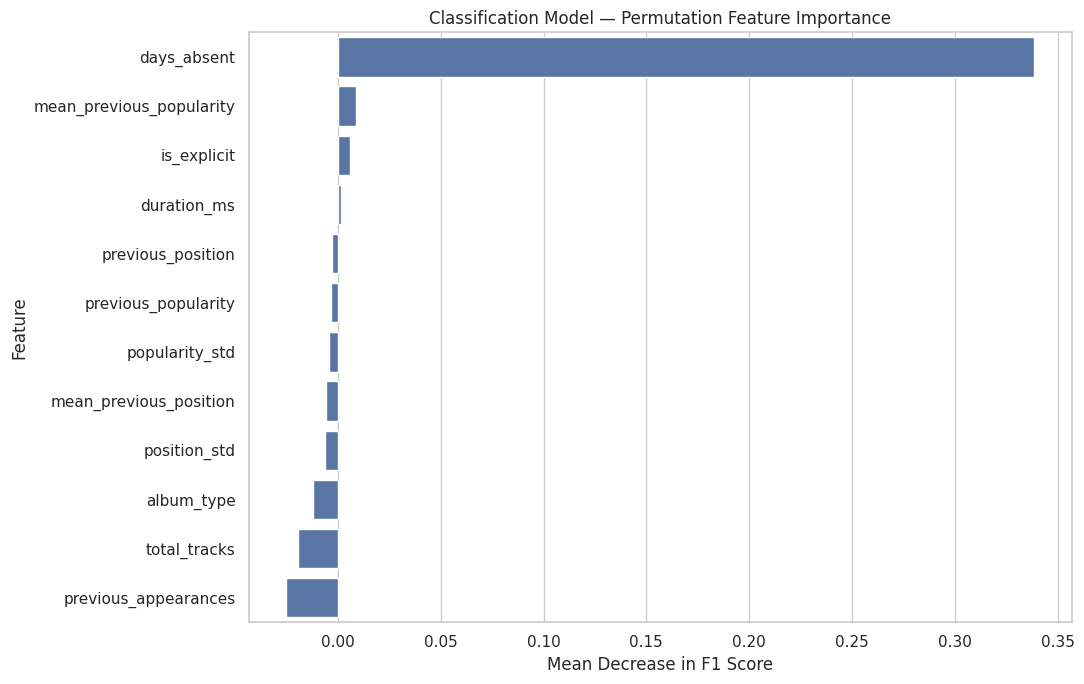


Classification feature importance completed.


In [99]:
# ============================================================
# 18.1 — CLASSIFICATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

# Select best classification model using F1-score
best_classification_name = (
    classification_results_df
    .sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_classification_model = (
    trained_classification_models[best_classification_name]
)

print("Best Classification Model:", best_classification_name)

# Calculate permutation importance
classification_importance = permutation_importance(
    best_classification_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance dataframe
classification_importance_df = pd.DataFrame({

    "Feature": classification_features,

    "Importance": classification_importance.importances_mean,

    "Importance_STD": classification_importance.importances_std

}).sort_values(
    "Importance",
    ascending=False
)

print("\nCLASSIFICATION FEATURE IMPORTANCE")

display(classification_importance_df)

# Visualization
plt.figure(figsize=(11, 7))

sns.barplot(
    data=classification_importance_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Classification Model — Permutation Feature Importance"
)

plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Export results
classification_importance_df.to_csv(
    "South_Korea_Classification_Feature_Importance.csv",
    index=False
)

print("\nClassification feature importance completed.")

Best Regression Model: Random Forest Regressor

REGRESSION FEATURE IMPORTANCE


,Feature,Importance,Importance_STD
0,position,13.541576,0.140632
1,popularity,0.038049,0.004887
2,duration_ms,0.022100,0.008254
3,total_tracks,0.016065,0.004789
5,is_explicit,0.003813,0.001912
4,album_type,0.000847,0.001304


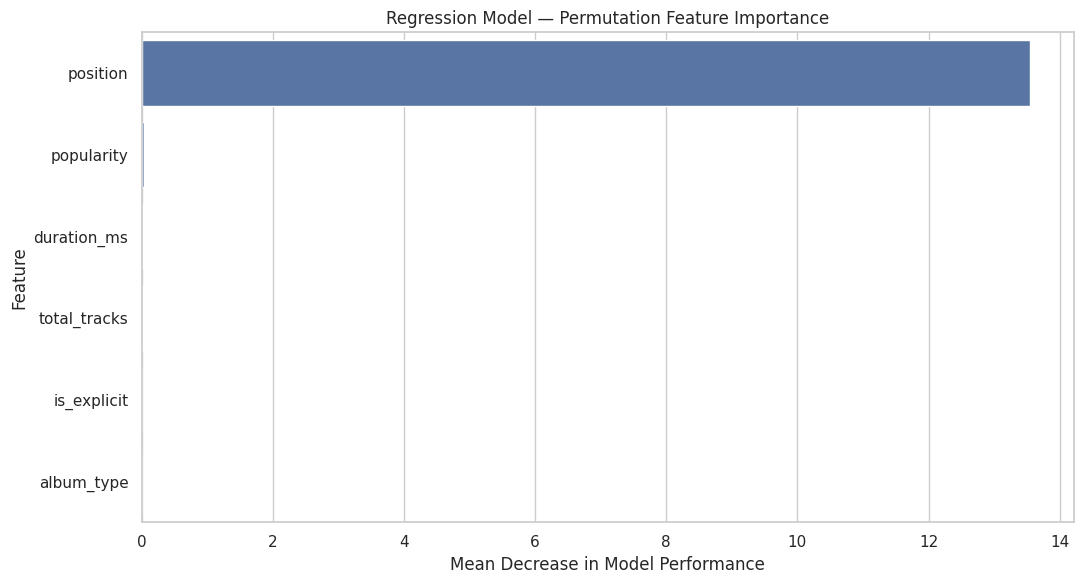


Regression feature importance completed.


In [100]:
# ============================================================
# 18.2 — REGRESSION FEATURE IMPORTANCE
# ============================================================

# Select best regression model using MAE
best_regression_name = (
    regression_results_df
    .sort_values("MAE", ascending=True)
    .iloc[0]["Model"]
)

best_regression_model = (
    trained_regression_models[best_regression_name]
)

print("Best Regression Model:", best_regression_name)

# Calculate permutation importance
regression_importance = permutation_importance(
    best_regression_model,
    X_test_reg,
    y_test_reg,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance dataframe
regression_importance_df = pd.DataFrame({

    "Feature": regression_features,

    "Importance": regression_importance.importances_mean,

    "Importance_STD": regression_importance.importances_std

}).sort_values(
    "Importance",
    ascending=False
)

print("\nREGRESSION FEATURE IMPORTANCE")

display(regression_importance_df)

# Visualization
plt.figure(figsize=(11, 6))

sns.barplot(
    data=regression_importance_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Regression Model — Permutation Feature Importance"
)

plt.xlabel("Mean Decrease in Model Performance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Export results
regression_importance_df.to_csv(
    "South_Korea_Regression_Feature_Importance.csv",
    index=False
)

print("\nRegression feature importance completed.")

MACHINE LEARNING VISUALIZATION


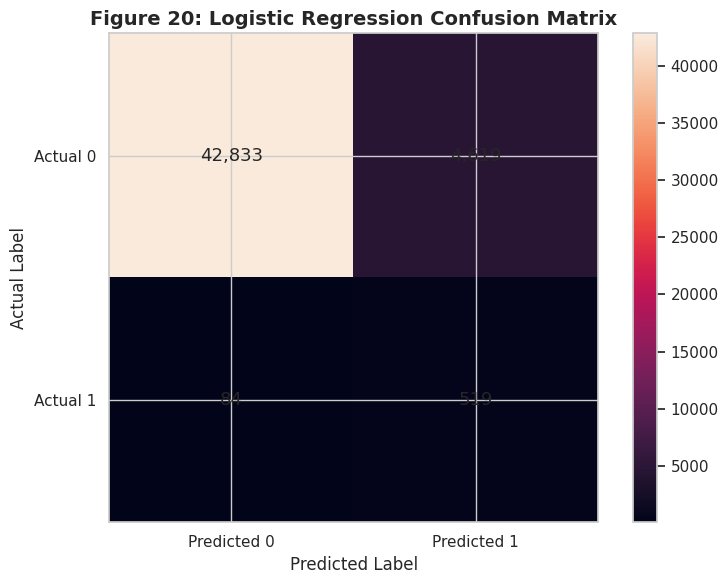

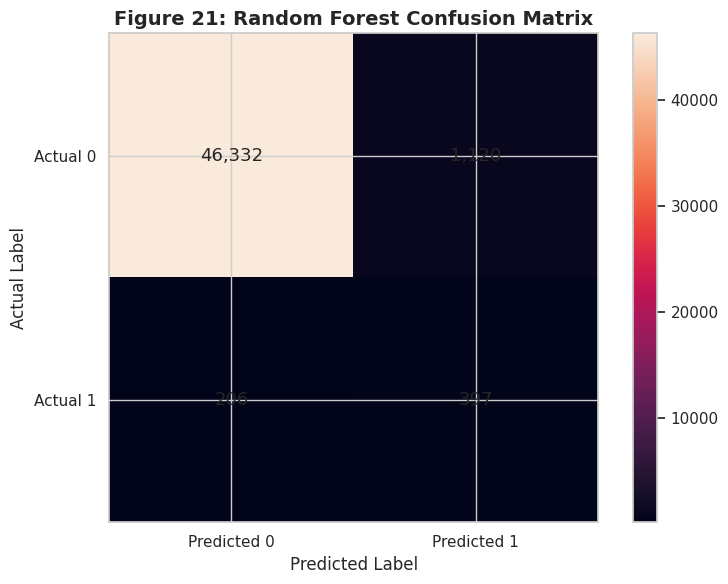

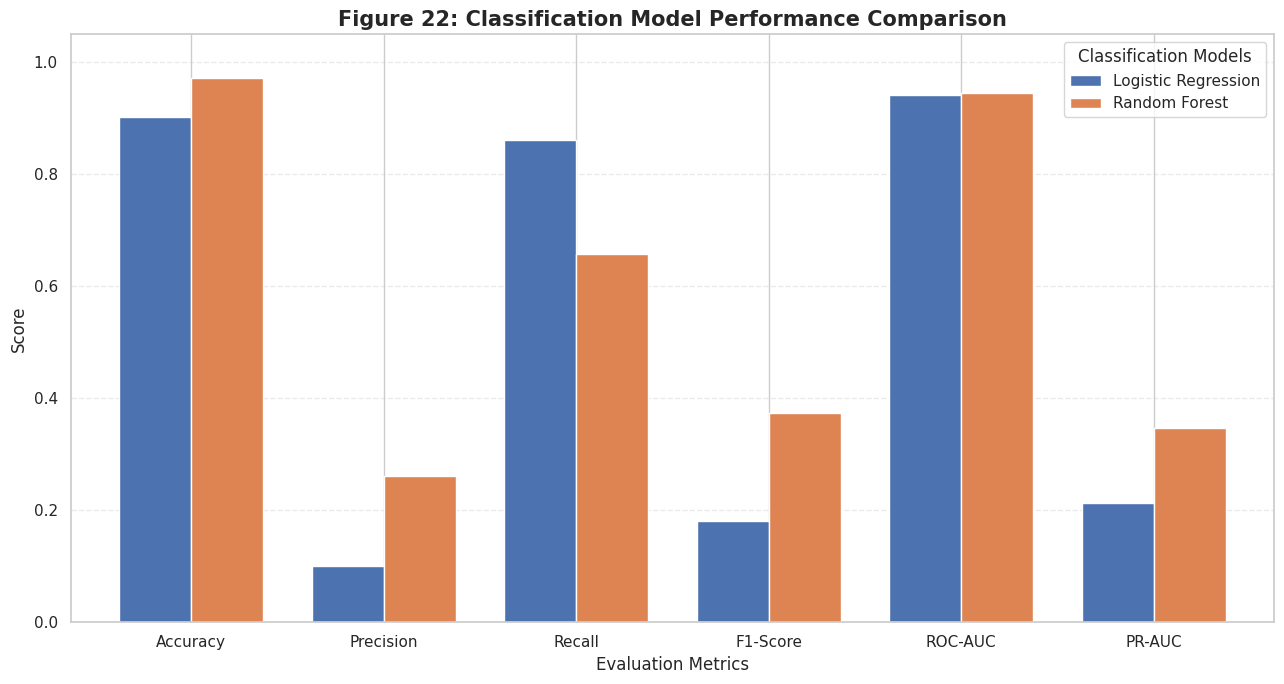

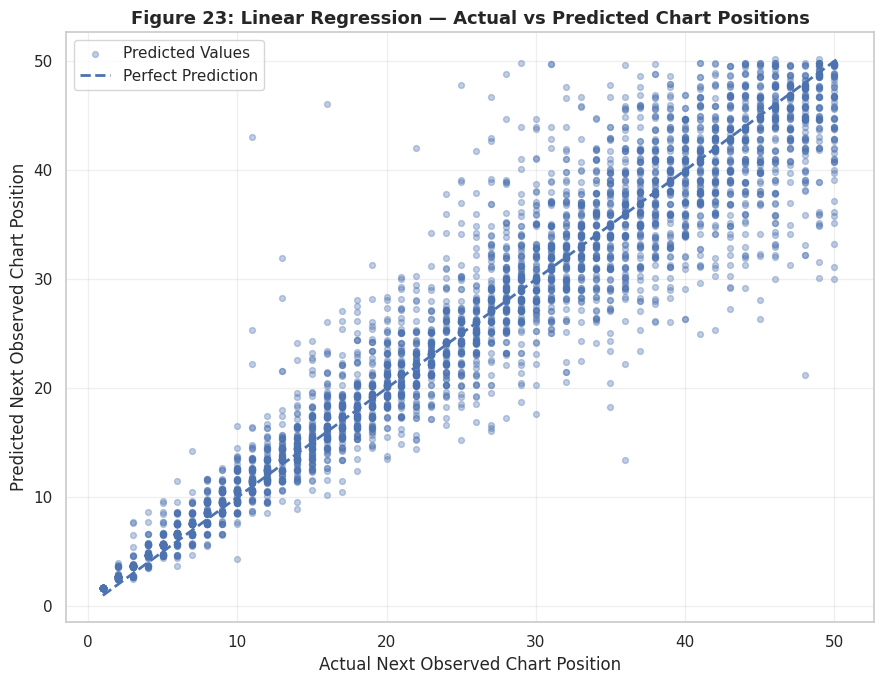

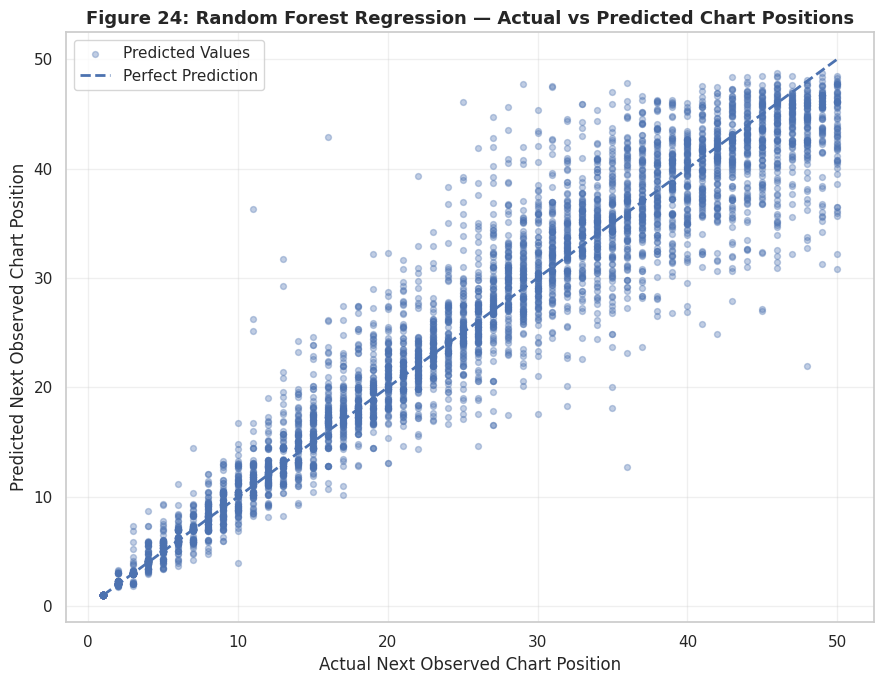

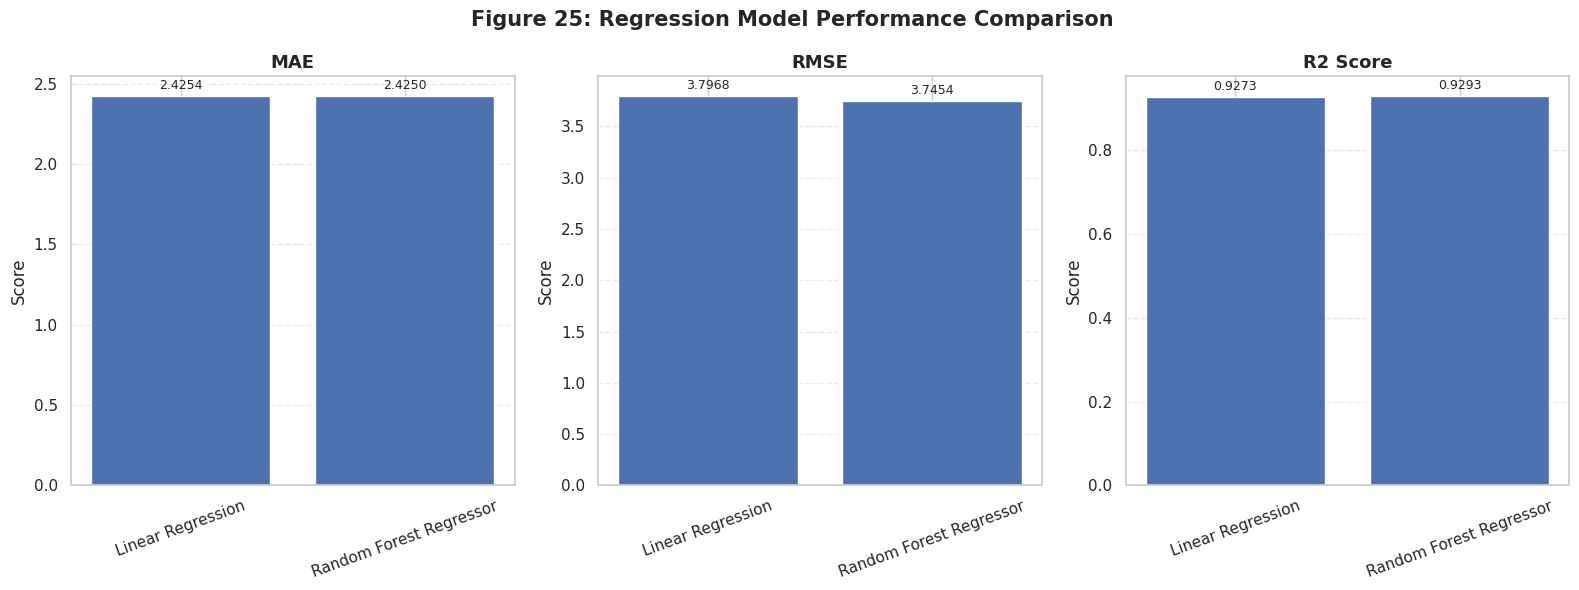


ALL SIX MACHINE LEARNING GRAPHS GENERATED

Figure 20 - Logistic Regression Confusion Matrix
Figure 21 - Random Forest Confusion Matrix
Figure 22 - Classification Model Comparison
Figure 23 - Linear Regression Actual vs Predicted
Figure 24 - Random Forest Actual vs Predicted
Figure 25 - Regression Model Comparison



In [110]:
# ============================================================
# SECTION 18.3 — ADDITIONAL MACHINE LEARNING VISUALIZATIONS
# SOUTH KOREA TOP 50 MUSIC ANALYTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

print("=" * 70)
print("MACHINE LEARNING VISUALIZATION")
print("=" * 70)


# ============================================================
# FIGURE 20 — LOGISTIC REGRESSION CONFUSION MATRIX
# Values taken from the existing notebook results
# ============================================================

cm_logistic = np.array([
    [42833, 4619],
    [84, 519]
])

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm_logistic, interpolation="nearest")

ax.set_title(
    "Figure 20: Logistic Regression Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

fig.colorbar(im, ax=ax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Predicted 0", "Predicted 1"])
ax.set_yticklabels(["Actual 0", "Actual 1"])

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            f"{cm_logistic[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13
        )

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 21 — RANDOM FOREST CONFUSION MATRIX
# Values taken from the existing notebook results
# ============================================================

cm_rf = np.array([
    [46332, 1120],
    [206, 397]
])

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm_rf, interpolation="nearest")

ax.set_title(
    "Figure 21: Random Forest Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

fig.colorbar(im, ax=ax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Predicted 0", "Predicted 1"])
ax.set_yticklabels(["Actual 0", "Actual 1"])

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            f"{cm_rf[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13
        )

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 22 — CLASSIFICATION MODEL COMPARISON
# Values taken from existing model evaluation results
# ============================================================

classification_comparison = pd.DataFrame({
    "Logistic Regression": [
        0.9021, 0.1010, 0.8607,
        0.1808, 0.9412, 0.2127
    ],

    "Random Forest": [
        0.9724, 0.2617, 0.6584,
        0.3745, 0.9456, 0.3463
    ]
}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
])

ax = classification_comparison.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.75
)

ax.set_title(
    "Figure 22: Classification Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Score")

ax.set_ylim(0, 1.05)

ax.legend(
    title="Classification Models",
    loc="best"
)

ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 3. REGRESSION MODEL PREDICTIONS
# Uses existing trained models and test data
# No model retraining
# ============================================================

required_variables = [
    "trained_regression_models",
    "X_test_reg",
    "y_test_reg"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Required existing variables are missing: "
        + ", ".join(missing_variables)
        + ". Run the earlier regression model cells first."
    )

linear_model = trained_regression_models["Linear Regression"]

rf_model = trained_regression_models["Random Forest Regressor"]

actual_values = np.asarray(y_test_reg).ravel()

linear_predictions = np.asarray(
    linear_model.predict(X_test_reg)
).ravel()

rf_predictions = np.asarray(
    rf_model.predict(X_test_reg)
).ravel()

if not (
    len(actual_values)
    == len(linear_predictions)
    == len(rf_predictions)
):
    raise ValueError(
        "Actual and predicted values have different lengths."
    )


# ============================================================
# FIGURE 23 — LINEAR REGRESSION ACTUAL VS PREDICTED
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    actual_values,
    linear_predictions,
    alpha=0.35,
    s=18,
    label="Predicted Values"
)

minimum = min(
    actual_values.min(),
    linear_predictions.min()
)

maximum = max(
    actual_values.max(),
    linear_predictions.max()
)

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

ax.set_title(
    "Figure 23: Linear Regression — Actual vs Predicted Chart Positions",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Actual Next Observed Chart Position")
ax.set_ylabel("Predicted Next Observed Chart Position")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 24 — RANDOM FOREST ACTUAL VS PREDICTED
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    actual_values,
    rf_predictions,
    alpha=0.35,
    s=18,
    label="Predicted Values"
)

minimum = min(
    actual_values.min(),
    rf_predictions.min()
)

maximum = max(
    actual_values.max(),
    rf_predictions.max()
)

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

ax.set_title(
    "Figure 24: Random Forest Regression — Actual vs Predicted Chart Positions",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Actual Next Observed Chart Position")
ax.set_ylabel("Predicted Next Observed Chart Position")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 25 — REGRESSION MODEL PERFORMANCE COMPARISON
# Values taken from existing model evaluation results
# ============================================================

regression_comparison = pd.DataFrame({
    "Linear Regression": [
        2.425368,
        3.796779,
        0.927300
    ],

    "Random Forest Regressor": [
        2.424994,
        3.745373,
        0.929255
    ]

}, index=["MAE", "RMSE", "R2 Score"])


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6)
)

for ax, metric in zip(
    axes,
    regression_comparison.index
):

    values = regression_comparison.loc[metric]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(
        metric,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel("Score")

    ax.tick_params(
        axis="x",
        rotation=20
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.4f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

fig.suptitle(
    "Figure 25: Regression Model Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# FINAL COMPLETION MESSAGE
# ============================================================

print("\n" + "=" * 70)
print("ALL SIX MACHINE LEARNING GRAPHS GENERATED")
print("=" * 70)

print("""
Figure 20 - Logistic Regression Confusion Matrix
Figure 21 - Random Forest Confusion Matrix
Figure 22 - Classification Model Comparison
Figure 23 - Linear Regression Actual vs Predicted
Figure 24 - Random Forest Actual vs Predicted
Figure 25 - Regression Model Comparison
""")


## **19. KPI Definitions and Mathematical Documentation**

In [101]:
# ============================================================
# 19.1 — KPI DEFINITIONS AND MATHEMATICAL DOCUMENTATION
# ============================================================

kpi_documentation = pd.DataFrame({

    "KPI": [
        "Re-entry Frequency",
        "Rank Improvement",
        "Popularity Change",
        "Momentum Intensity",
        "Popularity Spike Sharpness",
        "Rank Recovery Speed",
        "Post-Comeback Retention",
        "Fandom Intensity Proxy"
    ],

    "Mathematical Definition": [

        "Count of detected re-entry events for each song.",

        "Previous Chart Position - Re-entry Chart Position.",

        "Re-entry Popularity - Previous Popularity.",

        "Mean of normalized positive rank improvement "
        "and normalized positive popularity change.",

        "Maximum of positive popularity change divided "
        "by maximum of elapsed calendar days and 1.",

        "Rank improvement from re-entry position to peak "
        "position divided by recovery days, subject to "
        "the zero-day handling rule.",

        "Calendar days between re-entry date and last "
        "observed chart appearance in the comeback run.",

        "Mean of available normalized re-entry frequency, "
        "average popularity spike sharpness and "
        "average rank recovery speed."
    ],

    "Interpretation": [

        "Measures how frequently a song returns to the chart.",

        "Positive values indicate improvement in chart position.",

        "Positive values indicate an increase in Spotify popularity.",

        "Higher scores indicate stronger combined positive "
        "rank and popularity changes.",

        "Measures positive popularity change relative to "
        "the elapsed time between chart appearances.",

        "Measures chart-position improvement per calendar day.",

        "Measures observed chart retention after comeback.",

        "Provides a composite chart-based indicator of "
        "repeated activity and comeback-related performance."
    ],

    "Scale / Unit": [

        "Event count",
        "Chart positions",
        "Popularity points",
        "0-100",
        "Popularity points per calendar day",
        "Chart positions per calendar day",
        "Calendar days",
        "0-100"
    ],

    "Limitations": [

        "Depends on chart coverage and re-entry detection.",

        "Does not establish the reason for rank movement.",

        "Spotify popularity is not a direct stream count.",

        "Depends on min-max normalization and selected components.",

        "Does not directly measure listener activity or engagement.",

        "Can be undefined when positive improvement occurs "
        "on the re-entry date itself.",

        "May be right-censored at the end of the dataset.",

        "Not a direct measurement of audience loyalty, "
        "fan behaviour or actual fandom size."
    ]

})

print("=" * 80)
print("KPI DEFINITIONS AND MATHEMATICAL DOCUMENTATION")
print("=" * 80)

display(kpi_documentation)

kpi_documentation.to_csv(
    "South_Korea_KPI_Documentation.csv",
    index=False
)

print("\nKPI documentation exported successfully.")

KPI DEFINITIONS AND MATHEMATICAL DOCUMENTATION


,KPI,Mathematical Definition,Interpretation,Scale / Unit,Limitations
0,Re-entry Frequency,Count of detected re-entry events for each song.,Measures how frequently a song returns to the ...,Event count,Depends on chart coverage and re-entry detection.
1,Rank Improvement,Previous Chart Position - Re-entry Chart Posit...,Positive values indicate improvement in chart ...,Chart positions,Does not establish the reason for rank movement.
2,Popularity Change,Re-entry Popularity - Previous Popularity.,Positive values indicate an increase in Spotif...,Popularity points,Spotify popularity is not a direct stream count.
3,Momentum Intensity,Mean of normalized positive rank improvement a...,Higher scores indicate stronger combined posit...,0-100,Depends on min-max normalization and selected ...
4,Popularity Spike Sharpness,Maximum of positive popularity change divided ...,Measures positive popularity change relative t...,Popularity points per calendar day,Does not directly measure listener activity or...
5,Rank Recovery Speed,Rank improvement from re-entry position to pea...,Measures chart-position improvement per calend...,Chart positions per calendar day,Can be undefined when positive improvement occ...
6,Post-Comeback Retention,Calendar days between re-entry date and last o...,Measures observed chart retention after comeback.,Calendar days,May be right-censored at the end of the dataset.
7,Fandom Intensity Proxy,Mean of available normalized re-entry frequenc...,Provides a composite chart-based indicator of ...,0-100,"Not a direct measurement of audience loyalty, ..."



KPI documentation exported successfully.


## **20. Key Insights and Recommendations**

In [102]:
# ============================================================
# 20.1 — KEY INSIGHTS AND RECOMMENDATIONS
# ============================================================

recommendations = [

    {
        "Finding": "Repeated Chart Re-Entry",

        "Observation": (
            "A total of 874 re-entry events were identified "
            "across the observed chart period. "
            "Our Blues, Our Life by Lim Young Woong "
            "recorded the highest re-entry frequency with 28 events."
        ),

        "Recommendation": (
            "Monitor frequently returning songs and artists "
            "to understand recurring chart activity."
        )
    },

    {
        "Finding": "Comeback Momentum",

        "Observation": (
            "Momentum intensity combines normalized positive "
            "rank improvement and popularity change. "
            "The score provides a comparative measure of "
            "comeback performance."
        ),

        "Recommendation": (
            "Evaluate rank improvement and popularity change "
            "together when comparing comeback events."
        )
    },

    {
        "Finding": "Post-Comeback Retention",

        "Observation": (
            "Average observed post-comeback retention was "
            "approximately 8.86 calendar days. "
            "Observations near the dataset end may be right-censored."
        ),

        "Recommendation": (
            "Compare observed retention across songs and artists "
            "while accounting for incomplete observation periods."
        )
    },

    {
        "Finding": "Album vs Single Performance",

        "Observation": (
            "Singles recorded higher average comeback momentum "
            "than albums in the descriptive analysis. "
            "However, the Mann-Whitney U test did not identify "
            "a statistically significant difference "
            "(p = 0.625480)."
        ),

        "Recommendation": (
            "Treat the observed difference as descriptive rather "
            "than conclusive evidence of a format-related effect."
        )
    },

    {
        "Finding": "Explicit vs Clean Momentum",

        "Observation": (
            "The song-level Mann-Whitney U test identified "
            "a statistically significant difference between "
            "explicit and clean song groups (p = 0.00950). "
            "The explicit group contained only 19 songs."
        ),

        "Recommendation": (
            "Interpret this association cautiously because the "
            "explicit group is relatively small. "
            "The result does not establish causation."
        )
    },

    {
        "Finding": "Fandom Intensity Proxy",

        "Observation": (
            "The proxy combines normalized re-entry frequency, "
            "popularity spike sharpness and rank recovery speed."
        ),

        "Recommendation": (
            "Use the proxy as a chart-based monitoring indicator, "
            "not as a direct measurement of audience loyalty."
        )
    },

    {
        "Finding": "Classification Model Performance",

        "Observation": (
            "Random Forest achieved an F1-score of approximately "
            "0.3773 and PR-AUC of approximately 0.3530 "
            "on the chronological test period."
        ),

        "Recommendation": (
            "Use precision-recall evaluation and monitor false "
            "positives when applying comeback predictions."
        )
    },

    {
        "Finding": "Regression Model Performance",

        "Observation": (
            "Random Forest Regressor achieved an MAE of "
            "approximately 2.4245 chart positions and "
            "an R-squared score of approximately 0.9293 "
            "on the chronological test period."
        ),

        "Recommendation": (
            "Use the model as an analytical forecasting aid "
            "and validate its performance on newer chart periods."
        )
    },

    {
        "Finding": "Model Feature Importance",

        "Observation": (
            "Days absent was the strongest classification feature, "
            "while current chart position was the strongest "
            "regression feature."
        ),

        "Recommendation": (
            "Use these findings to understand model behaviour "
            "without interpreting feature importance as causation."
        )
    }

]

recommendations_df = pd.DataFrame(recommendations)

display(recommendations_df)

recommendations_df.to_csv(
    "South_Korea_Insights_and_Recommendations.csv",
    index=False
)

print("\nUpdated insights and recommendations exported successfully.")

,Finding,Observation,Recommendation
0,Repeated Chart Re-Entry,A total of 874 re-entry events were identified...,Monitor frequently returning songs and artists...
1,Comeback Momentum,Momentum intensity combines normalized positiv...,Evaluate rank improvement and popularity chang...
2,Post-Comeback Retention,Average observed post-comeback retention was a...,Compare observed retention across songs and ar...
3,Album vs Single Performance,Singles recorded higher average comeback momen...,Treat the observed difference as descriptive r...
4,Explicit vs Clean Momentum,The song-level Mann-Whitney U test identified ...,Interpret this association cautiously because ...
5,Fandom Intensity Proxy,The proxy combines normalized re-entry frequen...,Use the proxy as a chart-based monitoring indi...
6,Classification Model Performance,Random Forest achieved an F1-score of approxim...,Use precision-recall evaluation and monitor fa...
7,Regression Model Performance,Random Forest Regressor achieved an MAE of app...,Use the model as an analytical forecasting aid...
8,Model Feature Importance,Days absent was the strongest classification f...,Use these findings to understand model behavio...



Updated insights and recommendations exported successfully.


## **21. Limitations and Future Scope**

In [103]:
# ============================================================
# 21.1 — UPDATED PROJECT LIMITATIONS AND FUTURE SCOPE
# ============================================================

limitations = [

    "The analysis excludes chart records dated 1 March 2025 "
    "due to unresolved duplicate chart snapshots.",

    "Re-entry events spanning the excluded date require "
    "cautious interpretation.",

    "Retention observations active at the end of the dataset "
    "are right-censored.",

    "The fandom intensity score is a chart-based proxy and "
    "not a direct measurement of audience loyalty or behaviour.",

    "The explicit-content statistical comparison includes "
    "only 19 explicit songs, limiting the strength and "
    "generalizability of the comparison.",

    "Statistical tests identify associations and do not "
    "establish causal relationships.",

    "Classification data has an imbalanced target distribution, "
    "which affects precision, recall and prediction reliability.",

    "Classification and regression performance is evaluated "
    "on a chronological holdout period and may change "
    "on future chart observations.",

    "The regression model relies heavily on current chart "
    "position, which is an important predictor of subsequent "
    "observed chart position.",

    "The dataset does not provide direct streaming counts, "
    "listener demographics or social media engagement.",

    "Feature importance describes predictive usefulness "
    "within the evaluated models and does not establish causation."
]

future_scope = [

    "Integrate streaming and listener engagement data.",

    "Include social media engagement indicators.",

    "Evaluate models on newer chart periods.",

    "Explore additional time-series forecasting methods.",

    "Investigate classification threshold selection "
    "using a separate chronological validation period.",

    "Explore additional evaluation methods for imbalanced "
    "classification datasets.",

    "Conduct further statistical analysis with larger "
    "and more balanced content-category samples.",

    "Develop an interactive Streamlit analytics dashboard.",

    "Monitor model performance as new chart observations "
    "become available."
]

print("=" * 80)
print("PROJECT LIMITATIONS")
print("=" * 80)

for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")

print("\n" + "=" * 80)
print("FUTURE SCOPE")
print("=" * 80)

for i, item in enumerate(future_scope, 1):
    print(f"{i}. {item}")

# Export documentation
limitations_df = pd.DataFrame({
    "Limitation": limitations
})

future_scope_df = pd.DataFrame({
    "Future Scope": future_scope
})

limitations_df.to_csv(
    "South_Korea_Project_Limitations.csv",
    index=False
)

future_scope_df.to_csv(
    "South_Korea_Future_Scope.csv",
    index=False
)

print("\nLimitations and future scope exported successfully.")

PROJECT LIMITATIONS
1. The analysis excludes chart records dated 1 March 2025 due to unresolved duplicate chart snapshots.
2. Re-entry events spanning the excluded date require cautious interpretation.
3. Retention observations active at the end of the dataset are right-censored.
4. The fandom intensity score is a chart-based proxy and not a direct measurement of audience loyalty or behaviour.
5. The explicit-content statistical comparison includes only 19 explicit songs, limiting the strength and generalizability of the comparison.
6. Statistical tests identify associations and do not establish causal relationships.
7. Classification data has an imbalanced target distribution, which affects precision, recall and prediction reliability.
8. Classification and regression performance is evaluated on a chronological holdout period and may change on future chart observations.
9. The regression model relies heavily on current chart position, which is an important predictor of subsequent obse

## **22. Final Project Conclusion**

In [104]:
# ============================================================
# 22.1 — FINAL PROJECT CONCLUSION
# ============================================================

print("=" * 90)

print(
    "COMEBACK MOMENTUM, CHART RE-ENTRY, AND "
    "FANDOM INTENSITY ANALYSIS OF SOUTH KOREA TOP 50 PLAYLIST"
)

print("=" * 90)

# ------------------------------------------------------------
# 1. PROJECT SUMMARY
# ------------------------------------------------------------

print("\n1. PROJECT SUMMARY")
print("-" * 90)

print(
    f"The analysis covered {len(chart_df):,} chart records "
    f"across {chart_df['date'].nunique():,} observed chart dates."
)

print(
    f"The dataset included "
    f"{chart_df['song_artist_id'].nunique():,} unique songs "
    f"and {chart_df['artist'].nunique():,} artists."
)

print(
    f"A total of {len(reentry_df):,} potential re-entry events "
    "were identified."
)

print(
    "Average observed post-comeback retention:",
    round(retention_df["retention_calendar_days"].mean(), 2),
    "calendar days"
)

# ------------------------------------------------------------
# 2. KEY STATISTICAL FINDINGS
# ------------------------------------------------------------

print("\n2. KEY STATISTICAL FINDINGS")
print("-" * 90)

print(
    "Album vs Single: No statistically significant difference "
    "was detected (p = 0.625480)."
)

print(
    "Explicit vs Clean: The song-level comparison detected "
    "a statistically significant difference (p = 0.009502)."
)

print(
    "The explicit group contained 19 songs, so this finding "
    "should be interpreted cautiously."
)

# ------------------------------------------------------------
# 3. CLASSIFICATION MODEL RESULTS
# ------------------------------------------------------------

print("\n3. CLASSIFICATION MODEL RESULTS")
print("-" * 90)

display(classification_results_df)

# ------------------------------------------------------------
# 4. REGRESSION MODEL RESULTS
# ------------------------------------------------------------

print("\n4. REGRESSION MODEL RESULTS")
print("-" * 90)

display(regression_results_df)

# ------------------------------------------------------------
# 5. FEATURE IMPORTANCE
# ------------------------------------------------------------

print("\n5. MODEL FEATURE IMPORTANCE")
print("-" * 90)

print(
    "Classification: days_absent was the strongest "
    "permutation-importance feature."
)

print(
    "Regression: current chart position was the strongest "
    "permutation-importance feature."
)

# ------------------------------------------------------------
# 6. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n6. FINAL CONCLUSION")
print("-" * 90)

print(
    "This project examined chart re-entry, comeback momentum, "
    "post-comeback retention and chart-based fandom intensity "
    "patterns in the South Korea Top 50 playlist."
)

print(
    "The analysis combined exploratory data analysis, "
    "statistical hypothesis testing, KPI development and "
    "machine-learning models."
)

print(
    "The chronological classification and regression evaluations "
    "provided an assessment of model performance on later "
    "observed chart periods."
)

print(
    "The findings indicate that days absent is an important "
    "predictive feature for comeback classification, while "
    "current chart position strongly influences subsequent "
    "observed chart position."
)

print(
    "All findings should be interpreted within the limitations "
    "of the dataset, statistical assumptions and evaluation period."
)

print(
    "\nPROJECT NOTEBOOK ANALYSIS COMPLETED SUCCESSFULLY."
)

print("=" * 90)

COMEBACK MOMENTUM, CHART RE-ENTRY, AND FANDOM INTENSITY ANALYSIS OF SOUTH KOREA TOP 50 PLAYLIST

1. PROJECT SUMMARY
------------------------------------------------------------------------------------------
The analysis covered 27,700 chart records across 554 observed chart dates.
The dataset included 537 unique songs and 194 artists.
A total of 874 potential re-entry events were identified.
Average observed post-comeback retention: 8.86 calendar days

2. KEY STATISTICAL FINDINGS
------------------------------------------------------------------------------------------
Album vs Single: No statistically significant difference was detected (p = 0.625480).
Explicit vs Clean: The song-level comparison detected a statistically significant difference (p = 0.009502).
The explicit group contained 19 songs, so this finding should be interpreted cautiously.

3. CLASSIFICATION MODEL RESULTS
------------------------------------------------------------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.902133,0.101012,0.860697,0.180805,0.941202,0.212719
1,Random Forest,0.972386,0.261842,0.660033,0.374941,0.944395,0.343225



4. REGRESSION MODEL RESULTS
------------------------------------------------------------------------------------------


,Model,MAE,RMSE,R2 Score
0,Linear Regression,2.425368,3.796779,0.927300
1,Random Forest Regressor,2.424994,3.745373,0.929255



5. MODEL FEATURE IMPORTANCE
------------------------------------------------------------------------------------------
Classification: days_absent was the strongest permutation-importance feature.
Regression: current chart position was the strongest permutation-importance feature.

6. FINAL CONCLUSION
------------------------------------------------------------------------------------------
This project examined chart re-entry, comeback momentum, post-comeback retention and chart-based fandom intensity patterns in the South Korea Top 50 playlist.
The analysis combined exploratory data analysis, statistical hypothesis testing, KPI development and machine-learning models.
The chronological classification and regression evaluations provided an assessment of model performance on later observed chart periods.
The findings indicate that days absent is an important predictive feature for comeback classification, while current chart position strongly influences subsequent observed chart posit

## **23. Final Export and Reproducibility**

In [105]:
# ============================================================
# 23.1 — FINAL EXPORT AND REPRODUCIBILITY
# ============================================================

import os
import zipfile
import pandas as pd
import numpy as np

print("=" * 80)
print("FINAL PROJECT EXPORT AND REPRODUCIBILITY")
print("=" * 80)

# ------------------------------------------------------------
# 1. SAVE UPDATED ANALYSIS TABLES
# ------------------------------------------------------------

export_tables = {

    "South_Korea_Classification_Model_Results.csv":
        classification_results_df,

    "South_Korea_Regression_Model_Results.csv":
        regression_results_df,

    "South_Korea_Classification_Feature_Importance.csv":
        classification_importance_df,

    "South_Korea_Regression_Feature_Importance.csv":
        regression_importance_df,

    "South_Korea_KPI_Documentation.csv":
        kpi_documentation,

    "South_Korea_Insights_and_Recommendations.csv":
        recommendations_df,

    "South_Korea_Project_Limitations.csv":
        limitations_df,

    "South_Korea_Future_Scope.csv":
        future_scope_df,

    "South_Korea_Momentum_Validation.csv":
        momentum_validation_df,

    "South_Korea_Explicit_Clean_Event_Analysis.csv":
        explicit_test_df,

    "South_Korea_Song_Level_Explicit_Clean_Analysis.csv":
        song_level_df
}

for filename, dataframe in export_tables.items():

    dataframe.to_csv(filename, index=False)

    print("Exported:", filename)


# ------------------------------------------------------------
# 2. FINAL DATASET VALIDATION
# ------------------------------------------------------------

validation_checks = []

# Dataset record count
validation_checks.append({
    "Check": "Chart dataset contains records",
    "Status": len(chart_df) > 0
})

# Missing values
validation_checks.append({
    "Check": "Chart dataset has no missing values",
    "Status": chart_df.isna().sum().sum() == 0
})

# Duplicate records
validation_checks.append({
    "Check": "No duplicate chart records",
    "Status": chart_df.duplicated().sum() == 0
})

# Exactly 50 records per chart date
daily_counts = chart_df.groupby("date").size()

validation_checks.append({
    "Check": "Every chart date contains 50 records",
    "Status": daily_counts.eq(50).all()
})

# Exactly 50 unique positions
daily_positions = chart_df.groupby("date")["position"].nunique()

validation_checks.append({
    "Check": "Every chart date contains 50 unique positions",
    "Status": daily_positions.eq(50).all()
})

# Re-entry and momentum validation
validation_checks.append({
    "Check": "Momentum validation passed",
    "Status": (momentum_validation_df["Status"] == "PASS").all()
})

# Classification models
validation_checks.append({
    "Check": "Classification models evaluated",
    "Status": len(classification_results_df) == 2
})

# Regression models
validation_checks.append({
    "Check": "Regression models evaluated",
    "Status": len(regression_results_df) == 2
})

final_audit_df = pd.DataFrame(validation_checks)

final_audit_df["Status"] = final_audit_df["Status"].map({
    True: "PASS",
    False: "CHECK"
})

print("\nFINAL VALIDATION REPORT")

display(final_audit_df)

overall_status = (
    "PASS"
    if (final_audit_df["Status"] == "PASS").all()
    else "CHECK"
)

print("\nOVERALL PROJECT AUDIT:", overall_status)

final_audit_df.to_csv(
    "South_Korea_Final_Project_Audit.csv",
    index=False
)


# ------------------------------------------------------------
# 3. CREATE FINAL EXPORT PACKAGE
# ------------------------------------------------------------

export_files = [
    filename
    for filename in export_tables
    if os.path.exists(filename)
]

export_files.append("South_Korea_Final_Project_Audit.csv")

zip_filename = "South_Korea_Top_50_Final_Analysis.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in export_files:
        zip_file.write(filename)

print("\nFINAL EXPORT PACKAGE CREATED:", zip_filename)

print("\nFiles included:", len(export_files))

print("\nPROJECT EXPORT COMPLETED.")

FINAL PROJECT EXPORT AND REPRODUCIBILITY
Exported: South_Korea_Classification_Model_Results.csv
Exported: South_Korea_Regression_Model_Results.csv
Exported: South_Korea_Classification_Feature_Importance.csv
Exported: South_Korea_Regression_Feature_Importance.csv
Exported: South_Korea_KPI_Documentation.csv
Exported: South_Korea_Insights_and_Recommendations.csv
Exported: South_Korea_Project_Limitations.csv
Exported: South_Korea_Future_Scope.csv
Exported: South_Korea_Momentum_Validation.csv
Exported: South_Korea_Explicit_Clean_Event_Analysis.csv
Exported: South_Korea_Song_Level_Explicit_Clean_Analysis.csv

FINAL VALIDATION REPORT


,Check,Status
0,Chart dataset contains records,PASS
1,Chart dataset has no missing values,PASS
2,No duplicate chart records,PASS
3,Every chart date contains 50 records,PASS
4,Every chart date contains 50 unique positions,PASS
5,Momentum validation passed,PASS
6,Classification models evaluated,PASS
7,Regression models evaluated,PASS



OVERALL PROJECT AUDIT: PASS

FINAL EXPORT PACKAGE CREATED: South_Korea_Top_50_Final_Analysis.zip

Files included: 12

PROJECT EXPORT COMPLETED.


In [106]:
import pandas as pd

required_variables = [
    "chart_df",
    "reentry_df",
    "reentry_events_df",
    "retention_df",
    "fandom_leaderboard",
    "momentum_kpi",
    "classification_results_df",
    "regression_results_df",
    "classification_importance_df",
    "regression_importance_df",
    "kpi_documentation",
    "recommendations_df",
    "limitations_df",
    "future_scope_df",
    "momentum_validation_df",
    "explicit_test_df",
    "song_level_df",
    "final_audit_df"
]

print("========== DASHBOARD DATA EXPORT CHECK ==========")

for name in required_variables:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):
            print(f"✅ {name}: DataFrame | Rows: {len(obj)} | Columns: {len(obj.columns)}")
        else:
            print(f"⚠️ {name}: Exists, but is not a DataFrame")
    else:
        print(f"❌ {name}: Not found")

print("==================================================")

========== DASHBOARD DATA EXPORT CHECK ==========
✅ chart_df: DataFrame | Rows: 27700 | Columns: 11
✅ reentry_df: DataFrame | Rows: 874 | Columns: 7
✅ reentry_events_df: DataFrame | Rows: 874 | Columns: 9
✅ retention_df: DataFrame | Rows: 874 | Columns: 8
✅ fandom_leaderboard: DataFrame | Rows: 230 | Columns: 10
✅ momentum_kpi: DataFrame | Rows: 230 | Columns: 5
✅ classification_results_df: DataFrame | Rows: 2 | Columns: 7
✅ regression_results_df: DataFrame | Rows: 2 | Columns: 4
✅ classification_importance_df: DataFrame | Rows: 12 | Columns: 3
✅ regression_importance_df: DataFrame | Rows: 6 | Columns: 3
✅ kpi_documentation: DataFrame | Rows: 8 | Columns: 5
✅ recommendations_df: DataFrame | Rows: 9 | Columns: 3
✅ limitations_df: DataFrame | Rows: 11 | Columns: 1
✅ future_scope_df: DataFrame | Rows: 9 | Columns: 1
✅ momentum_validation_df: DataFrame | Rows: 6 | Columns: 3
✅ explicit_test_df: DataFrame | Rows: 874 | Columns: 22
✅ song_level_df: DataFrame | Rows: 230 | Columns: 4
✅ final_